In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torch.optim as optim
from scipy.stats import norm
import os

from model import *
from data import generate_gmm_data
from train_utils import train

from plot import *
from utils import *


In [2]:
device = 'cuda:0' if torch.cuda.is_available() else 'cpu'
print(device)

cuda:0


In [3]:
relu = lambda X: np.maximum(X, 0)
d_relu = lambda X: np.maximum(np.sign(X), 0)

elu = lambda X, alpha=1.0: ( alpha * (np.exp(X) - 1) ) * (X <= 0) + (X * (X > 0))
d_elu = lambda X, alpha=1.0: ( alpha * np.exp(X) ) * (X <= 0) + (X > 0)

gelu = lambda X: X * norm.cdf(X)
d_gelu = lambda X: norm.cdf(X) + X * norm.pdf(X)

sigmoid = lambda X: 1 / (1 + np.exp(-X))
d_sigmoid = lambda X: sigmoid(X) * (1 - sigmoid(X))

silu = lambda X: X * sigmoid(X)
d_silu = lambda X: sigmoid(X) + X * d_sigmoid(X)

leaky_relu = lambda X, slope=0.01: slope * np.minimum(X, 0) + np.maximum(X, 0)
d_leaky_relu = lambda X, slope=0.01: slope * (X <= 0) + (X > 0).astype(float)

identity = lambda X: X
d_identity = lambda X: np.ones(X.shape)

abs_ = lambda X: np.abs(X)
d_abs_ = lambda X: -1 * (X <= 0) + (X > 0)

softplus = lambda X: np.log(1 + np.exp(X))
d_softplus = lambda X: sigmoid(X)
d2_softplus = lambda X: d_sigmoid(X)

leaky_softplus = lambda X, slope=0.01: slope * X + (1 - slope) * (softplus(X) - np.log(2))
d_leaky_softplus = lambda X, slope=0.01: slope + (1 - slope) * (d_softplus(X))
d2_leaky_softplus = lambda X, slope = 0.01: (1 - slope) * d2_softplus(X)


smooth_abs = lambda X, beta = 10: (2 / beta) * softplus(X) - X - ( (2 / beta) * np.log(2) )
d_smooth_abs = lambda X, beta = 10: (2 / beta) * d_softplus(X) - 1

custom_activations_map = {'ReLU': [relu, d_relu],
               'Leaky-Softplus': [leaky_softplus, d_leaky_softplus], 
               'ELU': [elu, d_elu],
               'GELU': [gelu, d_gelu],
               'SiLU': [silu, d_silu],
               'Leaky-ReLU': [leaky_relu, d_leaky_relu],
               'Abs': [abs_, d_abs_],
               'SmoothAbs': [smooth_abs, d_smooth_abs],
               'Identity': [identity, d_identity]}

In [4]:
optimizer_map = {'SGD': optim.SGD,
                'Adam': optim.Adam}

# Model Training

In [5]:
def get_data(d: int, 
             K: int, 
             N_k: int, 
             scale: float = 1.0,
             nu: float = 1.0,
             normalize_: bool = False, 
             orthogonalize_: bool = False,
             whiten_: bool = False):
    
    
    N = K * N_k
    
    # d > N --> random Gaussian data
    if d >= N:
        train_set, train_loader, _ = generate_random_data(d, 
                                                       K, 
                                                       N_k, 
                                                       orthogonalize_ = orthogonalize_, 
                                                       normalize_ = normalize_)
        val_loader = train_loader 
    
    # N > d --> Gaussian mixture data
    elif N > d:
        train_set, train_loader, _ = generate_gmm_data(d, 
                                                    K, 
                                                    N_k,
                                                    nu=nu,
                                                    data_scale = scale,
                                                    whiten_ = whiten_, 
                                                    normalize_ = normalize_)
        val_loader = train_loader
    
    
    X = train_set.samples.T
    Y = train_set.targets.T
    
    return train_loader, val_loader, X, Y

In [6]:
def train_model(num_layers: int,
                data_dim: int, 
                hidden_dim: int, 
                num_classes: int, 
                act_fn_str: str, 
                train_loader, 
                val_loader, 
                epochs, 
                lr, 
                freq,
                loss_fn, 
                optimizer_type='SGD', 
                freeze_last_layer=True, 
                residual=False, 
                batchnorm=False, 
                init_method='orthogonal',
                last_layer_init_method='orthogonal',
                init_scale=1):
    
    
    # Train model
    model = MLP(num_layers, 
                data_dim, 
                hidden_dim, 
                num_classes, 
                act_fn_str, 
                freeze_last_layer=freeze_last_layer,
                diff_init_last_layer=True,
                residual=residual, 
                batchnorm=batchnorm, 
                init_method=init_method, 
                last_layer_init_method=last_layer_init_method,
                init_scale=init_scale)

    model = model.to(device)
    
    # Training
    criterion = loss_map[loss_fn]
    optimizer = optimizer_map[optimizer_type](model.parameters(), lr=lr, weight_decay=0)
    scheduler = None
    #scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, epochs, eta_min=0)
    results = train(model, 
                    criterion, 
                    optimizer, 
                    train_loader, 
                    val_loader, 
                    epochs, 
                    device,
                    scheduler=scheduler, 
                    return_weights=True,
                    return_grads=True,
                    return_outs=True)


    weights = results['all_weights']
    grads = results['all_grads']
    outs = results['all_outs']
    train_losses = results['train_losses']
    
    return weights, grads, outs, train_losses #outs, train_losses

# Weight decompositions during training

In [7]:
def fro_inner_product(X: np.ndarray, Y: np.ndarray):
    assert X.shape == Y.shape
    
    X_norm = np.linalg.norm(X, ord='fro')
    Y_norm = np.linalg.norm(Y, ord='fro')
    
    return np.trace(X.T @ Y) / (X_norm * Y_norm)

def normalized_dist(X: np.ndarray, Y: np.ndarray, norm_factor: float = 1.0):
    assert X.shape == Y.shape
    
    return np.linalg.norm(X - Y)**2 / norm_factor 

def normalized_norms(X: np.ndarray):
    return normalized_dist(X, np.zeros(X.shape))

def sin_theta_norms(U1: np.ndarray, U2: np.ndarray):
    svals = np.linalg.svd(U1.T @ U2, compute_uv=False)
    angles = np.arccos(np.clip(svals, 0, 1))
    
    return np.linalg.norm(np.sin(angles))

In [8]:
'''
Helper function to calculate the norm of each component in the weight matrix 
'''
def weight_decomp_norms_dists(weights, grads, K, init_scale, epochs):
    
    # Get "small update subspace"
    W1_0 = weights[0][0]
    d = W1_0.shape[-1]
    G1_0 = grads[0][0]
    
    L0, s0, R0 = np.linalg.svd(G1_0, full_matrices=True)
    R0 = R0.T
    
    L0_1 = L0[:, :K]
    R0_1 = R0[:, :K]
    
    
    U_null, V_null = small_update_subspace(W1_0, G1_0, K, init_scale)
    p = U_null.shape[-1]
    

    # Get "large update subspace"
    U_update = np.linalg.svd(U_null, full_matrices=True)[0][:, p:]
    V_update = np.linalg.svd(V_null, full_matrices=True)[0][:, p:]
    
    
    # Concatenate two subspaces to create orthogonal matrices
    U = np.concatenate((U_update, U_null), axis=1)
    V = np.concatenate((V_update, V_null), axis=1)

    
    # Get initial weight factors
    W1_0 = weights[0][0]
    
    W11_0_tilde = U_update.T @ W1_0 @ V_update
    W12_0_tilde = U_update.T @ W1_0 @ V_null
    W13_0_tilde = U_null.T @ W1_0 @ V_update
    W14_0_tilde = U_null.T @ W1_0 @ V_null

    
    # Calculate weight decomposition norms and distance from initialization
    # for all weights until last-layer classifier 
    norms = np.zeros((epochs - 1, 4))
    dists = np.zeros((epochs - 1, 4))
    
    for t in range(1, epochs):
        # Get weights and resulting decomposition
        W1_t = weights[t][0]

        W11_t_tilde = U_update.T @ W1_t @ V_update
        W12_t_tilde = U_update.T @ W1_t @ V_null
        W13_t_tilde = U_null.T @ W1_t @ V_update
        W14_t_tilde = U_null.T @ W1_t @ V_null
        

        # Calculate relative squared distance of each component
        norm_factor = np.linalg.norm(W1_t - W1_0, ord='fro')**2
        dists[t - 1, 0] = normalized_dist(W11_t_tilde, W11_0_tilde, norm_factor)
        dists[t - 1, 1] = normalized_dist(W12_t_tilde, W12_0_tilde, norm_factor)
        dists[t - 1, 2] = normalized_dist(W13_t_tilde, W13_0_tilde, norm_factor)
        dists[t - 1, 3] = normalized_dist(W14_t_tilde, W14_0_tilde, norm_factor)
        
        
    return norms, dists

In [9]:
reduction = 'sum'
loss_map = {
    'ce_loss': nn.CrossEntropyLoss(reduction=reduction),
    'mse_loss': nn.MSELoss(reduction=reduction)
}

data_type_map = {
    'gmm': 'GMM', 
    'uos': 'UoS',
    'random': 'Random'
}

In [10]:
# Data setup
d = 64 # 128 # Ambient dim
m = 72 #192
K = 4 # Number of classes
N_k = 250
N = N_k * K
nu = np.sqrt(3)
scale = 1

# Model setup
L = 2
act_fn_strs = ['GELU', 'ReLU'] #['ELU', 'GELU', 'SiLU']
residual = False
batchnorm = False
init_method = 'orthogonal'
last_layer_init_method = 'uniform'
init_scale = 1e-2

whiten_ = True
normalize_ = False
orthogonalize_ = False

# Training setup
epochs = 100
lr = 1e-3
freq = 1
optimizer_type = 'SGD'
#loss_fn = 'ce_loss'
loss_fn = 'mse_loss'

save = True


=== TRIAL 0 ===
Initializing weights using orthogonal method with scale 0.01


  0%|          | 0/100 [00:00<?, ?it/s]2026-10-15 13:48:09,420 - INFO - Finish Epoch 1
2026-10-15 13:48:09,422 - INFO - Train loss: 999.9119873046875, train accuracy: 28.6
2026-10-15 13:48:09,429 - INFO - Val loss: 979.3087158203125, val accuracy: 99.7
  1%|          | 1/100 [00:00<00:21,  4.69it/s]2026-10-15 13:48:09,437 - INFO - Finish Epoch 2
2026-10-15 13:48:09,439 - INFO - Train loss: 979.3087158203125, train accuracy: 99.7
2026-10-15 13:48:09,445 - INFO - Val loss: 959.1947021484375, val accuracy: 99.9
2026-10-15 13:48:09,452 - INFO - Finish Epoch 3
2026-10-15 13:48:09,453 - INFO - Train loss: 959.1947021484375, train accuracy: 99.9
2026-10-15 13:48:09,459 - INFO - Val loss: 939.5413208007812, val accuracy: 99.9
2026-10-15 13:48:09,465 - INFO - Finish Epoch 4
2026-10-15 13:48:09,467 - INFO - Train loss: 939.5413208007812, train accuracy: 99.9
2026-10-15 13:48:09,473 - INFO - Val loss: 920.3226318359375, val accuracy: 99.9
2026-10-15 13:48:09,479 - INFO - Finish Epoch 5
2026-10-15

2026-10-15 13:48:09,947 - INFO - Train loss: 447.5687255859375, train accuracy: 99.9
2026-10-15 13:48:09,953 - INFO - Val loss: 437.14288330078125, val accuracy: 99.9
2026-10-15 13:48:09,960 - INFO - Finish Epoch 39
2026-10-15 13:48:09,961 - INFO - Train loss: 437.14288330078125, train accuracy: 99.9
2026-10-15 13:48:09,967 - INFO - Val loss: 426.931884765625, val accuracy: 99.9
2026-10-15 13:48:09,974 - INFO - Finish Epoch 40
2026-10-15 13:48:09,975 - INFO - Train loss: 426.931884765625, train accuracy: 99.9
2026-10-15 13:48:09,982 - INFO - Val loss: 416.9356689453125, val accuracy: 99.9
2026-10-15 13:48:09,988 - INFO - Finish Epoch 41
2026-10-15 13:48:09,990 - INFO - Train loss: 416.9356689453125, train accuracy: 99.9
2026-10-15 13:48:09,996 - INFO - Val loss: 407.1540832519531, val accuracy: 99.9
 41%|████      | 41/100 [00:00<00:00, 63.82it/s]2026-10-15 13:48:10,004 - INFO - Finish Epoch 42
2026-10-15 13:48:10,005 - INFO - Train loss: 407.1540832519531, train accuracy: 99.9
2026-10

2026-10-15 13:48:10,476 - INFO - Finish Epoch 75
2026-10-15 13:48:10,477 - INFO - Train loss: 196.4664306640625, train accuracy: 100.0
2026-10-15 13:48:10,483 - INFO - Val loss: 193.00350952148438, val accuracy: 100.0
2026-10-15 13:48:10,490 - INFO - Finish Epoch 76
2026-10-15 13:48:10,492 - INFO - Train loss: 193.00350952148438, train accuracy: 100.0
2026-10-15 13:48:10,498 - INFO - Val loss: 189.67453002929688, val accuracy: 100.0
2026-10-15 13:48:10,505 - INFO - Finish Epoch 77
2026-10-15 13:48:10,506 - INFO - Train loss: 189.67453002929688, train accuracy: 100.0
2026-10-15 13:48:10,512 - INFO - Val loss: 186.47579956054688, val accuracy: 100.0
2026-10-15 13:48:10,519 - INFO - Finish Epoch 78
2026-10-15 13:48:10,520 - INFO - Train loss: 186.47579956054688, train accuracy: 100.0
2026-10-15 13:48:10,527 - INFO - Val loss: 183.40367126464844, val accuracy: 100.0
2026-10-15 13:48:10,534 - INFO - Finish Epoch 79
2026-10-15 13:48:10,535 - INFO - Train loss: 183.40367126464844, train accur

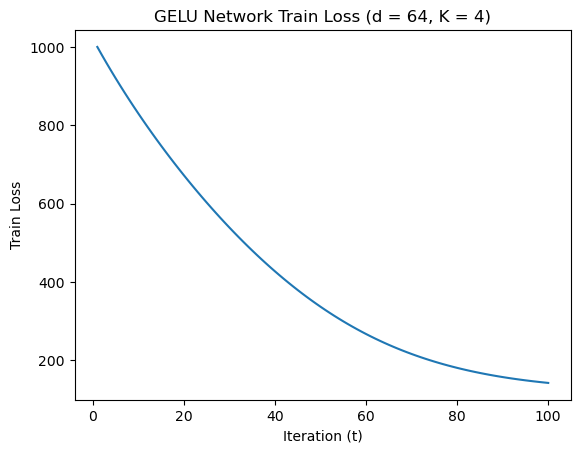

=== TRIAL 0 ===
Initializing weights using orthogonal method with scale 0.01


  0%|          | 0/100 [00:00<?, ?it/s]2026-10-15 13:48:11,050 - INFO - Finish Epoch 1
2026-10-15 13:48:11,052 - INFO - Train loss: 999.8743896484375, train accuracy: 22.8
2026-10-15 13:48:11,059 - INFO - Val loss: 979.69189453125, val accuracy: 96.3
2026-10-15 13:48:11,068 - INFO - Finish Epoch 2
2026-10-15 13:48:11,069 - INFO - Train loss: 979.69189453125, train accuracy: 96.3
2026-10-15 13:48:11,075 - INFO - Val loss: 948.5521850585938, val accuracy: 98.6
2026-10-15 13:48:11,082 - INFO - Finish Epoch 3
2026-10-15 13:48:11,083 - INFO - Train loss: 948.5521850585938, train accuracy: 98.6
2026-10-15 13:48:11,089 - INFO - Val loss: 915.3818359375, val accuracy: 99.0
2026-10-15 13:48:11,096 - INFO - Finish Epoch 4
2026-10-15 13:48:11,097 - INFO - Train loss: 915.3818359375, train accuracy: 99.0
2026-10-15 13:48:11,103 - INFO - Val loss: 882.968994140625, val accuracy: 99.2
2026-10-15 13:48:11,110 - INFO - Finish Epoch 5
2026-10-15 13:48:11,112 - INFO - Train loss: 882.968994140625, train

2026-10-15 13:48:11,598 - INFO - Finish Epoch 38
2026-10-15 13:48:11,599 - INFO - Train loss: 235.25840759277344, train accuracy: 99.6
2026-10-15 13:48:11,605 - INFO - Val loss: 225.95985412597656, val accuracy: 99.6
2026-10-15 13:48:11,612 - INFO - Finish Epoch 39
2026-10-15 13:48:11,613 - INFO - Train loss: 225.95985412597656, train accuracy: 99.6
2026-10-15 13:48:11,620 - INFO - Val loss: 217.13233947753906, val accuracy: 99.6
2026-10-15 13:48:11,627 - INFO - Finish Epoch 40
2026-10-15 13:48:11,628 - INFO - Train loss: 217.13233947753906, train accuracy: 99.6
2026-10-15 13:48:11,634 - INFO - Val loss: 208.76043701171875, val accuracy: 99.6
2026-10-15 13:48:11,641 - INFO - Finish Epoch 41
2026-10-15 13:48:11,642 - INFO - Train loss: 208.76043701171875, train accuracy: 99.6
2026-10-15 13:48:11,649 - INFO - Val loss: 200.82664489746094, val accuracy: 99.6
 41%|████      | 41/100 [00:00<00:00, 67.13it/s]2026-10-15 13:48:11,657 - INFO - Finish Epoch 42
2026-10-15 13:48:11,658 - INFO - Tr

2026-10-15 13:48:12,281 - INFO - Finish Epoch 75
2026-10-15 13:48:12,282 - INFO - Train loss: 88.67402648925781, train accuracy: 99.7
2026-10-15 13:48:12,289 - INFO - Val loss: 87.65821075439453, val accuracy: 99.7
2026-10-15 13:48:12,296 - INFO - Finish Epoch 76
2026-10-15 13:48:12,297 - INFO - Train loss: 87.65821075439453, train accuracy: 99.7
2026-10-15 13:48:12,303 - INFO - Val loss: 86.70030975341797, val accuracy: 99.7
 76%|███████▌  | 76/100 [00:01<00:00, 47.60it/s]2026-10-15 13:48:12,311 - INFO - Finish Epoch 77
2026-10-15 13:48:12,312 - INFO - Train loss: 86.70030975341797, train accuracy: 99.7
2026-10-15 13:48:12,318 - INFO - Val loss: 85.79641723632812, val accuracy: 99.7
2026-10-15 13:48:12,325 - INFO - Finish Epoch 78
2026-10-15 13:48:12,326 - INFO - Train loss: 85.79641723632812, train accuracy: 99.7
2026-10-15 13:48:12,332 - INFO - Val loss: 84.94314575195312, val accuracy: 99.7
2026-10-15 13:48:12,339 - INFO - Finish Epoch 79
2026-10-15 13:48:12,340 - INFO - Train loss

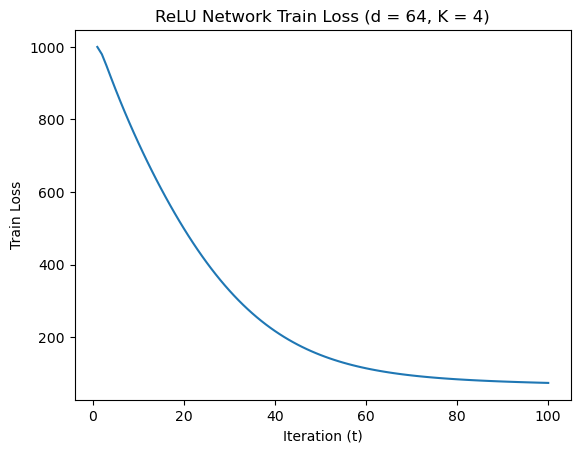

=== TRIAL 0 ===
Initializing weights using orthogonal method with scale 0.01


  0%|          | 0/100 [00:00<?, ?it/s]2026-10-15 13:48:12,800 - INFO - Finish Epoch 1
2026-10-15 13:48:12,801 - INFO - Train loss: 999.961181640625, train accuracy: 26.7
2026-10-15 13:48:12,807 - INFO - Val loss: 979.1639404296875, val accuracy: 99.8
2026-10-15 13:48:12,814 - INFO - Finish Epoch 2
2026-10-15 13:48:12,816 - INFO - Train loss: 979.1639404296875, train accuracy: 99.8
2026-10-15 13:48:12,822 - INFO - Val loss: 958.8955078125, val accuracy: 99.8
2026-10-15 13:48:12,829 - INFO - Finish Epoch 3
2026-10-15 13:48:12,830 - INFO - Train loss: 958.8955078125, train accuracy: 99.8
2026-10-15 13:48:12,836 - INFO - Val loss: 939.1419677734375, val accuracy: 99.8
2026-10-15 13:48:12,843 - INFO - Finish Epoch 4
2026-10-15 13:48:12,844 - INFO - Train loss: 939.1419677734375, train accuracy: 99.8
2026-10-15 13:48:12,851 - INFO - Val loss: 919.889404296875, val accuracy: 99.8
2026-10-15 13:48:12,858 - INFO - Finish Epoch 5
2026-10-15 13:48:12,859 - INFO - Train loss: 919.889404296875, tr

2026-10-15 13:48:13,370 - INFO - Train loss: 495.09136962890625, train accuracy: 99.8
2026-10-15 13:48:13,376 - INFO - Val loss: 486.92242431640625, val accuracy: 99.8
2026-10-15 13:48:13,383 - INFO - Finish Epoch 39
2026-10-15 13:48:13,384 - INFO - Train loss: 486.92242431640625, train accuracy: 99.8
2026-10-15 13:48:13,391 - INFO - Val loss: 478.9533996582031, val accuracy: 99.8
2026-10-15 13:48:13,397 - INFO - Finish Epoch 40
2026-10-15 13:48:13,399 - INFO - Train loss: 478.9533996582031, train accuracy: 99.8
2026-10-15 13:48:13,405 - INFO - Val loss: 471.17938232421875, val accuracy: 99.8
2026-10-15 13:48:13,412 - INFO - Finish Epoch 41
2026-10-15 13:48:13,413 - INFO - Train loss: 471.17938232421875, train accuracy: 99.8
2026-10-15 13:48:13,419 - INFO - Val loss: 463.5953063964844, val accuracy: 99.8
2026-10-15 13:48:13,426 - INFO - Finish Epoch 42
2026-10-15 13:48:13,427 - INFO - Train loss: 463.5953063964844, train accuracy: 99.8
2026-10-15 13:48:13,434 - INFO - Val loss: 456.196

2026-10-15 13:48:13,917 - INFO - Val loss: 290.79071044921875, val accuracy: 99.9
2026-10-15 13:48:13,924 - INFO - Finish Epoch 76
2026-10-15 13:48:13,925 - INFO - Train loss: 290.79071044921875, train accuracy: 99.9
2026-10-15 13:48:13,932 - INFO - Val loss: 287.56011962890625, val accuracy: 99.9
2026-10-15 13:48:13,938 - INFO - Finish Epoch 77
2026-10-15 13:48:13,940 - INFO - Train loss: 287.56011962890625, train accuracy: 99.9
2026-10-15 13:48:13,946 - INFO - Val loss: 284.40631103515625, val accuracy: 99.9
2026-10-15 13:48:13,953 - INFO - Finish Epoch 78
2026-10-15 13:48:13,954 - INFO - Train loss: 284.40631103515625, train accuracy: 99.9
2026-10-15 13:48:13,960 - INFO - Val loss: 281.327392578125, val accuracy: 99.9
2026-10-15 13:48:13,967 - INFO - Finish Epoch 79
2026-10-15 13:48:13,968 - INFO - Train loss: 281.327392578125, train accuracy: 99.9
2026-10-15 13:48:13,975 - INFO - Val loss: 278.32159423828125, val accuracy: 99.9
 79%|███████▉  | 79/100 [00:01<00:00, 68.04it/s]2026-1

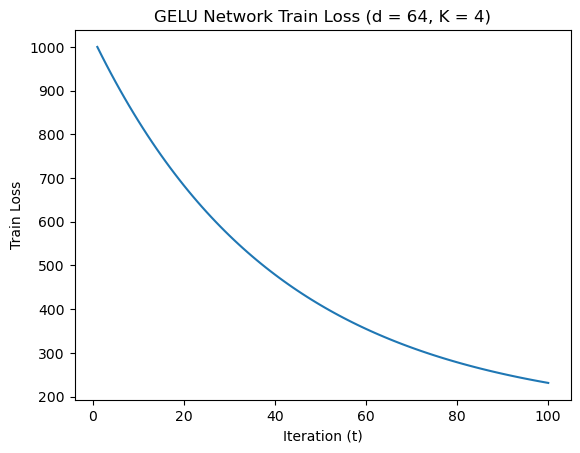

=== TRIAL 0 ===
Initializing weights using orthogonal method with scale 0.01


  0%|          | 0/100 [00:00<?, ?it/s]2026-10-15 13:48:14,453 - INFO - Finish Epoch 1
2026-10-15 13:48:14,455 - INFO - Train loss: 1000.3865966796875, train accuracy: 25.7
2026-10-15 13:48:14,462 - INFO - Val loss: 979.9825439453125, val accuracy: 98.5
2026-10-15 13:48:14,469 - INFO - Finish Epoch 2
2026-10-15 13:48:14,470 - INFO - Train loss: 979.9825439453125, train accuracy: 98.5
2026-10-15 13:48:14,477 - INFO - Val loss: 948.0491943359375, val accuracy: 99.7
2026-10-15 13:48:14,484 - INFO - Finish Epoch 3
2026-10-15 13:48:14,486 - INFO - Train loss: 948.0491943359375, train accuracy: 99.7
2026-10-15 13:48:14,492 - INFO - Val loss: 914.2951049804688, val accuracy: 99.6
2026-10-15 13:48:14,499 - INFO - Finish Epoch 4
2026-10-15 13:48:14,500 - INFO - Train loss: 914.2951049804688, train accuracy: 99.6
2026-10-15 13:48:14,507 - INFO - Val loss: 881.7828369140625, val accuracy: 99.7
2026-10-15 13:48:14,514 - INFO - Finish Epoch 5
2026-10-15 13:48:14,515 - INFO - Train loss: 881.7828369

2026-10-15 13:48:15,030 - INFO - Finish Epoch 38
2026-10-15 13:48:15,032 - INFO - Train loss: 332.5613098144531, train accuracy: 100.0
2026-10-15 13:48:15,038 - INFO - Val loss: 324.92333984375, val accuracy: 100.0
2026-10-15 13:48:15,045 - INFO - Finish Epoch 39
2026-10-15 13:48:15,046 - INFO - Train loss: 324.92333984375, train accuracy: 100.0
2026-10-15 13:48:15,053 - INFO - Val loss: 317.56903076171875, val accuracy: 100.0
2026-10-15 13:48:15,060 - INFO - Finish Epoch 40
2026-10-15 13:48:15,062 - INFO - Train loss: 317.56903076171875, train accuracy: 100.0
2026-10-15 13:48:15,068 - INFO - Val loss: 310.4867248535156, val accuracy: 100.0
2026-10-15 13:48:15,076 - INFO - Finish Epoch 41
2026-10-15 13:48:15,077 - INFO - Train loss: 310.4867248535156, train accuracy: 100.0
2026-10-15 13:48:15,084 - INFO - Val loss: 303.66387939453125, val accuracy: 100.0
2026-10-15 13:48:15,091 - INFO - Finish Epoch 42
2026-10-15 13:48:15,093 - INFO - Train loss: 303.66387939453125, train accuracy: 100

2026-10-15 13:48:15,585 - INFO - Val loss: 172.3336181640625, val accuracy: 100.0
2026-10-15 13:48:15,592 - INFO - Finish Epoch 75
2026-10-15 13:48:15,594 - INFO - Train loss: 172.3336181640625, train accuracy: 100.0
2026-10-15 13:48:15,600 - INFO - Val loss: 170.14328002929688, val accuracy: 100.0
2026-10-15 13:48:15,607 - INFO - Finish Epoch 76
2026-10-15 13:48:15,608 - INFO - Train loss: 170.14328002929688, train accuracy: 100.0
2026-10-15 13:48:15,615 - INFO - Val loss: 168.0176239013672, val accuracy: 100.0
2026-10-15 13:48:15,622 - INFO - Finish Epoch 77
2026-10-15 13:48:15,624 - INFO - Train loss: 168.0176239013672, train accuracy: 100.0
2026-10-15 13:48:15,630 - INFO - Val loss: 165.9536895751953, val accuracy: 100.0
 77%|███████▋  | 77/100 [00:01<00:00, 65.81it/s]2026-10-15 13:48:15,639 - INFO - Finish Epoch 78
2026-10-15 13:48:15,640 - INFO - Train loss: 165.9536895751953, train accuracy: 100.0
2026-10-15 13:48:15,647 - INFO - Val loss: 163.94985961914062, val accuracy: 100.0

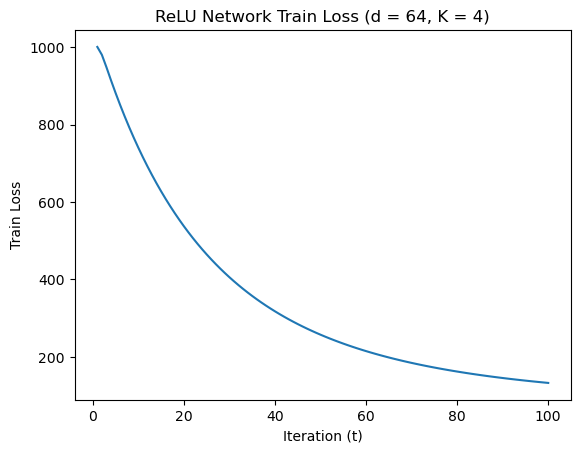

=== TRIAL 1 ===
Initializing weights using orthogonal method with scale 0.01


  0%|          | 0/100 [00:00<?, ?it/s]2026-10-15 13:48:16,126 - INFO - Finish Epoch 1
2026-10-15 13:48:16,127 - INFO - Train loss: 1000.0738525390625, train accuracy: 25.5
2026-10-15 13:48:16,133 - INFO - Val loss: 980.286865234375, val accuracy: 99.4
2026-10-15 13:48:16,140 - INFO - Finish Epoch 2
2026-10-15 13:48:16,142 - INFO - Train loss: 980.286865234375, train accuracy: 99.4
2026-10-15 13:48:16,148 - INFO - Val loss: 960.9732666015625, val accuracy: 99.5
2026-10-15 13:48:16,155 - INFO - Finish Epoch 3
2026-10-15 13:48:16,156 - INFO - Train loss: 960.9732666015625, train accuracy: 99.5
2026-10-15 13:48:16,162 - INFO - Val loss: 942.1055297851562, val accuracy: 99.5
2026-10-15 13:48:16,169 - INFO - Finish Epoch 4
2026-10-15 13:48:16,171 - INFO - Train loss: 942.1055297851562, train accuracy: 99.5
2026-10-15 13:48:16,177 - INFO - Val loss: 923.65869140625, val accuracy: 99.7
2026-10-15 13:48:16,184 - INFO - Finish Epoch 5
2026-10-15 13:48:16,185 - INFO - Train loss: 923.65869140625

2026-10-15 13:48:16,835 - INFO - Finish Epoch 38
2026-10-15 13:48:16,837 - INFO - Train loss: 470.5067138671875, train accuracy: 99.9
2026-10-15 13:48:16,843 - INFO - Val loss: 460.4835205078125, val accuracy: 99.9
2026-10-15 13:48:16,850 - INFO - Finish Epoch 39
2026-10-15 13:48:16,852 - INFO - Train loss: 460.4835205078125, train accuracy: 99.9
2026-10-15 13:48:16,858 - INFO - Val loss: 450.6618957519531, val accuracy: 99.9
2026-10-15 13:48:16,866 - INFO - Finish Epoch 40
2026-10-15 13:48:16,867 - INFO - Train loss: 450.6618957519531, train accuracy: 99.9
2026-10-15 13:48:16,873 - INFO - Val loss: 441.0416564941406, val accuracy: 99.9
2026-10-15 13:48:16,880 - INFO - Finish Epoch 41
2026-10-15 13:48:16,882 - INFO - Train loss: 441.0416564941406, train accuracy: 99.9
2026-10-15 13:48:16,888 - INFO - Val loss: 431.6225891113281, val accuracy: 99.9
2026-10-15 13:48:16,895 - INFO - Finish Epoch 42
2026-10-15 13:48:16,897 - INFO - Train loss: 431.6225891113281, train accuracy: 99.9
2026-1

2026-10-15 13:48:17,441 - INFO - Finish Epoch 75
2026-10-15 13:48:17,443 - INFO - Train loss: 226.230224609375, train accuracy: 99.9
2026-10-15 13:48:17,449 - INFO - Val loss: 222.77996826171875, val accuracy: 99.9
2026-10-15 13:48:17,456 - INFO - Finish Epoch 76
2026-10-15 13:48:17,457 - INFO - Train loss: 222.77996826171875, train accuracy: 99.9
2026-10-15 13:48:17,464 - INFO - Val loss: 219.45883178710938, val accuracy: 99.9
 76%|███████▌  | 76/100 [00:01<00:00, 61.16it/s]2026-10-15 13:48:17,472 - INFO - Finish Epoch 77
2026-10-15 13:48:17,474 - INFO - Train loss: 219.45883178710938, train accuracy: 99.9
2026-10-15 13:48:17,480 - INFO - Val loss: 216.263427734375, val accuracy: 99.9
2026-10-15 13:48:17,488 - INFO - Finish Epoch 78
2026-10-15 13:48:17,489 - INFO - Train loss: 216.263427734375, train accuracy: 99.9
2026-10-15 13:48:17,495 - INFO - Val loss: 213.19044494628906, val accuracy: 99.9
2026-10-15 13:48:17,502 - INFO - Finish Epoch 79
2026-10-15 13:48:17,504 - INFO - Train lo

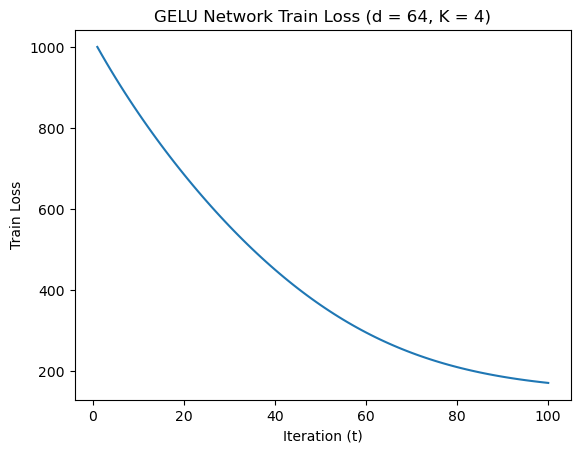

=== TRIAL 1 ===
Initializing weights using orthogonal method with scale 0.01


  0%|          | 0/100 [00:00<?, ?it/s]2026-10-15 13:48:17,980 - INFO - Finish Epoch 1
2026-10-15 13:48:17,982 - INFO - Train loss: 1000.4953002929688, train accuracy: 23.2
2026-10-15 13:48:17,989 - INFO - Val loss: 978.7139892578125, val accuracy: 96.7
2026-10-15 13:48:17,996 - INFO - Finish Epoch 2
2026-10-15 13:48:17,997 - INFO - Train loss: 978.7139892578125, train accuracy: 96.7
2026-10-15 13:48:18,004 - INFO - Val loss: 945.726806640625, val accuracy: 98.6
2026-10-15 13:48:18,011 - INFO - Finish Epoch 3
2026-10-15 13:48:18,012 - INFO - Train loss: 945.726806640625, train accuracy: 98.6
2026-10-15 13:48:18,019 - INFO - Val loss: 910.56591796875, val accuracy: 98.8
2026-10-15 13:48:18,026 - INFO - Finish Epoch 4
2026-10-15 13:48:18,027 - INFO - Train loss: 910.56591796875, train accuracy: 98.8
2026-10-15 13:48:18,033 - INFO - Val loss: 876.4766845703125, val accuracy: 98.6
2026-10-15 13:48:18,041 - INFO - Finish Epoch 5
2026-10-15 13:48:18,042 - INFO - Train loss: 876.4766845703125

2026-10-15 13:48:18,538 - INFO - Finish Epoch 38
2026-10-15 13:48:18,539 - INFO - Train loss: 224.38528442382812, train accuracy: 99.8
2026-10-15 13:48:18,545 - INFO - Val loss: 215.360595703125, val accuracy: 99.9
2026-10-15 13:48:18,553 - INFO - Finish Epoch 39
2026-10-15 13:48:18,554 - INFO - Train loss: 215.360595703125, train accuracy: 99.9
2026-10-15 13:48:18,560 - INFO - Val loss: 206.80075073242188, val accuracy: 100.0
2026-10-15 13:48:18,567 - INFO - Finish Epoch 40
2026-10-15 13:48:18,568 - INFO - Train loss: 206.80075073242188, train accuracy: 100.0
2026-10-15 13:48:18,575 - INFO - Val loss: 198.6900177001953, val accuracy: 100.0
2026-10-15 13:48:18,582 - INFO - Finish Epoch 41
2026-10-15 13:48:18,583 - INFO - Train loss: 198.6900177001953, train accuracy: 100.0
2026-10-15 13:48:18,589 - INFO - Val loss: 191.00997924804688, val accuracy: 100.0
2026-10-15 13:48:18,596 - INFO - Finish Epoch 42
2026-10-15 13:48:18,597 - INFO - Train loss: 191.00997924804688, train accuracy: 100

2026-10-15 13:48:19,076 - INFO - Val loss: 83.59307098388672, val accuracy: 100.0
2026-10-15 13:48:19,083 - INFO - Finish Epoch 75
2026-10-15 13:48:19,084 - INFO - Train loss: 83.59307098388672, train accuracy: 100.0
2026-10-15 13:48:19,091 - INFO - Val loss: 82.6335678100586, val accuracy: 100.0
2026-10-15 13:48:19,098 - INFO - Finish Epoch 76
2026-10-15 13:48:19,099 - INFO - Train loss: 82.6335678100586, train accuracy: 100.0
2026-10-15 13:48:19,105 - INFO - Val loss: 81.72825622558594, val accuracy: 100.0
2026-10-15 13:48:19,112 - INFO - Finish Epoch 77
2026-10-15 13:48:19,113 - INFO - Train loss: 81.72825622558594, train accuracy: 100.0
2026-10-15 13:48:19,120 - INFO - Val loss: 80.87361145019531, val accuracy: 100.0
 77%|███████▋  | 77/100 [00:01<00:00, 67.79it/s]2026-10-15 13:48:19,128 - INFO - Finish Epoch 78
2026-10-15 13:48:19,129 - INFO - Train loss: 80.87361145019531, train accuracy: 100.0
2026-10-15 13:48:19,136 - INFO - Val loss: 80.06632995605469, val accuracy: 100.0
2026

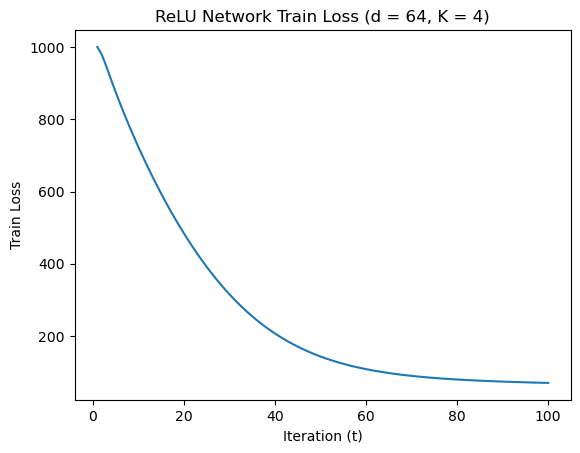

=== TRIAL 1 ===
Initializing weights using orthogonal method with scale 0.01


  0%|          | 0/100 [00:00<?, ?it/s]2026-10-15 13:48:19,611 - INFO - Finish Epoch 1
2026-10-15 13:48:19,612 - INFO - Train loss: 1000.0858154296875, train accuracy: 24.0
2026-10-15 13:48:19,619 - INFO - Val loss: 980.2674560546875, val accuracy: 99.7
2026-10-15 13:48:19,626 - INFO - Finish Epoch 2
2026-10-15 13:48:19,627 - INFO - Train loss: 980.2674560546875, train accuracy: 99.7
2026-10-15 13:48:19,633 - INFO - Val loss: 960.94970703125, val accuracy: 99.7
2026-10-15 13:48:19,641 - INFO - Finish Epoch 3
2026-10-15 13:48:19,642 - INFO - Train loss: 960.94970703125, train accuracy: 99.7
2026-10-15 13:48:19,648 - INFO - Val loss: 942.1190185546875, val accuracy: 99.7
2026-10-15 13:48:19,655 - INFO - Finish Epoch 4
2026-10-15 13:48:19,656 - INFO - Train loss: 942.1190185546875, train accuracy: 99.7
2026-10-15 13:48:19,663 - INFO - Val loss: 923.76220703125, val accuracy: 99.7
2026-10-15 13:48:19,670 - INFO - Finish Epoch 5
2026-10-15 13:48:19,671 - INFO - Train loss: 923.76220703125, 

2026-10-15 13:48:20,157 - INFO - Train loss: 516.5692749023438, train accuracy: 99.7
2026-10-15 13:48:20,163 - INFO - Val loss: 508.65509033203125, val accuracy: 99.7
2026-10-15 13:48:20,170 - INFO - Finish Epoch 39
2026-10-15 13:48:20,171 - INFO - Train loss: 508.65509033203125, train accuracy: 99.7
2026-10-15 13:48:20,178 - INFO - Val loss: 500.92864990234375, val accuracy: 99.7
2026-10-15 13:48:20,185 - INFO - Finish Epoch 40
2026-10-15 13:48:20,186 - INFO - Train loss: 500.92864990234375, train accuracy: 99.7
2026-10-15 13:48:20,192 - INFO - Val loss: 493.38525390625, val accuracy: 99.7
2026-10-15 13:48:20,199 - INFO - Finish Epoch 41
2026-10-15 13:48:20,200 - INFO - Train loss: 493.38525390625, train accuracy: 99.7
2026-10-15 13:48:20,207 - INFO - Val loss: 486.0201416015625, val accuracy: 99.7
2026-10-15 13:48:20,214 - INFO - Finish Epoch 42
2026-10-15 13:48:20,215 - INFO - Train loss: 486.0201416015625, train accuracy: 99.7
2026-10-15 13:48:20,221 - INFO - Val loss: 478.82891845

2026-10-15 13:48:20,855 - INFO - Val loss: 315.50347900390625, val accuracy: 99.8
2026-10-15 13:48:20,862 - INFO - Finish Epoch 76
2026-10-15 13:48:20,863 - INFO - Train loss: 315.50347900390625, train accuracy: 99.8
2026-10-15 13:48:20,869 - INFO - Val loss: 312.23211669921875, val accuracy: 99.8
2026-10-15 13:48:20,877 - INFO - Finish Epoch 77
2026-10-15 13:48:20,878 - INFO - Train loss: 312.23211669921875, train accuracy: 99.8
2026-10-15 13:48:20,884 - INFO - Val loss: 309.033447265625, val accuracy: 99.8
 77%|███████▋  | 77/100 [00:01<00:00, 55.96it/s]2026-10-15 13:48:20,892 - INFO - Finish Epoch 78
2026-10-15 13:48:20,893 - INFO - Train loss: 309.033447265625, train accuracy: 99.8
2026-10-15 13:48:20,900 - INFO - Val loss: 305.9056396484375, val accuracy: 99.8
2026-10-15 13:48:20,907 - INFO - Finish Epoch 79
2026-10-15 13:48:20,908 - INFO - Train loss: 305.9056396484375, train accuracy: 99.8
2026-10-15 13:48:20,914 - INFO - Val loss: 302.84710693359375, val accuracy: 99.8
2026-10-

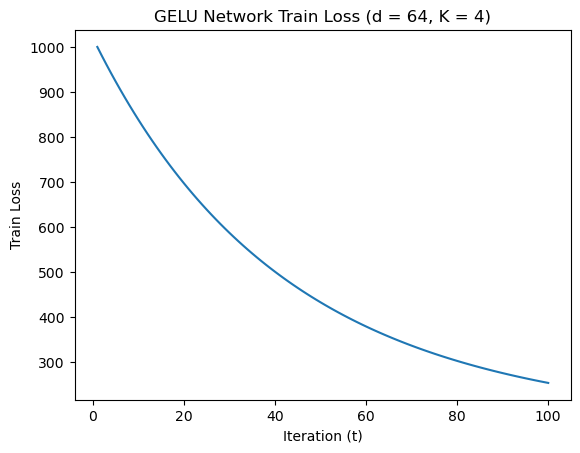

=== TRIAL 1 ===
Initializing weights using orthogonal method with scale 0.01


  0%|          | 0/100 [00:00<?, ?it/s]2026-10-15 13:48:21,387 - INFO - Finish Epoch 1
2026-10-15 13:48:21,388 - INFO - Train loss: 999.76123046875, train accuracy: 20.8
2026-10-15 13:48:21,395 - INFO - Val loss: 975.2244873046875, val accuracy: 99.0
2026-10-15 13:48:21,402 - INFO - Finish Epoch 2
2026-10-15 13:48:21,403 - INFO - Train loss: 975.2244873046875, train accuracy: 99.0
2026-10-15 13:48:21,409 - INFO - Val loss: 936.77978515625, val accuracy: 99.8
2026-10-15 13:48:21,416 - INFO - Finish Epoch 3
2026-10-15 13:48:21,418 - INFO - Train loss: 936.77978515625, train accuracy: 99.8
2026-10-15 13:48:21,424 - INFO - Val loss: 896.5519409179688, val accuracy: 99.7
2026-10-15 13:48:21,431 - INFO - Finish Epoch 4
2026-10-15 13:48:21,432 - INFO - Train loss: 896.5519409179688, train accuracy: 99.7
2026-10-15 13:48:21,438 - INFO - Val loss: 858.0380859375, val accuracy: 99.7
2026-10-15 13:48:21,445 - INFO - Finish Epoch 5
2026-10-15 13:48:21,446 - INFO - Train loss: 858.0380859375, train

2026-10-15 13:48:21,929 - INFO - Train loss: 260.03118896484375, train accuracy: 99.8
2026-10-15 13:48:21,935 - INFO - Val loss: 252.99365234375, val accuracy: 99.8
2026-10-15 13:48:21,942 - INFO - Finish Epoch 39
2026-10-15 13:48:21,943 - INFO - Train loss: 252.99365234375, train accuracy: 99.8
2026-10-15 13:48:21,949 - INFO - Val loss: 246.27890014648438, val accuracy: 99.9
2026-10-15 13:48:21,956 - INFO - Finish Epoch 40
2026-10-15 13:48:21,958 - INFO - Train loss: 246.27890014648438, train accuracy: 99.9
2026-10-15 13:48:21,964 - INFO - Val loss: 239.86904907226562, val accuracy: 99.9
2026-10-15 13:48:21,971 - INFO - Finish Epoch 41
2026-10-15 13:48:21,972 - INFO - Train loss: 239.86904907226562, train accuracy: 99.9
2026-10-15 13:48:21,978 - INFO - Val loss: 233.75033569335938, val accuracy: 99.9
2026-10-15 13:48:21,985 - INFO - Finish Epoch 42
2026-10-15 13:48:21,987 - INFO - Train loss: 233.75033569335938, train accuracy: 99.9
2026-10-15 13:48:21,993 - INFO - Val loss: 227.90823

2026-10-15 13:48:22,468 - INFO - Finish Epoch 75
2026-10-15 13:48:22,469 - INFO - Train loss: 129.56076049804688, train accuracy: 100.0
2026-10-15 13:48:22,476 - INFO - Val loss: 128.0969696044922, val accuracy: 100.0
2026-10-15 13:48:22,483 - INFO - Finish Epoch 76
2026-10-15 13:48:22,484 - INFO - Train loss: 128.0969696044922, train accuracy: 100.0
2026-10-15 13:48:22,490 - INFO - Val loss: 126.68693542480469, val accuracy: 100.0
2026-10-15 13:48:22,497 - INFO - Finish Epoch 77
2026-10-15 13:48:22,498 - INFO - Train loss: 126.68693542480469, train accuracy: 100.0
2026-10-15 13:48:22,504 - INFO - Val loss: 125.3272705078125, val accuracy: 100.0
 77%|███████▋  | 77/100 [00:01<00:00, 68.43it/s]2026-10-15 13:48:22,513 - INFO - Finish Epoch 78
2026-10-15 13:48:22,514 - INFO - Train loss: 125.3272705078125, train accuracy: 100.0
2026-10-15 13:48:22,520 - INFO - Val loss: 124.01625061035156, val accuracy: 100.0
2026-10-15 13:48:22,527 - INFO - Finish Epoch 79
2026-10-15 13:48:22,528 - INFO 

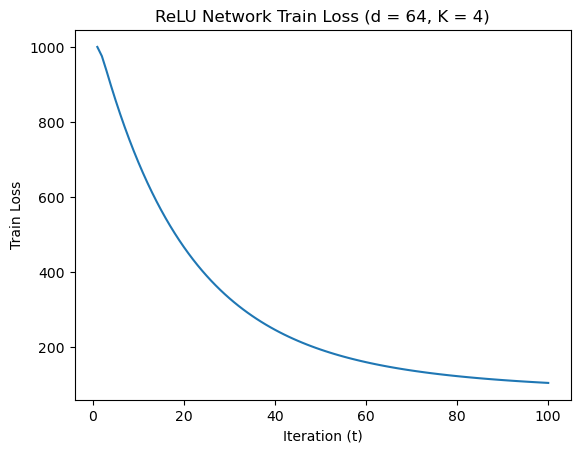

=== TRIAL 2 ===
Initializing weights using orthogonal method with scale 0.01


  0%|          | 0/100 [00:00<?, ?it/s]2026-10-15 13:48:22,993 - INFO - Finish Epoch 1
2026-10-15 13:48:22,994 - INFO - Train loss: 999.9664916992188, train accuracy: 26.1
2026-10-15 13:48:23,001 - INFO - Val loss: 978.956787109375, val accuracy: 99.7
2026-10-15 13:48:23,008 - INFO - Finish Epoch 2
2026-10-15 13:48:23,009 - INFO - Train loss: 978.956787109375, train accuracy: 99.7
2026-10-15 13:48:23,015 - INFO - Val loss: 958.483642578125, val accuracy: 99.8
2026-10-15 13:48:23,023 - INFO - Finish Epoch 3
2026-10-15 13:48:23,024 - INFO - Train loss: 958.483642578125, train accuracy: 99.8
2026-10-15 13:48:23,030 - INFO - Val loss: 938.5164794921875, val accuracy: 99.8
2026-10-15 13:48:23,037 - INFO - Finish Epoch 4
2026-10-15 13:48:23,039 - INFO - Train loss: 938.5164794921875, train accuracy: 99.8
2026-10-15 13:48:23,045 - INFO - Val loss: 919.027099609375, val accuracy: 99.8
2026-10-15 13:48:23,052 - INFO - Finish Epoch 5
2026-10-15 13:48:23,053 - INFO - Train loss: 919.027099609375,

2026-10-15 13:48:23,547 - INFO - Train loss: 453.1786193847656, train accuracy: 99.8
2026-10-15 13:48:23,554 - INFO - Val loss: 443.23394775390625, val accuracy: 99.8
2026-10-15 13:48:23,561 - INFO - Finish Epoch 39
2026-10-15 13:48:23,562 - INFO - Train loss: 443.23394775390625, train accuracy: 99.8
2026-10-15 13:48:23,568 - INFO - Val loss: 433.50811767578125, val accuracy: 99.8
2026-10-15 13:48:23,575 - INFO - Finish Epoch 40
2026-10-15 13:48:23,577 - INFO - Train loss: 433.50811767578125, train accuracy: 99.8
2026-10-15 13:48:23,583 - INFO - Val loss: 424.00018310546875, val accuracy: 99.8
2026-10-15 13:48:23,590 - INFO - Finish Epoch 41
2026-10-15 13:48:23,591 - INFO - Train loss: 424.00018310546875, train accuracy: 99.8
2026-10-15 13:48:23,598 - INFO - Val loss: 414.7088623046875, val accuracy: 99.8
2026-10-15 13:48:23,605 - INFO - Finish Epoch 42
2026-10-15 13:48:23,606 - INFO - Train loss: 414.7088623046875, train accuracy: 99.8
2026-10-15 13:48:23,612 - INFO - Val loss: 405.63

2026-10-15 13:48:24,097 - INFO - Train loss: 217.303955078125, train accuracy: 99.8
2026-10-15 13:48:24,104 - INFO - Val loss: 214.096435546875, val accuracy: 99.8
2026-10-15 13:48:24,111 - INFO - Finish Epoch 76
2026-10-15 13:48:24,112 - INFO - Train loss: 214.096435546875, train accuracy: 99.8
2026-10-15 13:48:24,118 - INFO - Val loss: 211.01385498046875, val accuracy: 99.8
2026-10-15 13:48:24,125 - INFO - Finish Epoch 77
2026-10-15 13:48:24,127 - INFO - Train loss: 211.01385498046875, train accuracy: 99.8
2026-10-15 13:48:24,133 - INFO - Val loss: 208.05271911621094, val accuracy: 99.8
 77%|███████▋  | 77/100 [00:01<00:00, 67.23it/s]2026-10-15 13:48:24,141 - INFO - Finish Epoch 78
2026-10-15 13:48:24,142 - INFO - Train loss: 208.05271911621094, train accuracy: 99.8
2026-10-15 13:48:24,148 - INFO - Val loss: 205.20953369140625, val accuracy: 99.8
2026-10-15 13:48:24,155 - INFO - Finish Epoch 79
2026-10-15 13:48:24,157 - INFO - Train loss: 205.20953369140625, train accuracy: 99.8
2026

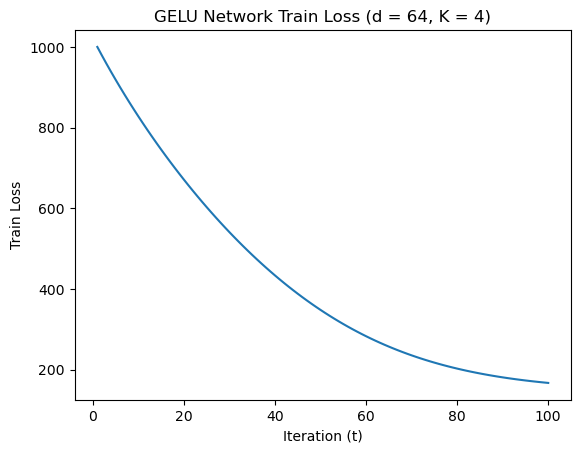

=== TRIAL 2 ===
Initializing weights using orthogonal method with scale 0.01


  0%|          | 0/100 [00:00<?, ?it/s]2026-10-15 13:48:24,624 - INFO - Finish Epoch 1
2026-10-15 13:48:24,625 - INFO - Train loss: 999.955810546875, train accuracy: 33.2
2026-10-15 13:48:24,631 - INFO - Val loss: 976.8723754882812, val accuracy: 97.9
2026-10-15 13:48:24,638 - INFO - Finish Epoch 2
2026-10-15 13:48:24,640 - INFO - Train loss: 976.8723754882812, train accuracy: 97.9
2026-10-15 13:48:24,646 - INFO - Val loss: 942.0628051757812, val accuracy: 99.4
2026-10-15 13:48:24,653 - INFO - Finish Epoch 3
2026-10-15 13:48:24,654 - INFO - Train loss: 942.0628051757812, train accuracy: 99.4
2026-10-15 13:48:24,661 - INFO - Val loss: 906.5881958007812, val accuracy: 99.5
2026-10-15 13:48:24,668 - INFO - Finish Epoch 4
2026-10-15 13:48:24,669 - INFO - Train loss: 906.5881958007812, train accuracy: 99.5
2026-10-15 13:48:24,675 - INFO - Val loss: 872.3636474609375, val accuracy: 99.5
2026-10-15 13:48:24,683 - INFO - Finish Epoch 5
2026-10-15 13:48:24,684 - INFO - Train loss: 872.363647460

2026-10-15 13:48:25,325 - INFO - Finish Epoch 38
2026-10-15 13:48:25,326 - INFO - Train loss: 215.16024780273438, train accuracy: 99.4
2026-10-15 13:48:25,332 - INFO - Val loss: 206.89691162109375, val accuracy: 99.4
2026-10-15 13:48:25,340 - INFO - Finish Epoch 39
2026-10-15 13:48:25,341 - INFO - Train loss: 206.89691162109375, train accuracy: 99.4
2026-10-15 13:48:25,347 - INFO - Val loss: 199.13449096679688, val accuracy: 99.5
2026-10-15 13:48:25,354 - INFO - Finish Epoch 40
2026-10-15 13:48:25,356 - INFO - Train loss: 199.13449096679688, train accuracy: 99.5
2026-10-15 13:48:25,362 - INFO - Val loss: 191.84854125976562, val accuracy: 99.5
2026-10-15 13:48:25,371 - INFO - Finish Epoch 41
2026-10-15 13:48:25,372 - INFO - Train loss: 191.84854125976562, train accuracy: 99.5
2026-10-15 13:48:25,379 - INFO - Val loss: 185.0142059326172, val accuracy: 99.5
2026-10-15 13:48:25,386 - INFO - Finish Epoch 42
2026-10-15 13:48:25,387 - INFO - Train loss: 185.0142059326172, train accuracy: 99.5

2026-10-15 13:48:25,876 - INFO - Finish Epoch 75
2026-10-15 13:48:25,877 - INFO - Train loss: 96.06230163574219, train accuracy: 99.6
2026-10-15 13:48:25,884 - INFO - Val loss: 95.27745056152344, val accuracy: 99.6
2026-10-15 13:48:25,891 - INFO - Finish Epoch 76
2026-10-15 13:48:25,892 - INFO - Train loss: 95.27745056152344, train accuracy: 99.6
2026-10-15 13:48:25,898 - INFO - Val loss: 94.53285217285156, val accuracy: 99.7
2026-10-15 13:48:25,905 - INFO - Finish Epoch 77
2026-10-15 13:48:25,907 - INFO - Train loss: 94.53285217285156, train accuracy: 99.7
2026-10-15 13:48:25,913 - INFO - Val loss: 93.82524108886719, val accuracy: 99.7
 77%|███████▋  | 77/100 [00:01<00:00, 66.23it/s]2026-10-15 13:48:25,921 - INFO - Finish Epoch 78
2026-10-15 13:48:25,922 - INFO - Train loss: 93.82524108886719, train accuracy: 99.7
2026-10-15 13:48:25,929 - INFO - Val loss: 93.15272521972656, val accuracy: 99.7
2026-10-15 13:48:25,936 - INFO - Finish Epoch 79
2026-10-15 13:48:25,937 - INFO - Train loss

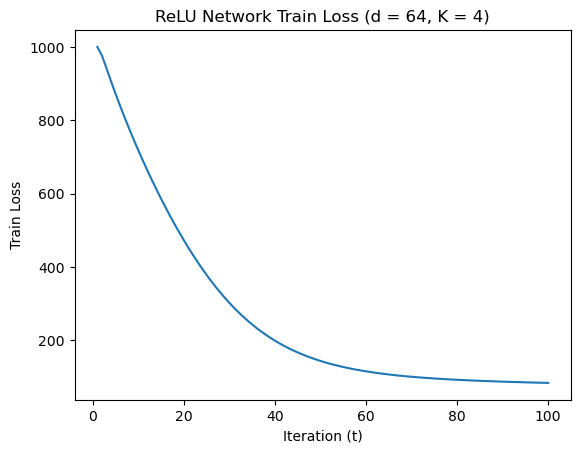

=== TRIAL 2 ===
Initializing weights using orthogonal method with scale 0.01


  0%|          | 0/100 [00:00<?, ?it/s]2026-10-15 13:48:26,406 - INFO - Finish Epoch 1
2026-10-15 13:48:26,407 - INFO - Train loss: 1000.2466430664062, train accuracy: 19.8
2026-10-15 13:48:26,414 - INFO - Val loss: 980.857177734375, val accuracy: 99.8
2026-10-15 13:48:26,421 - INFO - Finish Epoch 2
2026-10-15 13:48:26,423 - INFO - Train loss: 980.857177734375, train accuracy: 99.8
2026-10-15 13:48:26,429 - INFO - Val loss: 961.9133911132812, val accuracy: 99.8
2026-10-15 13:48:26,436 - INFO - Finish Epoch 3
2026-10-15 13:48:26,437 - INFO - Train loss: 961.9133911132812, train accuracy: 99.8
2026-10-15 13:48:26,444 - INFO - Val loss: 943.4044799804688, val accuracy: 99.9
2026-10-15 13:48:26,451 - INFO - Finish Epoch 4
2026-10-15 13:48:26,452 - INFO - Train loss: 943.4044799804688, train accuracy: 99.9
2026-10-15 13:48:26,459 - INFO - Val loss: 925.3201904296875, val accuracy: 99.9
2026-10-15 13:48:26,466 - INFO - Finish Epoch 5
2026-10-15 13:48:26,467 - INFO - Train loss: 925.320190429

2026-10-15 13:48:26,955 - INFO - Train loss: 511.9969482421875, train accuracy: 99.9
2026-10-15 13:48:26,962 - INFO - Val loss: 503.69537353515625, val accuracy: 99.9
2026-10-15 13:48:26,969 - INFO - Finish Epoch 39
2026-10-15 13:48:26,970 - INFO - Train loss: 503.69537353515625, train accuracy: 99.9
2026-10-15 13:48:26,976 - INFO - Val loss: 495.579345703125, val accuracy: 99.9
2026-10-15 13:48:26,983 - INFO - Finish Epoch 40
2026-10-15 13:48:26,985 - INFO - Train loss: 495.579345703125, train accuracy: 99.9
2026-10-15 13:48:26,991 - INFO - Val loss: 487.64459228515625, val accuracy: 99.9
2026-10-15 13:48:26,998 - INFO - Finish Epoch 41
2026-10-15 13:48:26,999 - INFO - Train loss: 487.64459228515625, train accuracy: 99.9
2026-10-15 13:48:27,005 - INFO - Val loss: 479.8869934082031, val accuracy: 99.9
2026-10-15 13:48:27,013 - INFO - Finish Epoch 42
2026-10-15 13:48:27,014 - INFO - Train loss: 479.8869934082031, train accuracy: 99.9
2026-10-15 13:48:27,020 - INFO - Val loss: 472.302398

2026-10-15 13:48:27,501 - INFO - Train loss: 300.94036865234375, train accuracy: 99.9
2026-10-15 13:48:27,508 - INFO - Val loss: 297.30438232421875, val accuracy: 99.9
2026-10-15 13:48:27,515 - INFO - Finish Epoch 76
2026-10-15 13:48:27,516 - INFO - Train loss: 297.30438232421875, train accuracy: 99.9
2026-10-15 13:48:27,522 - INFO - Val loss: 293.7475280761719, val accuracy: 99.9
2026-10-15 13:48:27,529 - INFO - Finish Epoch 77
2026-10-15 13:48:27,530 - INFO - Train loss: 293.7475280761719, train accuracy: 99.9
2026-10-15 13:48:27,537 - INFO - Val loss: 290.26800537109375, val accuracy: 99.9
 77%|███████▋  | 77/100 [00:01<00:00, 67.78it/s]2026-10-15 13:48:27,545 - INFO - Finish Epoch 78
2026-10-15 13:48:27,546 - INFO - Train loss: 290.26800537109375, train accuracy: 99.9
2026-10-15 13:48:27,552 - INFO - Val loss: 286.86407470703125, val accuracy: 99.9
2026-10-15 13:48:27,559 - INFO - Finish Epoch 79
2026-10-15 13:48:27,561 - INFO - Train loss: 286.86407470703125, train accuracy: 99.9


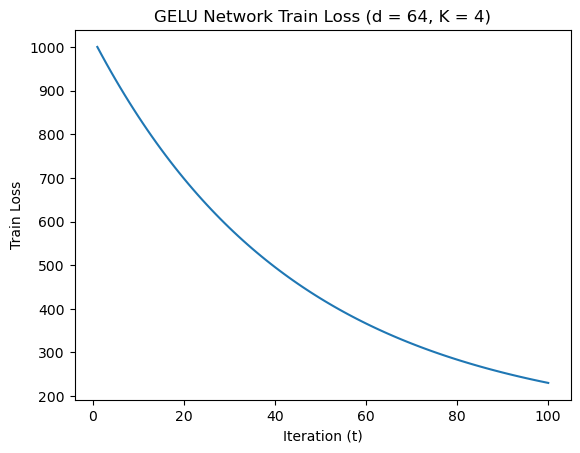

=== TRIAL 2 ===
Initializing weights using orthogonal method with scale 0.01


  0%|          | 0/100 [00:00<?, ?it/s]2026-10-15 13:48:28,050 - INFO - Finish Epoch 1
2026-10-15 13:48:28,051 - INFO - Train loss: 999.604736328125, train accuracy: 27.6
2026-10-15 13:48:28,057 - INFO - Val loss: 978.6365966796875, val accuracy: 98.6
2026-10-15 13:48:28,065 - INFO - Finish Epoch 2
2026-10-15 13:48:28,066 - INFO - Train loss: 978.6365966796875, train accuracy: 98.6
2026-10-15 13:48:28,073 - INFO - Val loss: 946.108642578125, val accuracy: 99.7
2026-10-15 13:48:28,080 - INFO - Finish Epoch 3
2026-10-15 13:48:28,081 - INFO - Train loss: 946.108642578125, train accuracy: 99.7
2026-10-15 13:48:28,088 - INFO - Val loss: 911.8272094726562, val accuracy: 99.6
2026-10-15 13:48:28,095 - INFO - Finish Epoch 4
2026-10-15 13:48:28,096 - INFO - Train loss: 911.8272094726562, train accuracy: 99.6
2026-10-15 13:48:28,102 - INFO - Val loss: 878.7102661132812, val accuracy: 99.6
2026-10-15 13:48:28,110 - INFO - Finish Epoch 5
2026-10-15 13:48:28,111 - INFO - Train loss: 878.71026611328

2026-10-15 13:48:28,619 - INFO - Finish Epoch 38
2026-10-15 13:48:28,621 - INFO - Train loss: 320.357666015625, train accuracy: 99.9
2026-10-15 13:48:28,627 - INFO - Val loss: 312.752197265625, val accuracy: 99.9
2026-10-15 13:48:28,634 - INFO - Finish Epoch 39
2026-10-15 13:48:28,635 - INFO - Train loss: 312.752197265625, train accuracy: 99.9
2026-10-15 13:48:28,642 - INFO - Val loss: 305.4429626464844, val accuracy: 99.9
2026-10-15 13:48:28,649 - INFO - Finish Epoch 40
2026-10-15 13:48:28,651 - INFO - Train loss: 305.4429626464844, train accuracy: 99.9
2026-10-15 13:48:28,657 - INFO - Val loss: 298.41766357421875, val accuracy: 99.9
2026-10-15 13:48:28,665 - INFO - Finish Epoch 41
2026-10-15 13:48:28,666 - INFO - Train loss: 298.41766357421875, train accuracy: 99.9
2026-10-15 13:48:28,673 - INFO - Val loss: 291.661865234375, val accuracy: 99.9
2026-10-15 13:48:28,680 - INFO - Finish Epoch 42
2026-10-15 13:48:28,682 - INFO - Train loss: 291.661865234375, train accuracy: 99.9
2026-10-1

2026-10-15 13:48:29,321 - INFO - Finish Epoch 75
2026-10-15 13:48:29,322 - INFO - Train loss: 165.82879638671875, train accuracy: 99.8
2026-10-15 13:48:29,328 - INFO - Val loss: 163.84109497070312, val accuracy: 99.8
2026-10-15 13:48:29,335 - INFO - Finish Epoch 76
2026-10-15 13:48:29,336 - INFO - Train loss: 163.84109497070312, train accuracy: 99.8
2026-10-15 13:48:29,343 - INFO - Val loss: 161.91680908203125, val accuracy: 99.8
2026-10-15 13:48:29,350 - INFO - Finish Epoch 77
2026-10-15 13:48:29,351 - INFO - Train loss: 161.91680908203125, train accuracy: 99.8
2026-10-15 13:48:29,357 - INFO - Val loss: 160.05419921875, val accuracy: 99.8
 77%|███████▋  | 77/100 [00:01<00:00, 51.61it/s]2026-10-15 13:48:29,365 - INFO - Finish Epoch 78
2026-10-15 13:48:29,367 - INFO - Train loss: 160.05419921875, train accuracy: 99.8
2026-10-15 13:48:29,373 - INFO - Val loss: 158.24996948242188, val accuracy: 99.8
2026-10-15 13:48:29,380 - INFO - Finish Epoch 79
2026-10-15 13:48:29,381 - INFO - Train lo

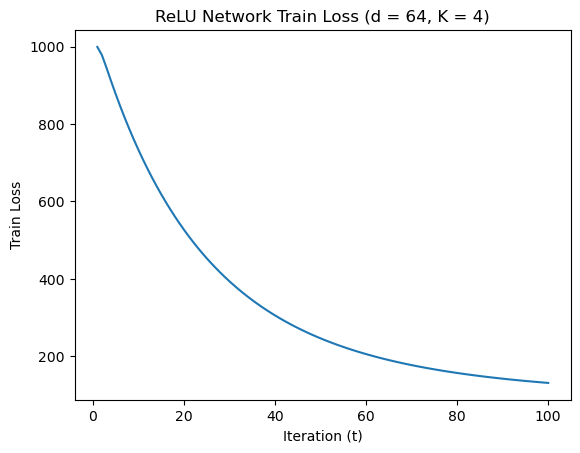

=== TRIAL 3 ===
Initializing weights using orthogonal method with scale 0.01


  0%|          | 0/100 [00:00<?, ?it/s]2026-10-15 13:48:29,848 - INFO - Finish Epoch 1
2026-10-15 13:48:29,849 - INFO - Train loss: 1000.14501953125, train accuracy: 21.6
2026-10-15 13:48:29,855 - INFO - Val loss: 978.7178955078125, val accuracy: 99.1
2026-10-15 13:48:29,863 - INFO - Finish Epoch 2
2026-10-15 13:48:29,864 - INFO - Train loss: 978.7178955078125, train accuracy: 99.1
2026-10-15 13:48:29,870 - INFO - Val loss: 957.8464965820312, val accuracy: 99.5
2026-10-15 13:48:29,878 - INFO - Finish Epoch 3
2026-10-15 13:48:29,879 - INFO - Train loss: 957.8464965820312, train accuracy: 99.5
2026-10-15 13:48:29,885 - INFO - Val loss: 937.4991455078125, val accuracy: 99.7
2026-10-15 13:48:29,892 - INFO - Finish Epoch 4
2026-10-15 13:48:29,893 - INFO - Train loss: 937.4991455078125, train accuracy: 99.7
2026-10-15 13:48:29,900 - INFO - Val loss: 917.6470947265625, val accuracy: 99.7
2026-10-15 13:48:29,907 - INFO - Finish Epoch 5
2026-10-15 13:48:29,908 - INFO - Train loss: 917.647094726

2026-10-15 13:48:30,396 - INFO - Train loss: 446.5271911621094, train accuracy: 99.8
2026-10-15 13:48:30,403 - INFO - Val loss: 436.5673522949219, val accuracy: 99.8
2026-10-15 13:48:30,410 - INFO - Finish Epoch 39
2026-10-15 13:48:30,411 - INFO - Train loss: 436.5673522949219, train accuracy: 99.8
2026-10-15 13:48:30,417 - INFO - Val loss: 426.83221435546875, val accuracy: 99.8
2026-10-15 13:48:30,424 - INFO - Finish Epoch 40
2026-10-15 13:48:30,425 - INFO - Train loss: 426.83221435546875, train accuracy: 99.8
2026-10-15 13:48:30,432 - INFO - Val loss: 417.3205871582031, val accuracy: 99.9
2026-10-15 13:48:30,439 - INFO - Finish Epoch 41
2026-10-15 13:48:30,440 - INFO - Train loss: 417.3205871582031, train accuracy: 99.9
2026-10-15 13:48:30,446 - INFO - Val loss: 408.03106689453125, val accuracy: 99.9
2026-10-15 13:48:30,453 - INFO - Finish Epoch 42
2026-10-15 13:48:30,455 - INFO - Train loss: 408.03106689453125, train accuracy: 99.9
2026-10-15 13:48:30,461 - INFO - Val loss: 398.9622

2026-10-15 13:48:30,939 - INFO - Train loss: 212.45150756835938, train accuracy: 99.8
2026-10-15 13:48:30,946 - INFO - Val loss: 209.31817626953125, val accuracy: 99.8
2026-10-15 13:48:30,953 - INFO - Finish Epoch 76
2026-10-15 13:48:30,954 - INFO - Train loss: 209.31817626953125, train accuracy: 99.8
2026-10-15 13:48:30,960 - INFO - Val loss: 206.30923461914062, val accuracy: 99.8
2026-10-15 13:48:30,967 - INFO - Finish Epoch 77
2026-10-15 13:48:30,968 - INFO - Train loss: 206.30923461914062, train accuracy: 99.8
2026-10-15 13:48:30,975 - INFO - Val loss: 203.42105102539062, val accuracy: 99.8
 77%|███████▋  | 77/100 [00:01<00:00, 68.01it/s]2026-10-15 13:48:30,983 - INFO - Finish Epoch 78
2026-10-15 13:48:30,984 - INFO - Train loss: 203.42105102539062, train accuracy: 99.8
2026-10-15 13:48:30,990 - INFO - Val loss: 200.65008544921875, val accuracy: 99.8
2026-10-15 13:48:30,998 - INFO - Finish Epoch 79
2026-10-15 13:48:30,999 - INFO - Train loss: 200.65008544921875, train accuracy: 99.

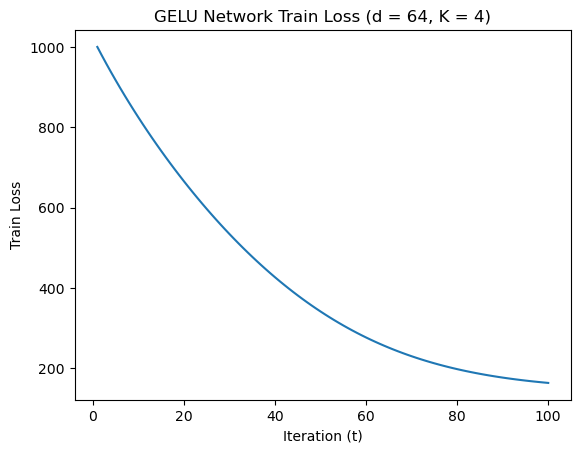

=== TRIAL 3 ===
Initializing weights using orthogonal method with scale 0.01


  0%|          | 0/100 [00:00<?, ?it/s]2026-10-15 13:48:31,465 - INFO - Finish Epoch 1
2026-10-15 13:48:31,467 - INFO - Train loss: 999.7794189453125, train accuracy: 23.2
2026-10-15 13:48:31,473 - INFO - Val loss: 974.6724853515625, val accuracy: 98.8
2026-10-15 13:48:31,480 - INFO - Finish Epoch 2
2026-10-15 13:48:31,482 - INFO - Train loss: 974.6724853515625, train accuracy: 98.8
2026-10-15 13:48:31,488 - INFO - Val loss: 937.5968017578125, val accuracy: 99.2
2026-10-15 13:48:31,495 - INFO - Finish Epoch 3
2026-10-15 13:48:31,496 - INFO - Train loss: 937.5968017578125, train accuracy: 99.2
2026-10-15 13:48:31,503 - INFO - Val loss: 898.4119262695312, val accuracy: 99.3
2026-10-15 13:48:31,510 - INFO - Finish Epoch 4
2026-10-15 13:48:31,511 - INFO - Train loss: 898.4119262695312, train accuracy: 99.3
2026-10-15 13:48:31,518 - INFO - Val loss: 860.410888671875, val accuracy: 99.3
2026-10-15 13:48:31,525 - INFO - Finish Epoch 5
2026-10-15 13:48:31,526 - INFO - Train loss: 860.410888671

2026-10-15 13:48:32,013 - INFO - Finish Epoch 38
2026-10-15 13:48:32,014 - INFO - Train loss: 213.15103149414062, train accuracy: 99.4
2026-10-15 13:48:32,020 - INFO - Val loss: 205.50289916992188, val accuracy: 99.4
2026-10-15 13:48:32,028 - INFO - Finish Epoch 39
2026-10-15 13:48:32,029 - INFO - Train loss: 205.50289916992188, train accuracy: 99.4
2026-10-15 13:48:32,035 - INFO - Val loss: 198.26535034179688, val accuracy: 99.4
2026-10-15 13:48:32,042 - INFO - Finish Epoch 40
2026-10-15 13:48:32,043 - INFO - Train loss: 198.26535034179688, train accuracy: 99.4
2026-10-15 13:48:32,050 - INFO - Val loss: 191.41891479492188, val accuracy: 99.4
2026-10-15 13:48:32,057 - INFO - Finish Epoch 41
2026-10-15 13:48:32,058 - INFO - Train loss: 191.41891479492188, train accuracy: 99.4
2026-10-15 13:48:32,064 - INFO - Val loss: 184.9441680908203, val accuracy: 99.4
2026-10-15 13:48:32,071 - INFO - Finish Epoch 42
2026-10-15 13:48:32,073 - INFO - Train loss: 184.9441680908203, train accuracy: 99.4

2026-10-15 13:48:32,558 - INFO - Finish Epoch 75
2026-10-15 13:48:32,560 - INFO - Train loss: 92.33834075927734, train accuracy: 99.6
2026-10-15 13:48:32,566 - INFO - Val loss: 91.42308044433594, val accuracy: 99.6
2026-10-15 13:48:32,573 - INFO - Finish Epoch 76
2026-10-15 13:48:32,574 - INFO - Train loss: 91.42308044433594, train accuracy: 99.6
2026-10-15 13:48:32,581 - INFO - Val loss: 90.55439758300781, val accuracy: 99.6
2026-10-15 13:48:32,588 - INFO - Finish Epoch 77
2026-10-15 13:48:32,589 - INFO - Train loss: 90.55439758300781, train accuracy: 99.6
2026-10-15 13:48:32,595 - INFO - Val loss: 89.72865295410156, val accuracy: 99.6
 77%|███████▋  | 77/100 [00:01<00:00, 67.81it/s]2026-10-15 13:48:32,603 - INFO - Finish Epoch 78
2026-10-15 13:48:32,605 - INFO - Train loss: 89.72865295410156, train accuracy: 99.6
2026-10-15 13:48:32,611 - INFO - Val loss: 88.94355773925781, val accuracy: 99.6
2026-10-15 13:48:32,618 - INFO - Finish Epoch 79
2026-10-15 13:48:32,619 - INFO - Train loss

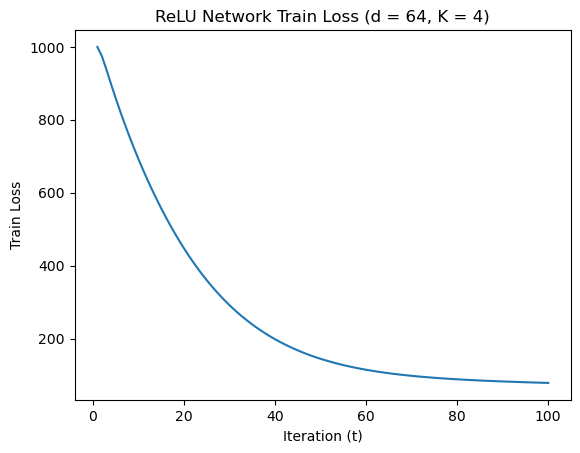

=== TRIAL 3 ===
Initializing weights using orthogonal method with scale 0.01


  0%|          | 0/100 [00:00<?, ?it/s]2026-10-15 13:48:33,086 - INFO - Finish Epoch 1
2026-10-15 13:48:33,087 - INFO - Train loss: 1000.005859375, train accuracy: 24.7
2026-10-15 13:48:33,093 - INFO - Val loss: 980.51953125, val accuracy: 99.7
2026-10-15 13:48:33,100 - INFO - Finish Epoch 2
2026-10-15 13:48:33,102 - INFO - Train loss: 980.51953125, train accuracy: 99.7
2026-10-15 13:48:33,265 - INFO - Val loss: 961.51220703125, val accuracy: 99.7
  2%|▏         | 2/100 [00:00<00:09, 10.62it/s]2026-10-15 13:48:33,275 - INFO - Finish Epoch 3
2026-10-15 13:48:33,276 - INFO - Train loss: 961.51220703125, train accuracy: 99.7
2026-10-15 13:48:33,282 - INFO - Val loss: 942.970947265625, val accuracy: 99.7
2026-10-15 13:48:33,290 - INFO - Finish Epoch 4
2026-10-15 13:48:33,291 - INFO - Train loss: 942.970947265625, train accuracy: 99.7
2026-10-15 13:48:33,297 - INFO - Val loss: 924.8836669921875, val accuracy: 99.7
2026-10-15 13:48:33,305 - INFO - Finish Epoch 5
2026-10-15 13:48:33,306 - INF

 37%|███▋      | 37/100 [00:00<00:01, 61.18it/s]2026-10-15 13:48:33,799 - INFO - Finish Epoch 38
2026-10-15 13:48:33,800 - INFO - Train loss: 519.1727905273438, train accuracy: 99.7
2026-10-15 13:48:33,806 - INFO - Val loss: 511.168212890625, val accuracy: 99.7
2026-10-15 13:48:33,813 - INFO - Finish Epoch 39
2026-10-15 13:48:33,815 - INFO - Train loss: 511.168212890625, train accuracy: 99.7
2026-10-15 13:48:33,821 - INFO - Val loss: 503.3472595214844, val accuracy: 99.7
2026-10-15 13:48:33,828 - INFO - Finish Epoch 40
2026-10-15 13:48:33,830 - INFO - Train loss: 503.3472595214844, train accuracy: 99.7
2026-10-15 13:48:33,836 - INFO - Val loss: 495.7054443359375, val accuracy: 99.7
2026-10-15 13:48:33,843 - INFO - Finish Epoch 41
2026-10-15 13:48:33,844 - INFO - Train loss: 495.7054443359375, train accuracy: 99.7
2026-10-15 13:48:33,851 - INFO - Val loss: 488.2384033203125, val accuracy: 99.7
2026-10-15 13:48:33,858 - INFO - Finish Epoch 42
2026-10-15 13:48:33,859 - INFO - Train loss: 

2026-10-15 13:48:34,357 - INFO - Finish Epoch 75
2026-10-15 13:48:34,359 - INFO - Train loss: 316.7734375, train accuracy: 99.8
2026-10-15 13:48:34,365 - INFO - Val loss: 313.2926940917969, val accuracy: 99.8
2026-10-15 13:48:34,372 - INFO - Finish Epoch 76
2026-10-15 13:48:34,373 - INFO - Train loss: 313.2926940917969, train accuracy: 99.8
2026-10-15 13:48:34,380 - INFO - Val loss: 309.88702392578125, val accuracy: 99.8
2026-10-15 13:48:34,387 - INFO - Finish Epoch 77
2026-10-15 13:48:34,388 - INFO - Train loss: 309.88702392578125, train accuracy: 99.8
2026-10-15 13:48:34,395 - INFO - Val loss: 306.5546875, val accuracy: 99.8
2026-10-15 13:48:34,402 - INFO - Finish Epoch 78
2026-10-15 13:48:34,403 - INFO - Train loss: 306.5546875, train accuracy: 99.8
2026-10-15 13:48:34,410 - INFO - Val loss: 303.2939758300781, val accuracy: 99.8
2026-10-15 13:48:34,417 - INFO - Finish Epoch 79
2026-10-15 13:48:34,418 - INFO - Train loss: 303.2939758300781, train accuracy: 99.8
2026-10-15 13:48:34,42

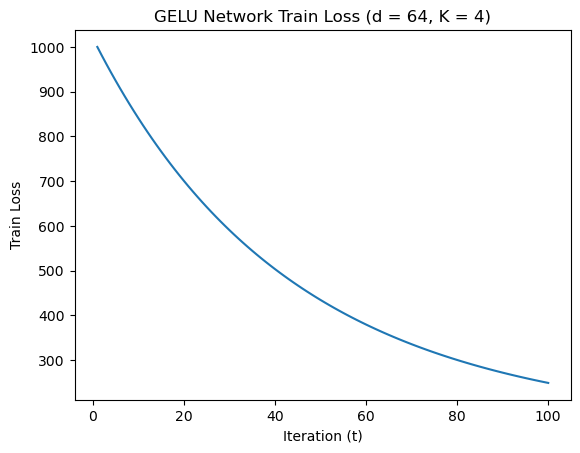

=== TRIAL 3 ===
Initializing weights using orthogonal method with scale 0.01


  0%|          | 0/100 [00:00<?, ?it/s]2026-10-15 13:48:34,906 - INFO - Finish Epoch 1
2026-10-15 13:48:34,907 - INFO - Train loss: 999.7581176757812, train accuracy: 31.8
2026-10-15 13:48:34,915 - INFO - Val loss: 977.5125732421875, val accuracy: 98.5
2026-10-15 13:48:34,922 - INFO - Finish Epoch 2
2026-10-15 13:48:34,924 - INFO - Train loss: 977.5125732421875, train accuracy: 98.5
2026-10-15 13:48:34,930 - INFO - Val loss: 945.0117797851562, val accuracy: 99.1
2026-10-15 13:48:34,937 - INFO - Finish Epoch 3
2026-10-15 13:48:34,938 - INFO - Train loss: 945.0117797851562, train accuracy: 99.1
2026-10-15 13:48:34,945 - INFO - Val loss: 911.386474609375, val accuracy: 99.1
2026-10-15 13:48:34,952 - INFO - Finish Epoch 4
2026-10-15 13:48:34,953 - INFO - Train loss: 911.386474609375, train accuracy: 99.1
2026-10-15 13:48:34,960 - INFO - Val loss: 878.8809814453125, val accuracy: 99.2
2026-10-15 13:48:34,967 - INFO - Finish Epoch 5
2026-10-15 13:48:34,968 - INFO - Train loss: 878.8809814453

2026-10-15 13:48:35,458 - INFO - Train loss: 327.858154296875, train accuracy: 99.8
2026-10-15 13:48:35,465 - INFO - Val loss: 320.361083984375, val accuracy: 99.8
2026-10-15 13:48:35,472 - INFO - Finish Epoch 39
2026-10-15 13:48:35,473 - INFO - Train loss: 320.361083984375, train accuracy: 99.8
2026-10-15 13:48:35,479 - INFO - Val loss: 313.1548767089844, val accuracy: 99.8
2026-10-15 13:48:35,486 - INFO - Finish Epoch 40
2026-10-15 13:48:35,487 - INFO - Train loss: 313.1548767089844, train accuracy: 99.8
2026-10-15 13:48:35,494 - INFO - Val loss: 306.22393798828125, val accuracy: 99.8
2026-10-15 13:48:35,501 - INFO - Finish Epoch 41
2026-10-15 13:48:35,502 - INFO - Train loss: 306.22393798828125, train accuracy: 99.8
2026-10-15 13:48:35,508 - INFO - Val loss: 299.558349609375, val accuracy: 99.8
2026-10-15 13:48:35,515 - INFO - Finish Epoch 42
2026-10-15 13:48:35,517 - INFO - Train loss: 299.558349609375, train accuracy: 99.8
2026-10-15 13:48:35,523 - INFO - Val loss: 293.14392089843

2026-10-15 13:48:36,005 - INFO - Train loss: 172.92283630371094, train accuracy: 99.8
2026-10-15 13:48:36,012 - INFO - Val loss: 170.81668090820312, val accuracy: 99.8
2026-10-15 13:48:36,019 - INFO - Finish Epoch 76
2026-10-15 13:48:36,020 - INFO - Train loss: 170.81668090820312, train accuracy: 99.8
2026-10-15 13:48:36,026 - INFO - Val loss: 168.77157592773438, val accuracy: 99.8
2026-10-15 13:48:36,033 - INFO - Finish Epoch 77
2026-10-15 13:48:36,034 - INFO - Train loss: 168.77157592773438, train accuracy: 99.8
2026-10-15 13:48:36,041 - INFO - Val loss: 166.78433227539062, val accuracy: 99.8
 77%|███████▋  | 77/100 [00:01<00:00, 67.55it/s]2026-10-15 13:48:36,049 - INFO - Finish Epoch 78
2026-10-15 13:48:36,050 - INFO - Train loss: 166.78433227539062, train accuracy: 99.8
2026-10-15 13:48:36,057 - INFO - Val loss: 164.85321044921875, val accuracy: 99.8
2026-10-15 13:48:36,064 - INFO - Finish Epoch 79
2026-10-15 13:48:36,065 - INFO - Train loss: 164.85321044921875, train accuracy: 99.

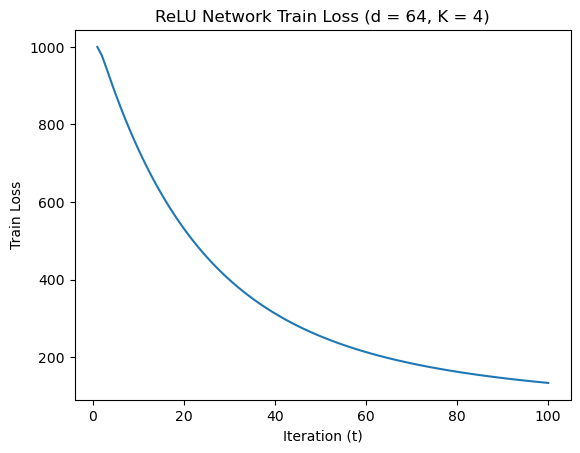

=== TRIAL 4 ===
Initializing weights using orthogonal method with scale 0.01


  0%|          | 0/100 [00:00<?, ?it/s]2026-10-15 13:48:36,536 - INFO - Finish Epoch 1
2026-10-15 13:48:36,537 - INFO - Train loss: 1000.291259765625, train accuracy: 20.7
2026-10-15 13:48:36,544 - INFO - Val loss: 979.3548583984375, val accuracy: 99.9
2026-10-15 13:48:36,551 - INFO - Finish Epoch 2
2026-10-15 13:48:36,552 - INFO - Train loss: 979.3548583984375, train accuracy: 99.9
2026-10-15 13:48:36,559 - INFO - Val loss: 958.9345703125, val accuracy: 100.0
2026-10-15 13:48:36,566 - INFO - Finish Epoch 3
2026-10-15 13:48:36,567 - INFO - Train loss: 958.9345703125, train accuracy: 100.0
2026-10-15 13:48:36,573 - INFO - Val loss: 939.0006103515625, val accuracy: 100.0
2026-10-15 13:48:36,580 - INFO - Finish Epoch 4
2026-10-15 13:48:36,582 - INFO - Train loss: 939.0006103515625, train accuracy: 100.0
2026-10-15 13:48:36,588 - INFO - Val loss: 919.5260620117188, val accuracy: 100.0
2026-10-15 13:48:36,595 - INFO - Finish Epoch 5
2026-10-15 13:48:36,596 - INFO - Train loss: 919.526062011

2026-10-15 13:48:37,083 - INFO - Finish Epoch 38
2026-10-15 13:48:37,084 - INFO - Train loss: 447.6787109375, train accuracy: 100.0
2026-10-15 13:48:37,091 - INFO - Val loss: 437.45782470703125, val accuracy: 100.0
2026-10-15 13:48:37,098 - INFO - Finish Epoch 39
2026-10-15 13:48:37,099 - INFO - Train loss: 437.45782470703125, train accuracy: 100.0
2026-10-15 13:48:37,105 - INFO - Val loss: 427.45654296875, val accuracy: 100.0
2026-10-15 13:48:37,112 - INFO - Finish Epoch 40
2026-10-15 13:48:37,113 - INFO - Train loss: 427.45654296875, train accuracy: 100.0
2026-10-15 13:48:37,120 - INFO - Val loss: 417.6744384765625, val accuracy: 100.0
2026-10-15 13:48:37,127 - INFO - Finish Epoch 41
2026-10-15 13:48:37,128 - INFO - Train loss: 417.6744384765625, train accuracy: 100.0
2026-10-15 13:48:37,134 - INFO - Val loss: 408.1108703613281, val accuracy: 100.0
2026-10-15 13:48:37,141 - INFO - Finish Epoch 42
2026-10-15 13:48:37,143 - INFO - Train loss: 408.1108703613281, train accuracy: 100.0
20

2026-10-15 13:48:37,770 - INFO - Val loss: 204.84866333007812, val accuracy: 100.0
2026-10-15 13:48:37,777 - INFO - Finish Epoch 75
2026-10-15 13:48:37,778 - INFO - Train loss: 204.84866333007812, train accuracy: 100.0
2026-10-15 13:48:37,784 - INFO - Val loss: 201.5777130126953, val accuracy: 100.0
2026-10-15 13:48:37,792 - INFO - Finish Epoch 76
2026-10-15 13:48:37,793 - INFO - Train loss: 201.5777130126953, train accuracy: 100.0
2026-10-15 13:48:37,799 - INFO - Val loss: 198.43728637695312, val accuracy: 100.0
2026-10-15 13:48:37,806 - INFO - Finish Epoch 77
2026-10-15 13:48:37,808 - INFO - Train loss: 198.43728637695312, train accuracy: 100.0
2026-10-15 13:48:37,814 - INFO - Val loss: 195.42369079589844, val accuracy: 100.0
 77%|███████▋  | 77/100 [00:01<00:00, 55.69it/s]2026-10-15 13:48:37,822 - INFO - Finish Epoch 78
2026-10-15 13:48:37,823 - INFO - Train loss: 195.42369079589844, train accuracy: 100.0
2026-10-15 13:48:37,830 - INFO - Val loss: 192.5331573486328, val accuracy: 10

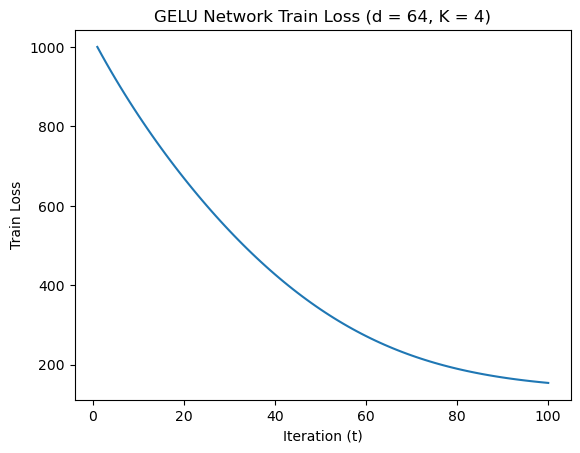

=== TRIAL 4 ===
Initializing weights using orthogonal method with scale 0.01


  0%|          | 0/100 [00:00<?, ?it/s]2026-10-15 13:48:38,305 - INFO - Finish Epoch 1
2026-10-15 13:48:38,306 - INFO - Train loss: 1000.50048828125, train accuracy: 24.6
2026-10-15 13:48:38,312 - INFO - Val loss: 979.1610107421875, val accuracy: 97.3
2026-10-15 13:48:38,320 - INFO - Finish Epoch 2
2026-10-15 13:48:38,321 - INFO - Train loss: 979.1610107421875, train accuracy: 97.3
2026-10-15 13:48:38,328 - INFO - Val loss: 948.3938598632812, val accuracy: 98.8
2026-10-15 13:48:38,335 - INFO - Finish Epoch 3
2026-10-15 13:48:38,336 - INFO - Train loss: 948.3938598632812, train accuracy: 98.8
2026-10-15 13:48:38,342 - INFO - Val loss: 916.329833984375, val accuracy: 98.7
2026-10-15 13:48:38,350 - INFO - Finish Epoch 4
2026-10-15 13:48:38,351 - INFO - Train loss: 916.329833984375, train accuracy: 98.7
2026-10-15 13:48:38,357 - INFO - Val loss: 885.1583251953125, val accuracy: 99.0
2026-10-15 13:48:38,364 - INFO - Finish Epoch 5
2026-10-15 13:48:38,365 - INFO - Train loss: 885.15832519531

2026-10-15 13:48:38,851 - INFO - Train loss: 251.27047729492188, train accuracy: 99.8
2026-10-15 13:48:38,858 - INFO - Val loss: 241.66995239257812, val accuracy: 99.8
2026-10-15 13:48:38,865 - INFO - Finish Epoch 39
2026-10-15 13:48:38,866 - INFO - Train loss: 241.66995239257812, train accuracy: 99.8
2026-10-15 13:48:38,872 - INFO - Val loss: 232.526123046875, val accuracy: 99.9
2026-10-15 13:48:38,879 - INFO - Finish Epoch 40
2026-10-15 13:48:38,881 - INFO - Train loss: 232.526123046875, train accuracy: 99.9
2026-10-15 13:48:38,887 - INFO - Val loss: 223.82516479492188, val accuracy: 99.9
2026-10-15 13:48:38,894 - INFO - Finish Epoch 41
2026-10-15 13:48:38,895 - INFO - Train loss: 223.82516479492188, train accuracy: 99.9
2026-10-15 13:48:38,901 - INFO - Val loss: 215.55165100097656, val accuracy: 99.9
2026-10-15 13:48:38,908 - INFO - Finish Epoch 42
2026-10-15 13:48:38,910 - INFO - Train loss: 215.55165100097656, train accuracy: 99.9
2026-10-15 13:48:38,916 - INFO - Val loss: 207.691

2026-10-15 13:48:39,397 - INFO - Train loss: 93.03931427001953, train accuracy: 99.9
2026-10-15 13:48:39,403 - INFO - Val loss: 91.80558776855469, val accuracy: 99.9
2026-10-15 13:48:39,410 - INFO - Finish Epoch 76
2026-10-15 13:48:39,411 - INFO - Train loss: 91.80558776855469, train accuracy: 99.9
2026-10-15 13:48:39,418 - INFO - Val loss: 90.63558959960938, val accuracy: 99.9
2026-10-15 13:48:39,425 - INFO - Finish Epoch 77
2026-10-15 13:48:39,426 - INFO - Train loss: 90.63558959960938, train accuracy: 99.9
2026-10-15 13:48:39,432 - INFO - Val loss: 89.52591705322266, val accuracy: 99.9
 77%|███████▋  | 77/100 [00:01<00:00, 67.87it/s]2026-10-15 13:48:39,440 - INFO - Finish Epoch 78
2026-10-15 13:48:39,441 - INFO - Train loss: 89.52591705322266, train accuracy: 99.9
2026-10-15 13:48:39,448 - INFO - Val loss: 88.47235107421875, val accuracy: 99.9
2026-10-15 13:48:39,455 - INFO - Finish Epoch 79
2026-10-15 13:48:39,456 - INFO - Train loss: 88.47235107421875, train accuracy: 99.9
2026-10

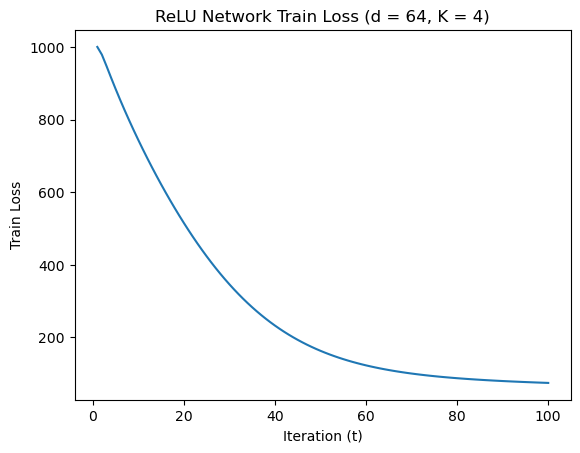

=== TRIAL 4 ===
Initializing weights using orthogonal method with scale 0.01


  0%|          | 0/100 [00:00<?, ?it/s]2026-10-15 13:48:39,923 - INFO - Finish Epoch 1
2026-10-15 13:48:39,924 - INFO - Train loss: 1000.032958984375, train accuracy: 20.4
2026-10-15 13:48:39,931 - INFO - Val loss: 978.90478515625, val accuracy: 99.8
2026-10-15 13:48:39,938 - INFO - Finish Epoch 2
2026-10-15 13:48:39,939 - INFO - Train loss: 978.90478515625, train accuracy: 99.8
2026-10-15 13:48:39,946 - INFO - Val loss: 958.3036499023438, val accuracy: 99.8
2026-10-15 13:48:39,953 - INFO - Finish Epoch 3
2026-10-15 13:48:39,954 - INFO - Train loss: 958.3036499023438, train accuracy: 99.8
2026-10-15 13:48:39,961 - INFO - Val loss: 938.2159423828125, val accuracy: 99.9
2026-10-15 13:48:39,968 - INFO - Finish Epoch 4
2026-10-15 13:48:39,969 - INFO - Train loss: 938.2159423828125, train accuracy: 99.9
2026-10-15 13:48:39,975 - INFO - Val loss: 918.6287841796875, val accuracy: 99.9
2026-10-15 13:48:39,983 - INFO - Finish Epoch 5
2026-10-15 13:48:39,984 - INFO - Train loss: 918.628784179687

2026-10-15 13:48:40,472 - INFO - Train loss: 484.16986083984375, train accuracy: 99.9
2026-10-15 13:48:40,478 - INFO - Val loss: 475.7738037109375, val accuracy: 99.9
2026-10-15 13:48:40,485 - INFO - Finish Epoch 39
2026-10-15 13:48:40,486 - INFO - Train loss: 475.7738037109375, train accuracy: 99.9
2026-10-15 13:48:40,492 - INFO - Val loss: 467.58184814453125, val accuracy: 99.9
2026-10-15 13:48:40,500 - INFO - Finish Epoch 40
2026-10-15 13:48:40,501 - INFO - Train loss: 467.58184814453125, train accuracy: 99.9
2026-10-15 13:48:40,507 - INFO - Val loss: 459.5888977050781, val accuracy: 99.9
2026-10-15 13:48:40,514 - INFO - Finish Epoch 41
2026-10-15 13:48:40,515 - INFO - Train loss: 459.5888977050781, train accuracy: 99.9
2026-10-15 13:48:40,522 - INFO - Val loss: 451.7900085449219, val accuracy: 99.9
2026-10-15 13:48:40,529 - INFO - Finish Epoch 42
2026-10-15 13:48:40,530 - INFO - Train loss: 451.7900085449219, train accuracy: 99.9
2026-10-15 13:48:40,536 - INFO - Val loss: 444.18032

2026-10-15 13:48:41,018 - INFO - Train loss: 277.1512451171875, train accuracy: 99.9
2026-10-15 13:48:41,024 - INFO - Val loss: 273.7340393066406, val accuracy: 99.9
2026-10-15 13:48:41,031 - INFO - Finish Epoch 76
2026-10-15 13:48:41,033 - INFO - Train loss: 273.7340393066406, train accuracy: 99.9
2026-10-15 13:48:41,039 - INFO - Val loss: 270.39776611328125, val accuracy: 99.9
2026-10-15 13:48:41,046 - INFO - Finish Epoch 77
2026-10-15 13:48:41,047 - INFO - Train loss: 270.39776611328125, train accuracy: 99.9
2026-10-15 13:48:41,054 - INFO - Val loss: 267.140380859375, val accuracy: 99.9
 77%|███████▋  | 77/100 [00:01<00:00, 67.66it/s]2026-10-15 13:48:41,062 - INFO - Finish Epoch 78
2026-10-15 13:48:41,063 - INFO - Train loss: 267.140380859375, train accuracy: 99.9
2026-10-15 13:48:41,069 - INFO - Val loss: 263.9599609375, val accuracy: 99.9
2026-10-15 13:48:41,076 - INFO - Finish Epoch 79
2026-10-15 13:48:41,078 - INFO - Train loss: 263.9599609375, train accuracy: 99.9
2026-10-15 13

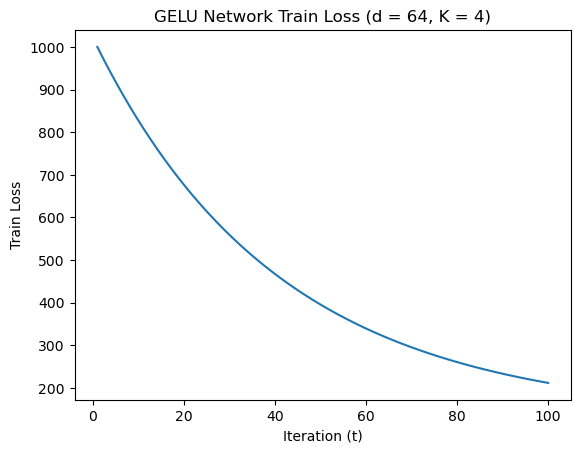

=== TRIAL 4 ===
Initializing weights using orthogonal method with scale 0.01


  0%|          | 0/100 [00:00<?, ?it/s]2026-10-15 13:48:41,563 - INFO - Finish Epoch 1
2026-10-15 13:48:41,565 - INFO - Train loss: 999.6620483398438, train accuracy: 21.6
2026-10-15 13:48:41,571 - INFO - Val loss: 978.406982421875, val accuracy: 99.3
2026-10-15 13:48:41,578 - INFO - Finish Epoch 2
2026-10-15 13:48:41,579 - INFO - Train loss: 978.406982421875, train accuracy: 99.3
2026-10-15 13:48:41,726 - INFO - Val loss: 944.047607421875, val accuracy: 99.9
  2%|▏         | 2/100 [00:00<00:08, 11.67it/s]2026-10-15 13:48:41,735 - INFO - Finish Epoch 3
2026-10-15 13:48:41,737 - INFO - Train loss: 944.047607421875, train accuracy: 99.9
2026-10-15 13:48:41,743 - INFO - Val loss: 907.2559204101562, val accuracy: 100.0
2026-10-15 13:48:41,750 - INFO - Finish Epoch 4
2026-10-15 13:48:41,751 - INFO - Train loss: 907.2559204101562, train accuracy: 100.0
2026-10-15 13:48:41,758 - INFO - Val loss: 871.6624145507812, val accuracy: 100.0
2026-10-15 13:48:41,765 - INFO - Finish Epoch 5
2026-10-15 

 37%|███▋      | 37/100 [00:00<00:01, 62.40it/s]2026-10-15 13:48:42,254 - INFO - Finish Epoch 38
2026-10-15 13:48:42,255 - INFO - Train loss: 284.9520568847656, train accuracy: 100.0
2026-10-15 13:48:42,261 - INFO - Val loss: 277.31695556640625, val accuracy: 100.0
2026-10-15 13:48:42,268 - INFO - Finish Epoch 39
2026-10-15 13:48:42,270 - INFO - Train loss: 277.31695556640625, train accuracy: 100.0
2026-10-15 13:48:42,276 - INFO - Val loss: 269.9961853027344, val accuracy: 100.0
2026-10-15 13:48:42,283 - INFO - Finish Epoch 40
2026-10-15 13:48:42,284 - INFO - Train loss: 269.9961853027344, train accuracy: 100.0
2026-10-15 13:48:42,291 - INFO - Val loss: 262.9750061035156, val accuracy: 100.0
2026-10-15 13:48:42,298 - INFO - Finish Epoch 41
2026-10-15 13:48:42,299 - INFO - Train loss: 262.9750061035156, train accuracy: 100.0
2026-10-15 13:48:42,305 - INFO - Val loss: 256.2396240234375, val accuracy: 100.0
2026-10-15 13:48:42,312 - INFO - Finish Epoch 42
2026-10-15 13:48:42,313 - INFO - 

2026-10-15 13:48:42,791 - INFO - Train loss: 136.16357421875, train accuracy: 100.0
2026-10-15 13:48:42,797 - INFO - Val loss: 134.23666381835938, val accuracy: 100.0
2026-10-15 13:48:42,804 - INFO - Finish Epoch 75
2026-10-15 13:48:42,805 - INFO - Train loss: 134.23666381835938, train accuracy: 100.0
2026-10-15 13:48:42,812 - INFO - Val loss: 132.37425231933594, val accuracy: 100.0
2026-10-15 13:48:42,819 - INFO - Finish Epoch 76
2026-10-15 13:48:42,820 - INFO - Train loss: 132.37425231933594, train accuracy: 100.0
2026-10-15 13:48:42,827 - INFO - Val loss: 130.5743408203125, val accuracy: 100.0
2026-10-15 13:48:42,834 - INFO - Finish Epoch 77
2026-10-15 13:48:42,835 - INFO - Train loss: 130.5743408203125, train accuracy: 100.0
2026-10-15 13:48:42,841 - INFO - Val loss: 128.83450317382812, val accuracy: 100.0
2026-10-15 13:48:42,848 - INFO - Finish Epoch 78
2026-10-15 13:48:42,850 - INFO - Train loss: 128.83450317382812, train accuracy: 100.0
2026-10-15 13:48:42,856 - INFO - Val loss:

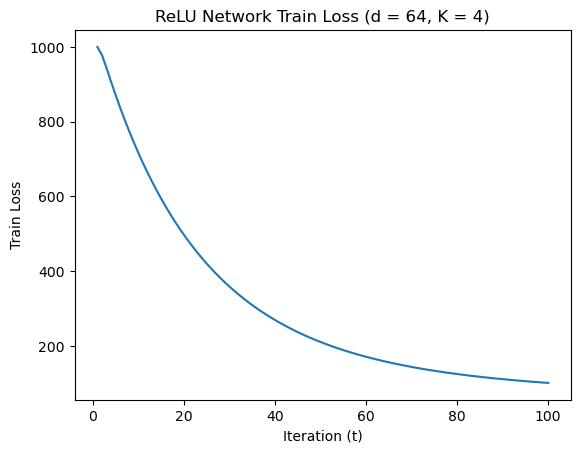

=== TRIAL 5 ===
Initializing weights using orthogonal method with scale 0.01


  0%|          | 0/100 [00:00<?, ?it/s]2026-10-15 13:48:43,334 - INFO - Finish Epoch 1
2026-10-15 13:48:43,335 - INFO - Train loss: 1000.287841796875, train accuracy: 20.7
2026-10-15 13:48:43,343 - INFO - Val loss: 979.2909545898438, val accuracy: 99.7
2026-10-15 13:48:43,350 - INFO - Finish Epoch 2
2026-10-15 13:48:43,351 - INFO - Train loss: 979.2909545898438, train accuracy: 99.7
2026-10-15 13:48:43,357 - INFO - Val loss: 958.8255004882812, val accuracy: 99.8
2026-10-15 13:48:43,365 - INFO - Finish Epoch 3
2026-10-15 13:48:43,366 - INFO - Train loss: 958.8255004882812, train accuracy: 99.8
2026-10-15 13:48:43,372 - INFO - Val loss: 938.8610229492188, val accuracy: 100.0
2026-10-15 13:48:43,380 - INFO - Finish Epoch 4
2026-10-15 13:48:43,381 - INFO - Train loss: 938.8610229492188, train accuracy: 100.0
2026-10-15 13:48:43,387 - INFO - Val loss: 919.3697509765625, val accuracy: 100.0
2026-10-15 13:48:43,394 - INFO - Finish Epoch 5
2026-10-15 13:48:43,396 - INFO - Train loss: 919.36975

2026-10-15 13:48:43,889 - INFO - Finish Epoch 38
2026-10-15 13:48:43,891 - INFO - Train loss: 451.57177734375, train accuracy: 100.0
2026-10-15 13:48:43,897 - INFO - Val loss: 441.52984619140625, val accuracy: 100.0
2026-10-15 13:48:43,904 - INFO - Finish Epoch 39
2026-10-15 13:48:43,905 - INFO - Train loss: 441.52984619140625, train accuracy: 100.0
2026-10-15 13:48:43,912 - INFO - Val loss: 431.7057189941406, val accuracy: 100.0
2026-10-15 13:48:43,919 - INFO - Finish Epoch 40
2026-10-15 13:48:43,920 - INFO - Train loss: 431.7057189941406, train accuracy: 100.0
2026-10-15 13:48:43,927 - INFO - Val loss: 422.098388671875, val accuracy: 100.0
2026-10-15 13:48:43,934 - INFO - Finish Epoch 41
2026-10-15 13:48:43,935 - INFO - Train loss: 422.098388671875, train accuracy: 100.0
2026-10-15 13:48:43,942 - INFO - Val loss: 412.70684814453125, val accuracy: 100.0
2026-10-15 13:48:43,949 - INFO - Finish Epoch 42
2026-10-15 13:48:43,950 - INFO - Train loss: 412.70684814453125, train accuracy: 100

2026-10-15 13:48:44,436 - INFO - Val loss: 211.8286895751953, val accuracy: 100.0
2026-10-15 13:48:44,443 - INFO - Finish Epoch 75
2026-10-15 13:48:44,444 - INFO - Train loss: 211.8286895751953, train accuracy: 100.0
2026-10-15 13:48:44,451 - INFO - Val loss: 208.52066040039062, val accuracy: 100.0
2026-10-15 13:48:44,458 - INFO - Finish Epoch 76
2026-10-15 13:48:44,459 - INFO - Train loss: 208.52066040039062, train accuracy: 100.0
2026-10-15 13:48:44,465 - INFO - Val loss: 205.33853149414062, val accuracy: 100.0
2026-10-15 13:48:44,472 - INFO - Finish Epoch 77
2026-10-15 13:48:44,474 - INFO - Train loss: 205.33853149414062, train accuracy: 100.0
2026-10-15 13:48:44,480 - INFO - Val loss: 202.27880859375, val accuracy: 100.0
 77%|███████▋  | 77/100 [00:01<00:00, 66.85it/s]2026-10-15 13:48:44,488 - INFO - Finish Epoch 78
2026-10-15 13:48:44,489 - INFO - Train loss: 202.27880859375, train accuracy: 100.0
2026-10-15 13:48:44,496 - INFO - Val loss: 199.33807373046875, val accuracy: 100.0
2

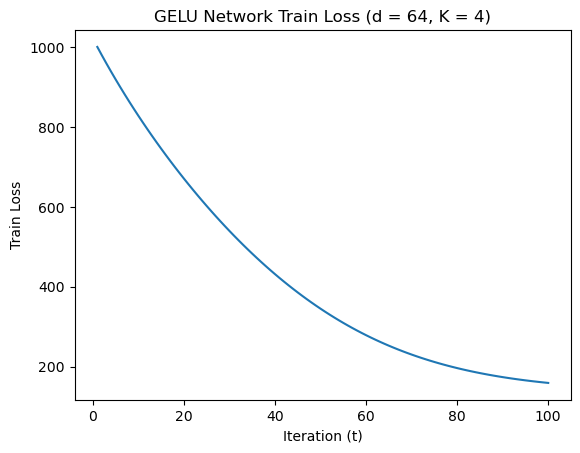

=== TRIAL 5 ===
Initializing weights using orthogonal method with scale 0.01


  0%|          | 0/100 [00:00<?, ?it/s]2026-10-15 13:48:44,973 - INFO - Finish Epoch 1
2026-10-15 13:48:44,974 - INFO - Train loss: 999.99609375, train accuracy: 27.8
2026-10-15 13:48:44,981 - INFO - Val loss: 975.38623046875, val accuracy: 99.2
2026-10-15 13:48:44,988 - INFO - Finish Epoch 2
2026-10-15 13:48:44,989 - INFO - Train loss: 975.38623046875, train accuracy: 99.2
2026-10-15 13:48:44,996 - INFO - Val loss: 937.617919921875, val accuracy: 99.8
2026-10-15 13:48:45,003 - INFO - Finish Epoch 3
2026-10-15 13:48:45,004 - INFO - Train loss: 937.617919921875, train accuracy: 99.8
2026-10-15 13:48:45,011 - INFO - Val loss: 898.390869140625, val accuracy: 99.8
2026-10-15 13:48:45,018 - INFO - Finish Epoch 4
2026-10-15 13:48:45,019 - INFO - Train loss: 898.390869140625, train accuracy: 99.8
2026-10-15 13:48:45,025 - INFO - Val loss: 860.6902465820312, val accuracy: 99.8
2026-10-15 13:48:45,033 - INFO - Finish Epoch 5
2026-10-15 13:48:45,034 - INFO - Train loss: 860.6902465820312, train 

2026-10-15 13:48:45,672 - INFO - Train loss: 186.4205322265625, train accuracy: 99.9
2026-10-15 13:48:45,678 - INFO - Val loss: 178.85354614257812, val accuracy: 99.9
2026-10-15 13:48:45,685 - INFO - Finish Epoch 39
2026-10-15 13:48:45,686 - INFO - Train loss: 178.85354614257812, train accuracy: 99.9
2026-10-15 13:48:45,693 - INFO - Val loss: 171.78323364257812, val accuracy: 100.0
2026-10-15 13:48:45,700 - INFO - Finish Epoch 40
2026-10-15 13:48:45,701 - INFO - Train loss: 171.78323364257812, train accuracy: 100.0
2026-10-15 13:48:45,708 - INFO - Val loss: 165.18267822265625, val accuracy: 100.0
2026-10-15 13:48:45,715 - INFO - Finish Epoch 41
2026-10-15 13:48:45,716 - INFO - Train loss: 165.18267822265625, train accuracy: 100.0
2026-10-15 13:48:45,722 - INFO - Val loss: 159.02569580078125, val accuracy: 100.0
2026-10-15 13:48:45,729 - INFO - Finish Epoch 42
2026-10-15 13:48:45,731 - INFO - Train loss: 159.02569580078125, train accuracy: 100.0
2026-10-15 13:48:45,737 - INFO - Val loss

2026-10-15 13:48:46,220 - INFO - Finish Epoch 75
2026-10-15 13:48:46,221 - INFO - Train loss: 82.5188980102539, train accuracy: 100.0
2026-10-15 13:48:46,227 - INFO - Val loss: 81.84764862060547, val accuracy: 100.0
2026-10-15 13:48:46,234 - INFO - Finish Epoch 76
2026-10-15 13:48:46,236 - INFO - Train loss: 81.84764862060547, train accuracy: 100.0
2026-10-15 13:48:46,242 - INFO - Val loss: 81.2079849243164, val accuracy: 100.0
2026-10-15 13:48:46,249 - INFO - Finish Epoch 77
2026-10-15 13:48:46,250 - INFO - Train loss: 81.2079849243164, train accuracy: 100.0
2026-10-15 13:48:46,257 - INFO - Val loss: 80.59780883789062, val accuracy: 100.0
 77%|███████▋  | 77/100 [00:01<00:00, 65.02it/s]2026-10-15 13:48:46,265 - INFO - Finish Epoch 78
2026-10-15 13:48:46,266 - INFO - Train loss: 80.59780883789062, train accuracy: 100.0
2026-10-15 13:48:46,272 - INFO - Val loss: 80.01475524902344, val accuracy: 100.0
2026-10-15 13:48:46,280 - INFO - Finish Epoch 79
2026-10-15 13:48:46,281 - INFO - Train

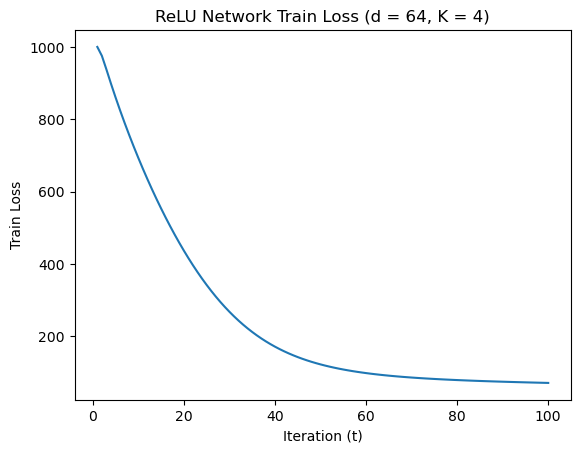

=== TRIAL 5 ===
Initializing weights using orthogonal method with scale 0.01


  0%|          | 0/100 [00:00<?, ?it/s]2026-10-15 13:48:46,759 - INFO - Finish Epoch 1
2026-10-15 13:48:46,761 - INFO - Train loss: 999.8983154296875, train accuracy: 23.4
2026-10-15 13:48:46,768 - INFO - Val loss: 979.5415649414062, val accuracy: 99.9
2026-10-15 13:48:46,776 - INFO - Finish Epoch 2
2026-10-15 13:48:46,777 - INFO - Train loss: 979.5415649414062, train accuracy: 99.9
2026-10-15 13:48:46,784 - INFO - Val loss: 959.6815185546875, val accuracy: 99.9
2026-10-15 13:48:46,792 - INFO - Finish Epoch 3
2026-10-15 13:48:46,794 - INFO - Train loss: 959.6815185546875, train accuracy: 99.9
2026-10-15 13:48:46,801 - INFO - Val loss: 940.3057861328125, val accuracy: 100.0
2026-10-15 13:48:46,809 - INFO - Finish Epoch 4
2026-10-15 13:48:46,811 - INFO - Train loss: 940.3057861328125, train accuracy: 100.0
2026-10-15 13:48:46,817 - INFO - Val loss: 921.4022216796875, val accuracy: 100.0
2026-10-15 13:48:46,825 - INFO - Finish Epoch 5
2026-10-15 13:48:46,826 - INFO - Train loss: 921.40222

2026-10-15 13:48:47,345 - INFO - Finish Epoch 38
2026-10-15 13:48:47,347 - INFO - Train loss: 498.82904052734375, train accuracy: 100.0
2026-10-15 13:48:47,353 - INFO - Val loss: 490.58355712890625, val accuracy: 100.0
2026-10-15 13:48:47,361 - INFO - Finish Epoch 39
2026-10-15 13:48:47,362 - INFO - Train loss: 490.58355712890625, train accuracy: 100.0
2026-10-15 13:48:47,369 - INFO - Val loss: 482.53466796875, val accuracy: 100.0
2026-10-15 13:48:47,376 - INFO - Finish Epoch 40
2026-10-15 13:48:47,378 - INFO - Train loss: 482.53466796875, train accuracy: 100.0
2026-10-15 13:48:47,385 - INFO - Val loss: 474.6776123046875, val accuracy: 100.0
2026-10-15 13:48:47,392 - INFO - Finish Epoch 41
2026-10-15 13:48:47,393 - INFO - Train loss: 474.6776123046875, train accuracy: 100.0
2026-10-15 13:48:47,400 - INFO - Val loss: 467.0076599121094, val accuracy: 100.0
2026-10-15 13:48:47,408 - INFO - Finish Epoch 42
2026-10-15 13:48:47,409 - INFO - Train loss: 467.0076599121094, train accuracy: 100.

2026-10-15 13:48:47,921 - INFO - Finish Epoch 75
2026-10-15 13:48:47,922 - INFO - Train loss: 294.060791015625, train accuracy: 100.0
2026-10-15 13:48:47,928 - INFO - Val loss: 290.6466064453125, val accuracy: 100.0
2026-10-15 13:48:47,935 - INFO - Finish Epoch 76
2026-10-15 13:48:47,936 - INFO - Train loss: 290.6466064453125, train accuracy: 100.0
2026-10-15 13:48:47,943 - INFO - Val loss: 287.3116455078125, val accuracy: 100.0
2026-10-15 13:48:47,950 - INFO - Finish Epoch 77
2026-10-15 13:48:47,951 - INFO - Train loss: 287.3116455078125, train accuracy: 100.0
2026-10-15 13:48:47,958 - INFO - Val loss: 284.0540771484375, val accuracy: 100.0
 77%|███████▋  | 77/100 [00:01<00:00, 65.03it/s]2026-10-15 13:48:47,966 - INFO - Finish Epoch 78
2026-10-15 13:48:47,967 - INFO - Train loss: 284.0540771484375, train accuracy: 100.0
2026-10-15 13:48:47,974 - INFO - Val loss: 280.87200927734375, val accuracy: 100.0
2026-10-15 13:48:47,981 - INFO - Finish Epoch 79
2026-10-15 13:48:47,982 - INFO - Tr

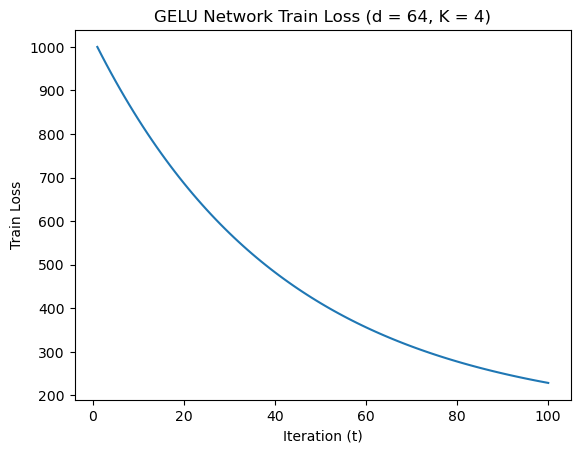

=== TRIAL 5 ===
Initializing weights using orthogonal method with scale 0.01


  0%|          | 0/100 [00:00<?, ?it/s]2026-10-15 13:48:48,469 - INFO - Finish Epoch 1
2026-10-15 13:48:48,470 - INFO - Train loss: 1000.714111328125, train accuracy: 26.7
2026-10-15 13:48:48,477 - INFO - Val loss: 980.3308715820312, val accuracy: 98.4
2026-10-15 13:48:48,484 - INFO - Finish Epoch 2
2026-10-15 13:48:48,485 - INFO - Train loss: 980.3308715820312, train accuracy: 98.4
2026-10-15 13:48:48,492 - INFO - Val loss: 949.7646484375, val accuracy: 98.8
2026-10-15 13:48:48,499 - INFO - Finish Epoch 3
2026-10-15 13:48:48,500 - INFO - Train loss: 949.7646484375, train accuracy: 98.8
2026-10-15 13:48:48,507 - INFO - Val loss: 917.7628784179688, val accuracy: 99.2
2026-10-15 13:48:48,514 - INFO - Finish Epoch 4
2026-10-15 13:48:48,515 - INFO - Train loss: 917.7628784179688, train accuracy: 99.2
2026-10-15 13:48:48,521 - INFO - Val loss: 887.0599365234375, val accuracy: 99.2
2026-10-15 13:48:48,528 - INFO - Finish Epoch 5
2026-10-15 13:48:48,530 - INFO - Train loss: 887.0599365234375,

2026-10-15 13:48:49,022 - INFO - Finish Epoch 38
2026-10-15 13:48:49,024 - INFO - Train loss: 342.657470703125, train accuracy: 99.7
2026-10-15 13:48:49,030 - INFO - Val loss: 334.64654541015625, val accuracy: 99.7
2026-10-15 13:48:49,037 - INFO - Finish Epoch 39
2026-10-15 13:48:49,038 - INFO - Train loss: 334.64654541015625, train accuracy: 99.7
2026-10-15 13:48:49,045 - INFO - Val loss: 326.9207763671875, val accuracy: 99.7
2026-10-15 13:48:49,052 - INFO - Finish Epoch 40
2026-10-15 13:48:49,053 - INFO - Train loss: 326.9207763671875, train accuracy: 99.7
2026-10-15 13:48:49,060 - INFO - Val loss: 319.4706726074219, val accuracy: 99.7
2026-10-15 13:48:49,067 - INFO - Finish Epoch 41
2026-10-15 13:48:49,068 - INFO - Train loss: 319.4706726074219, train accuracy: 99.7
2026-10-15 13:48:49,074 - INFO - Val loss: 312.2841491699219, val accuracy: 99.7
2026-10-15 13:48:49,082 - INFO - Finish Epoch 42
2026-10-15 13:48:49,083 - INFO - Train loss: 312.2841491699219, train accuracy: 99.7
2026-

2026-10-15 13:48:49,722 - INFO - Finish Epoch 75
2026-10-15 13:48:49,723 - INFO - Train loss: 173.1641387939453, train accuracy: 99.7
2026-10-15 13:48:49,730 - INFO - Val loss: 170.8664093017578, val accuracy: 99.7
2026-10-15 13:48:49,737 - INFO - Finish Epoch 76
2026-10-15 13:48:49,738 - INFO - Train loss: 170.8664093017578, train accuracy: 99.7
2026-10-15 13:48:49,745 - INFO - Val loss: 168.63848876953125, val accuracy: 99.8
2026-10-15 13:48:49,752 - INFO - Finish Epoch 77
2026-10-15 13:48:49,753 - INFO - Train loss: 168.63848876953125, train accuracy: 99.8
2026-10-15 13:48:49,760 - INFO - Val loss: 166.47802734375, val accuracy: 99.8
 77%|███████▋  | 77/100 [00:01<00:00, 58.23it/s]2026-10-15 13:48:49,768 - INFO - Finish Epoch 78
2026-10-15 13:48:49,769 - INFO - Train loss: 166.47802734375, train accuracy: 99.8
2026-10-15 13:48:49,776 - INFO - Val loss: 164.3833465576172, val accuracy: 99.8
2026-10-15 13:48:49,783 - INFO - Finish Epoch 79
2026-10-15 13:48:49,784 - INFO - Train loss: 

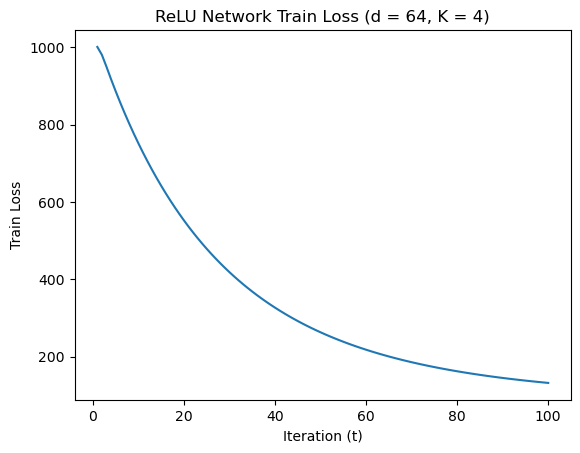

=== TRIAL 6 ===
Initializing weights using orthogonal method with scale 0.01


  0%|          | 0/100 [00:00<?, ?it/s]2026-10-15 13:48:50,260 - INFO - Finish Epoch 1
2026-10-15 13:48:50,262 - INFO - Train loss: 999.7785034179688, train accuracy: 27.1
2026-10-15 13:48:50,268 - INFO - Val loss: 978.3467407226562, val accuracy: 99.9
2026-10-15 13:48:50,275 - INFO - Finish Epoch 2
2026-10-15 13:48:50,277 - INFO - Train loss: 978.3467407226562, train accuracy: 99.9
2026-10-15 13:48:50,283 - INFO - Val loss: 957.47705078125, val accuracy: 100.0
2026-10-15 13:48:50,290 - INFO - Finish Epoch 3
2026-10-15 13:48:50,292 - INFO - Train loss: 957.47705078125, train accuracy: 100.0
2026-10-15 13:48:50,298 - INFO - Val loss: 937.136474609375, val accuracy: 100.0
2026-10-15 13:48:50,305 - INFO - Finish Epoch 4
2026-10-15 13:48:50,306 - INFO - Train loss: 937.136474609375, train accuracy: 100.0
2026-10-15 13:48:50,313 - INFO - Val loss: 917.295166015625, val accuracy: 100.0
2026-10-15 13:48:50,320 - INFO - Finish Epoch 5
2026-10-15 13:48:50,321 - INFO - Train loss: 917.2951660156

2026-10-15 13:48:50,810 - INFO - Finish Epoch 38
2026-10-15 13:48:50,811 - INFO - Train loss: 444.7795104980469, train accuracy: 100.0
2026-10-15 13:48:50,817 - INFO - Val loss: 434.6629943847656, val accuracy: 100.0
2026-10-15 13:48:50,825 - INFO - Finish Epoch 39
2026-10-15 13:48:50,826 - INFO - Train loss: 434.6629943847656, train accuracy: 100.0
2026-10-15 13:48:50,832 - INFO - Val loss: 424.7640075683594, val accuracy: 100.0
2026-10-15 13:48:50,839 - INFO - Finish Epoch 40
2026-10-15 13:48:50,840 - INFO - Train loss: 424.7640075683594, train accuracy: 100.0
2026-10-15 13:48:50,847 - INFO - Val loss: 415.0814208984375, val accuracy: 100.0
2026-10-15 13:48:50,854 - INFO - Finish Epoch 41
2026-10-15 13:48:50,855 - INFO - Train loss: 415.0814208984375, train accuracy: 100.0
2026-10-15 13:48:50,861 - INFO - Val loss: 405.6142883300781, val accuracy: 100.0
2026-10-15 13:48:50,868 - INFO - Finish Epoch 42
2026-10-15 13:48:50,870 - INFO - Train loss: 405.6142883300781, train accuracy: 100

2026-10-15 13:48:51,350 - INFO - Val loss: 202.65045166015625, val accuracy: 100.0
2026-10-15 13:48:51,357 - INFO - Finish Epoch 75
2026-10-15 13:48:51,358 - INFO - Train loss: 202.65045166015625, train accuracy: 100.0
2026-10-15 13:48:51,365 - INFO - Val loss: 199.31533813476562, val accuracy: 100.0
2026-10-15 13:48:51,372 - INFO - Finish Epoch 76
2026-10-15 13:48:51,373 - INFO - Train loss: 199.31533813476562, train accuracy: 100.0
2026-10-15 13:48:51,379 - INFO - Val loss: 196.10882568359375, val accuracy: 100.0
2026-10-15 13:48:51,387 - INFO - Finish Epoch 77
2026-10-15 13:48:51,388 - INFO - Train loss: 196.10882568359375, train accuracy: 100.0
2026-10-15 13:48:51,394 - INFO - Val loss: 193.0274658203125, val accuracy: 100.0
 77%|███████▋  | 77/100 [00:01<00:00, 67.50it/s]2026-10-15 13:48:51,402 - INFO - Finish Epoch 78
2026-10-15 13:48:51,404 - INFO - Train loss: 193.0274658203125, train accuracy: 100.0
2026-10-15 13:48:51,410 - INFO - Val loss: 190.0677490234375, val accuracy: 10

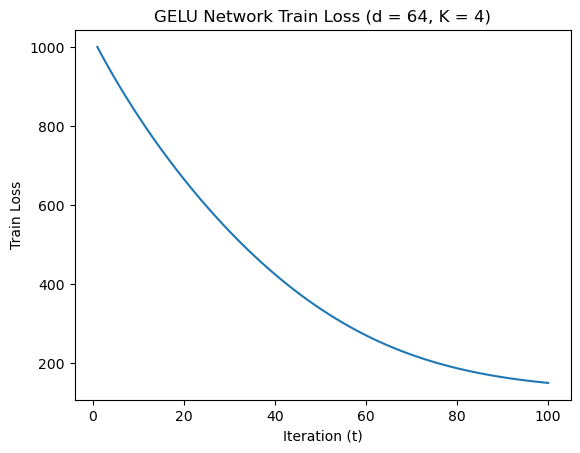

=== TRIAL 6 ===
Initializing weights using orthogonal method with scale 0.01


  0%|          | 0/100 [00:00<?, ?it/s]2026-10-15 13:48:51,886 - INFO - Finish Epoch 1
2026-10-15 13:48:51,887 - INFO - Train loss: 1000.1500244140625, train accuracy: 24.8
2026-10-15 13:48:51,895 - INFO - Val loss: 978.8182373046875, val accuracy: 99.9
2026-10-15 13:48:51,902 - INFO - Finish Epoch 2
2026-10-15 13:48:51,903 - INFO - Train loss: 978.8182373046875, train accuracy: 99.9
2026-10-15 13:48:51,910 - INFO - Val loss: 947.4308471679688, val accuracy: 99.9
2026-10-15 13:48:51,917 - INFO - Finish Epoch 3
2026-10-15 13:48:51,918 - INFO - Train loss: 947.4308471679688, train accuracy: 99.9
2026-10-15 13:48:51,925 - INFO - Val loss: 914.4337158203125, val accuracy: 100.0
2026-10-15 13:48:51,932 - INFO - Finish Epoch 4
2026-10-15 13:48:51,933 - INFO - Train loss: 914.4337158203125, train accuracy: 100.0
2026-10-15 13:48:51,940 - INFO - Val loss: 882.2935180664062, val accuracy: 100.0
2026-10-15 13:48:51,947 - INFO - Finish Epoch 5
2026-10-15 13:48:51,948 - INFO - Train loss: 882.2935

2026-10-15 13:48:52,474 - INFO - Val loss: 220.70703125, val accuracy: 100.0
2026-10-15 13:48:52,481 - INFO - Finish Epoch 38
2026-10-15 13:48:52,482 - INFO - Train loss: 220.70703125, train accuracy: 100.0
2026-10-15 13:48:52,489 - INFO - Val loss: 211.58865356445312, val accuracy: 100.0
2026-10-15 13:48:52,496 - INFO - Finish Epoch 39
2026-10-15 13:48:52,497 - INFO - Train loss: 211.58865356445312, train accuracy: 100.0
2026-10-15 13:48:52,504 - INFO - Val loss: 202.9971923828125, val accuracy: 100.0
2026-10-15 13:48:52,511 - INFO - Finish Epoch 40
2026-10-15 13:48:52,512 - INFO - Train loss: 202.9971923828125, train accuracy: 100.0
2026-10-15 13:48:52,518 - INFO - Val loss: 194.91119384765625, val accuracy: 100.0
2026-10-15 13:48:52,526 - INFO - Finish Epoch 41
2026-10-15 13:48:52,527 - INFO - Train loss: 194.91119384765625, train accuracy: 100.0
2026-10-15 13:48:52,533 - INFO - Val loss: 187.30752563476562, val accuracy: 100.0
2026-10-15 13:48:52,541 - INFO - Finish Epoch 42
2026-1

2026-10-15 13:48:53,166 - INFO - Train loss: 87.93363952636719, train accuracy: 100.0
2026-10-15 13:48:53,173 - INFO - Val loss: 86.99992370605469, val accuracy: 100.0
2026-10-15 13:48:53,180 - INFO - Finish Epoch 75
2026-10-15 13:48:53,181 - INFO - Train loss: 86.99992370605469, train accuracy: 100.0
2026-10-15 13:48:53,188 - INFO - Val loss: 86.11602783203125, val accuracy: 100.0
2026-10-15 13:48:53,195 - INFO - Finish Epoch 76
2026-10-15 13:48:53,196 - INFO - Train loss: 86.11602783203125, train accuracy: 100.0
2026-10-15 13:48:53,203 - INFO - Val loss: 85.27857971191406, val accuracy: 100.0
2026-10-15 13:48:53,210 - INFO - Finish Epoch 77
2026-10-15 13:48:53,211 - INFO - Train loss: 85.27857971191406, train accuracy: 100.0
2026-10-15 13:48:53,218 - INFO - Val loss: 84.48443603515625, val accuracy: 100.0
 77%|███████▋  | 77/100 [00:01<00:00, 46.75it/s]2026-10-15 13:48:53,226 - INFO - Finish Epoch 78
2026-10-15 13:48:53,227 - INFO - Train loss: 84.48443603515625, train accuracy: 100.

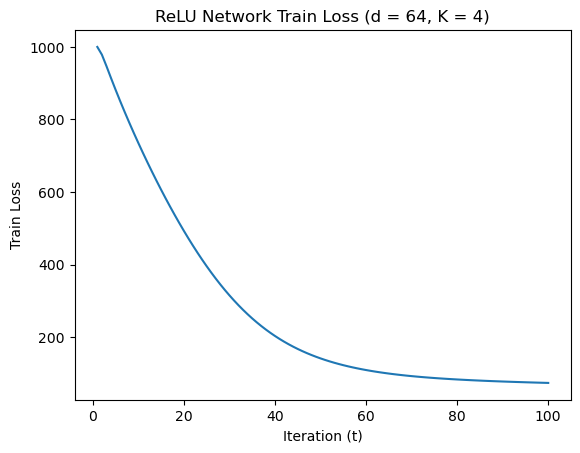

=== TRIAL 6 ===
Initializing weights using orthogonal method with scale 0.01


  0%|          | 0/100 [00:00<?, ?it/s]2026-10-15 13:48:53,717 - INFO - Finish Epoch 1
2026-10-15 13:48:53,718 - INFO - Train loss: 1000.051025390625, train accuracy: 22.6
2026-10-15 13:48:53,724 - INFO - Val loss: 978.9637451171875, val accuracy: 99.5
2026-10-15 13:48:53,732 - INFO - Finish Epoch 2
2026-10-15 13:48:53,734 - INFO - Train loss: 978.9637451171875, train accuracy: 99.5
2026-10-15 13:48:53,741 - INFO - Val loss: 958.421142578125, val accuracy: 99.5
2026-10-15 13:48:53,748 - INFO - Finish Epoch 3
2026-10-15 13:48:53,749 - INFO - Train loss: 958.421142578125, train accuracy: 99.5
2026-10-15 13:48:53,755 - INFO - Val loss: 938.4086303710938, val accuracy: 99.5
2026-10-15 13:48:53,763 - INFO - Finish Epoch 4
2026-10-15 13:48:53,764 - INFO - Train loss: 938.4086303710938, train accuracy: 99.5
2026-10-15 13:48:53,770 - INFO - Val loss: 918.9119262695312, val accuracy: 99.5
2026-10-15 13:48:53,777 - INFO - Finish Epoch 5
2026-10-15 13:48:53,779 - INFO - Train loss: 918.9119262695

2026-10-15 13:48:54,273 - INFO - Train loss: 491.597900390625, train accuracy: 99.5
2026-10-15 13:48:54,280 - INFO - Val loss: 483.45806884765625, val accuracy: 99.5
2026-10-15 13:48:54,287 - INFO - Finish Epoch 39
2026-10-15 13:48:54,288 - INFO - Train loss: 483.45806884765625, train accuracy: 99.5
2026-10-15 13:48:54,294 - INFO - Val loss: 475.52166748046875, val accuracy: 99.5
2026-10-15 13:48:54,302 - INFO - Finish Epoch 40
2026-10-15 13:48:54,303 - INFO - Train loss: 475.52166748046875, train accuracy: 99.5
2026-10-15 13:48:54,309 - INFO - Val loss: 467.78350830078125, val accuracy: 99.5
2026-10-15 13:48:54,316 - INFO - Finish Epoch 41
2026-10-15 13:48:54,318 - INFO - Train loss: 467.78350830078125, train accuracy: 99.5
2026-10-15 13:48:54,324 - INFO - Val loss: 460.23846435546875, val accuracy: 99.5
2026-10-15 13:48:54,331 - INFO - Finish Epoch 42
2026-10-15 13:48:54,333 - INFO - Train loss: 460.23846435546875, train accuracy: 99.5
2026-10-15 13:48:54,339 - INFO - Val loss: 452.8

2026-10-15 13:48:54,827 - INFO - Train loss: 292.9768981933594, train accuracy: 99.5
2026-10-15 13:48:54,834 - INFO - Val loss: 289.7462463378906, val accuracy: 99.5
2026-10-15 13:48:54,841 - INFO - Finish Epoch 76
2026-10-15 13:48:54,842 - INFO - Train loss: 289.7462463378906, train accuracy: 99.5
2026-10-15 13:48:54,849 - INFO - Val loss: 286.59417724609375, val accuracy: 99.5
2026-10-15 13:48:54,856 - INFO - Finish Epoch 77
2026-10-15 13:48:54,857 - INFO - Train loss: 286.59417724609375, train accuracy: 99.5
2026-10-15 13:48:54,863 - INFO - Val loss: 283.51873779296875, val accuracy: 99.5
 77%|███████▋  | 77/100 [00:01<00:00, 66.77it/s]2026-10-15 13:48:54,872 - INFO - Finish Epoch 78
2026-10-15 13:48:54,873 - INFO - Train loss: 283.51873779296875, train accuracy: 99.5
2026-10-15 13:48:54,879 - INFO - Val loss: 280.51800537109375, val accuracy: 99.5
2026-10-15 13:48:54,886 - INFO - Finish Epoch 79
2026-10-15 13:48:54,887 - INFO - Train loss: 280.51800537109375, train accuracy: 99.5
2

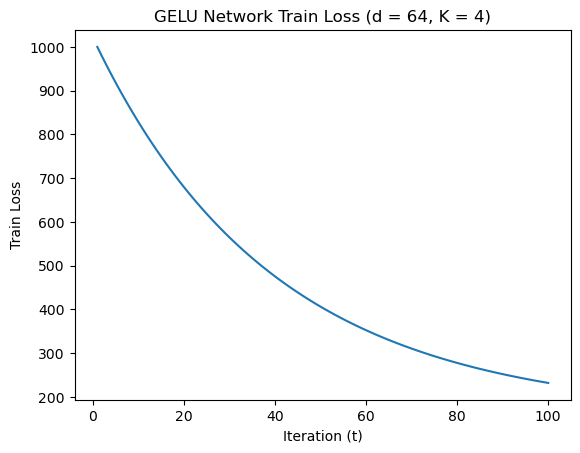

=== TRIAL 6 ===
Initializing weights using orthogonal method with scale 0.01


  0%|          | 0/100 [00:00<?, ?it/s]2026-10-15 13:48:55,378 - INFO - Finish Epoch 1
2026-10-15 13:48:55,379 - INFO - Train loss: 999.8479614257812, train accuracy: 23.7
2026-10-15 13:48:55,386 - INFO - Val loss: 976.1737060546875, val accuracy: 99.2
2026-10-15 13:48:55,394 - INFO - Finish Epoch 2
2026-10-15 13:48:55,395 - INFO - Train loss: 976.1737060546875, train accuracy: 99.2
2026-10-15 13:48:55,401 - INFO - Val loss: 940.08837890625, val accuracy: 99.7
2026-10-15 13:48:55,409 - INFO - Finish Epoch 3
2026-10-15 13:48:55,410 - INFO - Train loss: 940.08837890625, train accuracy: 99.7
2026-10-15 13:48:55,416 - INFO - Val loss: 902.427978515625, val accuracy: 99.6
2026-10-15 13:48:55,423 - INFO - Finish Epoch 4
2026-10-15 13:48:55,425 - INFO - Train loss: 902.427978515625, train accuracy: 99.6
2026-10-15 13:48:55,431 - INFO - Val loss: 866.1785278320312, val accuracy: 99.6
2026-10-15 13:48:55,438 - INFO - Finish Epoch 5
2026-10-15 13:48:55,439 - INFO - Train loss: 866.1785278320312,

2026-10-15 13:48:55,927 - INFO - Finish Epoch 38
2026-10-15 13:48:55,929 - INFO - Train loss: 284.12396240234375, train accuracy: 99.9
2026-10-15 13:48:55,935 - INFO - Val loss: 276.794189453125, val accuracy: 99.9
2026-10-15 13:48:55,942 - INFO - Finish Epoch 39
2026-10-15 13:48:55,943 - INFO - Train loss: 276.794189453125, train accuracy: 99.9
2026-10-15 13:48:55,950 - INFO - Val loss: 269.77142333984375, val accuracy: 99.9
2026-10-15 13:48:55,957 - INFO - Finish Epoch 40
2026-10-15 13:48:55,958 - INFO - Train loss: 269.77142333984375, train accuracy: 99.9
2026-10-15 13:48:55,964 - INFO - Val loss: 263.04339599609375, val accuracy: 99.9
2026-10-15 13:48:55,971 - INFO - Finish Epoch 41
2026-10-15 13:48:55,973 - INFO - Train loss: 263.04339599609375, train accuracy: 99.9
2026-10-15 13:48:55,979 - INFO - Val loss: 256.59375, val accuracy: 99.9
2026-10-15 13:48:55,986 - INFO - Finish Epoch 42
2026-10-15 13:48:55,987 - INFO - Train loss: 256.59375, train accuracy: 99.9
2026-10-15 13:48:55

2026-10-15 13:48:56,617 - INFO - Finish Epoch 75
2026-10-15 13:48:56,618 - INFO - Train loss: 140.5869903564453, train accuracy: 100.0
2026-10-15 13:48:56,625 - INFO - Val loss: 138.82632446289062, val accuracy: 100.0
2026-10-15 13:48:56,632 - INFO - Finish Epoch 76
2026-10-15 13:48:56,633 - INFO - Train loss: 138.82632446289062, train accuracy: 100.0
2026-10-15 13:48:56,640 - INFO - Val loss: 137.12416076660156, val accuracy: 100.0
2026-10-15 13:48:56,647 - INFO - Finish Epoch 77
2026-10-15 13:48:56,648 - INFO - Train loss: 137.12416076660156, train accuracy: 100.0
2026-10-15 13:48:56,654 - INFO - Val loss: 135.47865295410156, val accuracy: 100.0
 77%|███████▋  | 77/100 [00:01<00:00, 52.14it/s]2026-10-15 13:48:56,663 - INFO - Finish Epoch 78
2026-10-15 13:48:56,664 - INFO - Train loss: 135.47865295410156, train accuracy: 100.0
2026-10-15 13:48:56,670 - INFO - Val loss: 133.8875732421875, val accuracy: 100.0
2026-10-15 13:48:56,678 - INFO - Finish Epoch 79
2026-10-15 13:48:56,679 - INF

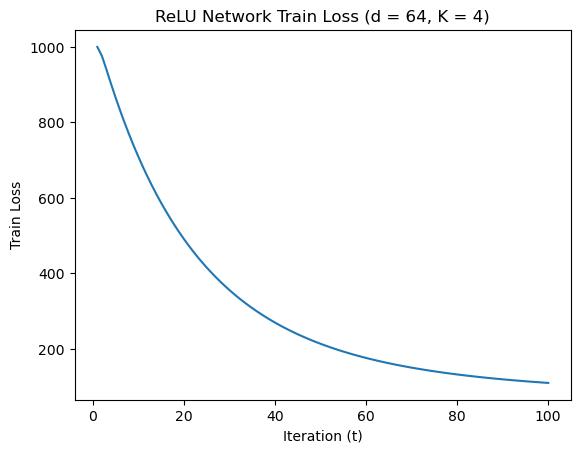

=== TRIAL 7 ===
Initializing weights using orthogonal method with scale 0.01


  0%|          | 0/100 [00:00<?, ?it/s]2026-10-15 13:48:57,156 - INFO - Finish Epoch 1
2026-10-15 13:48:57,157 - INFO - Train loss: 999.844970703125, train accuracy: 30.0
2026-10-15 13:48:57,164 - INFO - Val loss: 981.0535888671875, val accuracy: 99.1
2026-10-15 13:48:57,171 - INFO - Finish Epoch 2
2026-10-15 13:48:57,172 - INFO - Train loss: 981.0535888671875, train accuracy: 99.1
2026-10-15 13:48:57,179 - INFO - Val loss: 962.695556640625, val accuracy: 99.3
2026-10-15 13:48:57,186 - INFO - Finish Epoch 3
2026-10-15 13:48:57,187 - INFO - Train loss: 962.695556640625, train accuracy: 99.3
2026-10-15 13:48:57,193 - INFO - Val loss: 944.7459716796875, val accuracy: 99.3
2026-10-15 13:48:57,201 - INFO - Finish Epoch 4
2026-10-15 13:48:57,202 - INFO - Train loss: 944.7459716796875, train accuracy: 99.3
2026-10-15 13:48:57,208 - INFO - Val loss: 927.181884765625, val accuracy: 99.3
2026-10-15 13:48:57,216 - INFO - Finish Epoch 5
2026-10-15 13:48:57,217 - INFO - Train loss: 927.181884765625

2026-10-15 13:48:57,715 - INFO - Train loss: 489.52728271484375, train accuracy: 99.4
2026-10-15 13:48:57,722 - INFO - Val loss: 479.6395568847656, val accuracy: 99.4
2026-10-15 13:48:57,729 - INFO - Finish Epoch 39
2026-10-15 13:48:57,730 - INFO - Train loss: 479.6395568847656, train accuracy: 99.4
2026-10-15 13:48:57,737 - INFO - Val loss: 469.93682861328125, val accuracy: 99.4
2026-10-15 13:48:57,744 - INFO - Finish Epoch 40
2026-10-15 13:48:57,745 - INFO - Train loss: 469.93682861328125, train accuracy: 99.4
2026-10-15 13:48:57,752 - INFO - Val loss: 460.4192199707031, val accuracy: 99.4
2026-10-15 13:48:57,759 - INFO - Finish Epoch 41
2026-10-15 13:48:57,760 - INFO - Train loss: 460.4192199707031, train accuracy: 99.4
2026-10-15 13:48:57,766 - INFO - Val loss: 451.0868835449219, val accuracy: 99.4
2026-10-15 13:48:57,774 - INFO - Finish Epoch 42
2026-10-15 13:48:57,775 - INFO - Train loss: 451.0868835449219, train accuracy: 99.4
2026-10-15 13:48:57,781 - INFO - Val loss: 441.93994

2026-10-15 13:48:58,272 - INFO - Train loss: 242.95236206054688, train accuracy: 99.3
2026-10-15 13:48:58,279 - INFO - Val loss: 239.35218811035156, val accuracy: 99.3
2026-10-15 13:48:58,286 - INFO - Finish Epoch 76
2026-10-15 13:48:58,287 - INFO - Train loss: 239.35218811035156, train accuracy: 99.3
2026-10-15 13:48:58,294 - INFO - Val loss: 235.88223266601562, val accuracy: 99.3
2026-10-15 13:48:58,301 - INFO - Finish Epoch 77
2026-10-15 13:48:58,302 - INFO - Train loss: 235.88223266601562, train accuracy: 99.3
2026-10-15 13:48:58,309 - INFO - Val loss: 232.53941345214844, val accuracy: 99.3
 77%|███████▋  | 77/100 [00:01<00:00, 66.39it/s]2026-10-15 13:48:58,317 - INFO - Finish Epoch 78
2026-10-15 13:48:58,318 - INFO - Train loss: 232.53941345214844, train accuracy: 99.3
2026-10-15 13:48:58,325 - INFO - Val loss: 229.32058715820312, val accuracy: 99.4
2026-10-15 13:48:58,332 - INFO - Finish Epoch 79
2026-10-15 13:48:58,333 - INFO - Train loss: 229.32058715820312, train accuracy: 99.

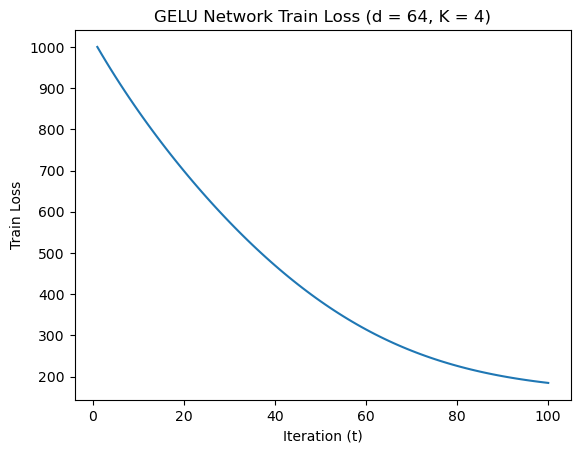

=== TRIAL 7 ===
Initializing weights using orthogonal method with scale 0.01


  0%|          | 0/100 [00:00<?, ?it/s]2026-10-15 13:48:58,827 - INFO - Finish Epoch 1
2026-10-15 13:48:58,828 - INFO - Train loss: 999.4307250976562, train accuracy: 21.9
2026-10-15 13:48:58,835 - INFO - Val loss: 977.83984375, val accuracy: 98.8
2026-10-15 13:48:58,842 - INFO - Finish Epoch 2
2026-10-15 13:48:58,843 - INFO - Train loss: 977.83984375, train accuracy: 98.8
2026-10-15 13:48:58,850 - INFO - Val loss: 944.271240234375, val accuracy: 99.5
2026-10-15 13:48:58,857 - INFO - Finish Epoch 3
2026-10-15 13:48:58,858 - INFO - Train loss: 944.271240234375, train accuracy: 99.5
2026-10-15 13:48:58,864 - INFO - Val loss: 908.156982421875, val accuracy: 99.8
2026-10-15 13:48:58,872 - INFO - Finish Epoch 4
2026-10-15 13:48:58,873 - INFO - Train loss: 908.156982421875, train accuracy: 99.8
2026-10-15 13:48:58,879 - INFO - Val loss: 873.1361083984375, val accuracy: 99.7
2026-10-15 13:48:58,886 - INFO - Finish Epoch 5
2026-10-15 13:48:58,887 - INFO - Train loss: 873.1361083984375, train a

2026-10-15 13:48:59,378 - INFO - Finish Epoch 38
2026-10-15 13:48:59,379 - INFO - Train loss: 237.40423583984375, train accuracy: 99.9
2026-10-15 13:48:59,385 - INFO - Val loss: 228.99964904785156, val accuracy: 99.9
2026-10-15 13:48:59,392 - INFO - Finish Epoch 39
2026-10-15 13:48:59,394 - INFO - Train loss: 228.99964904785156, train accuracy: 99.9
2026-10-15 13:48:59,400 - INFO - Val loss: 220.99473571777344, val accuracy: 99.9
2026-10-15 13:48:59,407 - INFO - Finish Epoch 40
2026-10-15 13:48:59,408 - INFO - Train loss: 220.99473571777344, train accuracy: 99.9
2026-10-15 13:48:59,415 - INFO - Val loss: 213.37197875976562, val accuracy: 99.9
2026-10-15 13:48:59,422 - INFO - Finish Epoch 41
2026-10-15 13:48:59,423 - INFO - Train loss: 213.37197875976562, train accuracy: 99.9
2026-10-15 13:48:59,429 - INFO - Val loss: 206.11395263671875, val accuracy: 99.9
2026-10-15 13:48:59,436 - INFO - Finish Epoch 42
2026-10-15 13:48:59,438 - INFO - Train loss: 206.11395263671875, train accuracy: 99

2026-10-15 13:48:59,926 - INFO - Finish Epoch 75
2026-10-15 13:48:59,928 - INFO - Train loss: 91.70243072509766, train accuracy: 100.0
2026-10-15 13:48:59,934 - INFO - Val loss: 90.39913177490234, val accuracy: 100.0
2026-10-15 13:48:59,941 - INFO - Finish Epoch 76
2026-10-15 13:48:59,942 - INFO - Train loss: 90.39913177490234, train accuracy: 100.0
2026-10-15 13:48:59,949 - INFO - Val loss: 89.15980529785156, val accuracy: 100.0
2026-10-15 13:48:59,956 - INFO - Finish Epoch 77
2026-10-15 13:48:59,957 - INFO - Train loss: 89.15980529785156, train accuracy: 100.0
2026-10-15 13:48:59,963 - INFO - Val loss: 87.98162841796875, val accuracy: 100.0
 77%|███████▋  | 77/100 [00:01<00:00, 67.36it/s]2026-10-15 13:48:59,972 - INFO - Finish Epoch 78
2026-10-15 13:48:59,973 - INFO - Train loss: 87.98162841796875, train accuracy: 100.0
2026-10-15 13:48:59,979 - INFO - Val loss: 86.8609848022461, val accuracy: 100.0
2026-10-15 13:48:59,986 - INFO - Finish Epoch 79
2026-10-15 13:48:59,988 - INFO - Tra

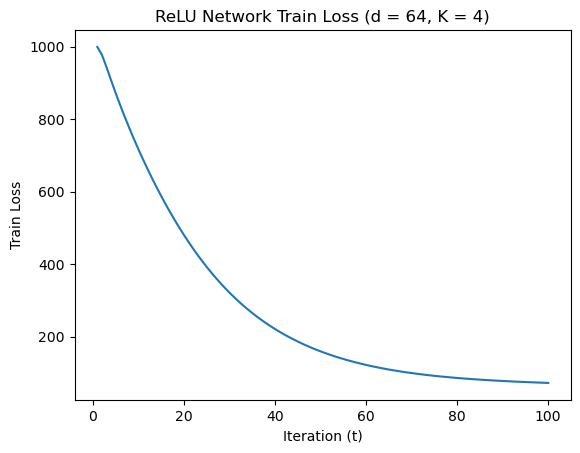

=== TRIAL 7 ===
Initializing weights using orthogonal method with scale 0.01


  0%|          | 0/100 [00:00<?, ?it/s]2026-10-15 13:49:00,458 - INFO - Finish Epoch 1
2026-10-15 13:49:00,459 - INFO - Train loss: 999.8775634765625, train accuracy: 27.4
2026-10-15 13:49:00,467 - INFO - Val loss: 979.188232421875, val accuracy: 99.9
2026-10-15 13:49:00,474 - INFO - Finish Epoch 2
2026-10-15 13:49:00,476 - INFO - Train loss: 979.188232421875, train accuracy: 99.9
2026-10-15 13:49:00,482 - INFO - Val loss: 959.0130615234375, val accuracy: 100.0
2026-10-15 13:49:00,489 - INFO - Finish Epoch 3
2026-10-15 13:49:00,490 - INFO - Train loss: 959.0130615234375, train accuracy: 100.0
2026-10-15 13:49:00,497 - INFO - Val loss: 939.3387451171875, val accuracy: 100.0
2026-10-15 13:49:00,504 - INFO - Finish Epoch 4
2026-10-15 13:49:00,505 - INFO - Train loss: 939.3387451171875, train accuracy: 100.0
2026-10-15 13:49:00,512 - INFO - Val loss: 920.1524047851562, val accuracy: 100.0
2026-10-15 13:49:00,519 - INFO - Finish Epoch 5
2026-10-15 13:49:00,520 - INFO - Train loss: 920.15240

2026-10-15 13:49:01,170 - INFO - Finish Epoch 38
2026-10-15 13:49:01,171 - INFO - Train loss: 493.6883544921875, train accuracy: 100.0
2026-10-15 13:49:01,177 - INFO - Val loss: 485.42095947265625, val accuracy: 100.0
2026-10-15 13:49:01,185 - INFO - Finish Epoch 39
2026-10-15 13:49:01,186 - INFO - Train loss: 485.42095947265625, train accuracy: 100.0
2026-10-15 13:49:01,192 - INFO - Val loss: 477.35321044921875, val accuracy: 100.0
2026-10-15 13:49:01,200 - INFO - Finish Epoch 40
2026-10-15 13:49:01,201 - INFO - Train loss: 477.35321044921875, train accuracy: 100.0
2026-10-15 13:49:01,207 - INFO - Val loss: 469.4800720214844, val accuracy: 100.0
2026-10-15 13:49:01,214 - INFO - Finish Epoch 41
2026-10-15 13:49:01,216 - INFO - Train loss: 469.4800720214844, train accuracy: 100.0
2026-10-15 13:49:01,222 - INFO - Val loss: 461.79681396484375, val accuracy: 100.0
2026-10-15 13:49:01,229 - INFO - Finish Epoch 42
2026-10-15 13:49:01,231 - INFO - Train loss: 461.79681396484375, train accurac

2026-10-15 13:49:01,723 - INFO - Val loss: 289.34088134765625, val accuracy: 100.0
2026-10-15 13:49:01,730 - INFO - Finish Epoch 75
2026-10-15 13:49:01,732 - INFO - Train loss: 289.34088134765625, train accuracy: 100.0
2026-10-15 13:49:01,738 - INFO - Val loss: 285.9570617675781, val accuracy: 100.0
2026-10-15 13:49:01,745 - INFO - Finish Epoch 76
2026-10-15 13:49:01,747 - INFO - Train loss: 285.9570617675781, train accuracy: 100.0
2026-10-15 13:49:01,753 - INFO - Val loss: 282.6529235839844, val accuracy: 100.0
2026-10-15 13:49:01,760 - INFO - Finish Epoch 77
2026-10-15 13:49:01,761 - INFO - Train loss: 282.6529235839844, train accuracy: 100.0
2026-10-15 13:49:01,768 - INFO - Val loss: 279.426513671875, val accuracy: 100.0
 77%|███████▋  | 77/100 [00:01<00:00, 64.38it/s]2026-10-15 13:49:01,776 - INFO - Finish Epoch 78
2026-10-15 13:49:01,778 - INFO - Train loss: 279.426513671875, train accuracy: 100.0
2026-10-15 13:49:01,784 - INFO - Val loss: 276.2760009765625, val accuracy: 100.0
20

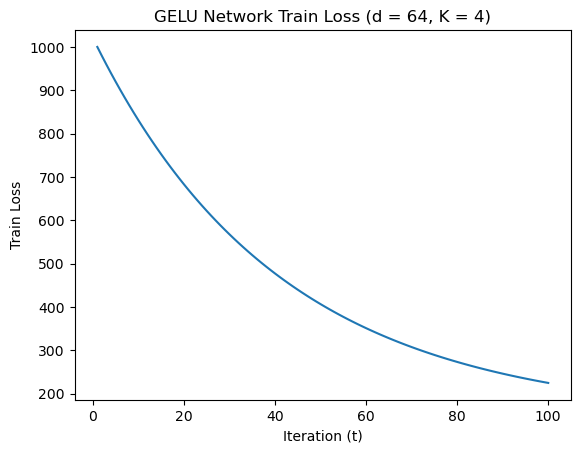

=== TRIAL 7 ===
Initializing weights using orthogonal method with scale 0.01


  0%|          | 0/100 [00:00<?, ?it/s]2026-10-15 13:49:02,287 - INFO - Finish Epoch 1
2026-10-15 13:49:02,288 - INFO - Train loss: 999.8597412109375, train accuracy: 23.4
2026-10-15 13:49:02,294 - INFO - Val loss: 978.6248779296875, val accuracy: 99.5
2026-10-15 13:49:02,302 - INFO - Finish Epoch 2
2026-10-15 13:49:02,303 - INFO - Train loss: 978.6248779296875, train accuracy: 99.5
2026-10-15 13:49:02,309 - INFO - Val loss: 944.9456787109375, val accuracy: 100.0
2026-10-15 13:49:02,316 - INFO - Finish Epoch 3
2026-10-15 13:49:02,318 - INFO - Train loss: 944.9456787109375, train accuracy: 100.0
2026-10-15 13:49:02,324 - INFO - Val loss: 909.18896484375, val accuracy: 100.0
2026-10-15 13:49:02,331 - INFO - Finish Epoch 4
2026-10-15 13:49:02,332 - INFO - Train loss: 909.18896484375, train accuracy: 100.0
2026-10-15 13:49:02,339 - INFO - Val loss: 874.53564453125, val accuracy: 100.0
2026-10-15 13:49:02,346 - INFO - Finish Epoch 5
2026-10-15 13:49:02,347 - INFO - Train loss: 874.535644531

2026-10-15 13:49:02,834 - INFO - Val loss: 293.824462890625, val accuracy: 100.0
2026-10-15 13:49:02,841 - INFO - Finish Epoch 38
2026-10-15 13:49:02,842 - INFO - Train loss: 293.824462890625, train accuracy: 100.0
2026-10-15 13:49:02,848 - INFO - Val loss: 286.2283630371094, val accuracy: 100.0
2026-10-15 13:49:02,855 - INFO - Finish Epoch 39
2026-10-15 13:49:02,857 - INFO - Train loss: 286.2283630371094, train accuracy: 100.0
2026-10-15 13:49:02,863 - INFO - Val loss: 278.951171875, val accuracy: 100.0
2026-10-15 13:49:02,870 - INFO - Finish Epoch 40
2026-10-15 13:49:02,871 - INFO - Train loss: 278.951171875, train accuracy: 100.0
2026-10-15 13:49:02,878 - INFO - Val loss: 271.97918701171875, val accuracy: 100.0
2026-10-15 13:49:02,885 - INFO - Finish Epoch 41
2026-10-15 13:49:02,886 - INFO - Train loss: 271.97918701171875, train accuracy: 100.0
2026-10-15 13:49:02,893 - INFO - Val loss: 265.2982177734375, val accuracy: 100.0
2026-10-15 13:49:02,900 - INFO - Finish Epoch 42
2026-10-1

2026-10-15 13:49:03,384 - INFO - Train loss: 149.23077392578125, train accuracy: 100.0
2026-10-15 13:49:03,390 - INFO - Val loss: 147.46620178222656, val accuracy: 100.0
2026-10-15 13:49:03,397 - INFO - Finish Epoch 75
2026-10-15 13:49:03,398 - INFO - Train loss: 147.46620178222656, train accuracy: 100.0
2026-10-15 13:49:03,405 - INFO - Val loss: 145.76629638671875, val accuracy: 100.0
2026-10-15 13:49:03,412 - INFO - Finish Epoch 76
2026-10-15 13:49:03,413 - INFO - Train loss: 145.76629638671875, train accuracy: 100.0
2026-10-15 13:49:03,420 - INFO - Val loss: 144.12881469726562, val accuracy: 100.0
2026-10-15 13:49:03,427 - INFO - Finish Epoch 77
2026-10-15 13:49:03,428 - INFO - Train loss: 144.12881469726562, train accuracy: 100.0
2026-10-15 13:49:03,435 - INFO - Val loss: 142.55068969726562, val accuracy: 100.0
 77%|███████▋  | 77/100 [00:01<00:00, 66.26it/s]2026-10-15 13:49:03,443 - INFO - Finish Epoch 78
2026-10-15 13:49:03,444 - INFO - Train loss: 142.55068969726562, train accur

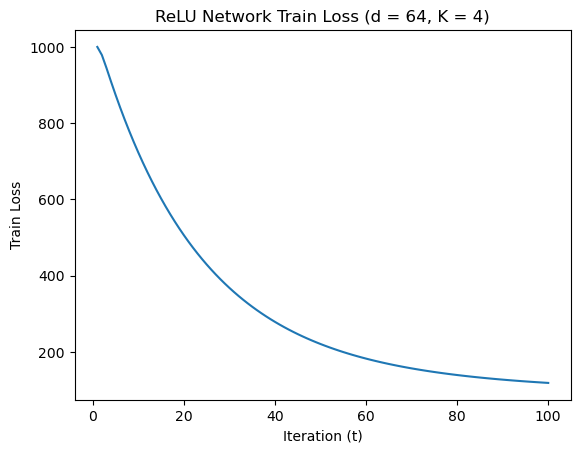

=== TRIAL 8 ===
Initializing weights using orthogonal method with scale 0.01


  0%|          | 0/100 [00:00<?, ?it/s]2026-10-15 13:49:03,933 - INFO - Finish Epoch 1
2026-10-15 13:49:03,934 - INFO - Train loss: 1000.2513427734375, train accuracy: 18.4
2026-10-15 13:49:03,941 - INFO - Val loss: 979.9771118164062, val accuracy: 99.5
2026-10-15 13:49:03,949 - INFO - Finish Epoch 2
2026-10-15 13:49:03,950 - INFO - Train loss: 979.9771118164062, train accuracy: 99.5
2026-10-15 13:49:03,956 - INFO - Val loss: 960.19970703125, val accuracy: 99.7
2026-10-15 13:49:03,964 - INFO - Finish Epoch 3
2026-10-15 13:49:03,965 - INFO - Train loss: 960.19970703125, train accuracy: 99.7
2026-10-15 13:49:03,971 - INFO - Val loss: 940.8907470703125, val accuracy: 99.7
2026-10-15 13:49:03,979 - INFO - Finish Epoch 4
2026-10-15 13:49:03,980 - INFO - Train loss: 940.8907470703125, train accuracy: 99.7
2026-10-15 13:49:03,986 - INFO - Val loss: 922.0242919921875, val accuracy: 99.8
2026-10-15 13:49:03,993 - INFO - Finish Epoch 5
2026-10-15 13:49:03,995 - INFO - Train loss: 922.02429199218

2026-10-15 13:49:04,494 - INFO - Train loss: 463.76043701171875, train accuracy: 99.8
2026-10-15 13:49:04,500 - INFO - Val loss: 453.7764892578125, val accuracy: 99.8
2026-10-15 13:49:04,507 - INFO - Finish Epoch 39
2026-10-15 13:49:04,509 - INFO - Train loss: 453.7764892578125, train accuracy: 99.8
2026-10-15 13:49:04,515 - INFO - Val loss: 444.0016174316406, val accuracy: 99.8
2026-10-15 13:49:04,522 - INFO - Finish Epoch 40
2026-10-15 13:49:04,524 - INFO - Train loss: 444.0016174316406, train accuracy: 99.8
2026-10-15 13:49:04,530 - INFO - Val loss: 434.435302734375, val accuracy: 99.8
2026-10-15 13:49:04,537 - INFO - Finish Epoch 41
2026-10-15 13:49:04,539 - INFO - Train loss: 434.435302734375, train accuracy: 99.8
2026-10-15 13:49:04,545 - INFO - Val loss: 425.07696533203125, val accuracy: 99.8
2026-10-15 13:49:04,552 - INFO - Finish Epoch 42
2026-10-15 13:49:04,554 - INFO - Train loss: 425.07696533203125, train accuracy: 99.8
2026-10-15 13:49:04,560 - INFO - Val loss: 415.9259643

2026-10-15 13:49:05,059 - INFO - Val loss: 220.2261505126953, val accuracy: 99.8
2026-10-15 13:49:05,211 - INFO - Finish Epoch 76
2026-10-15 13:49:05,213 - INFO - Train loss: 220.2261505126953, train accuracy: 99.8
2026-10-15 13:49:05,220 - INFO - Val loss: 217.03054809570312, val accuracy: 99.8
2026-10-15 13:49:05,227 - INFO - Finish Epoch 77
2026-10-15 13:49:05,229 - INFO - Train loss: 217.03054809570312, train accuracy: 99.8
2026-10-15 13:49:05,235 - INFO - Val loss: 213.959228515625, val accuracy: 99.8
 77%|███████▋  | 77/100 [00:01<00:00, 46.51it/s]2026-10-15 13:49:05,243 - INFO - Finish Epoch 78
2026-10-15 13:49:05,245 - INFO - Train loss: 213.959228515625, train accuracy: 99.8
2026-10-15 13:49:05,251 - INFO - Val loss: 211.00875854492188, val accuracy: 99.8
2026-10-15 13:49:05,258 - INFO - Finish Epoch 79
2026-10-15 13:49:05,260 - INFO - Train loss: 211.00875854492188, train accuracy: 99.8
2026-10-15 13:49:05,266 - INFO - Val loss: 208.17568969726562, val accuracy: 99.8
2026-10-

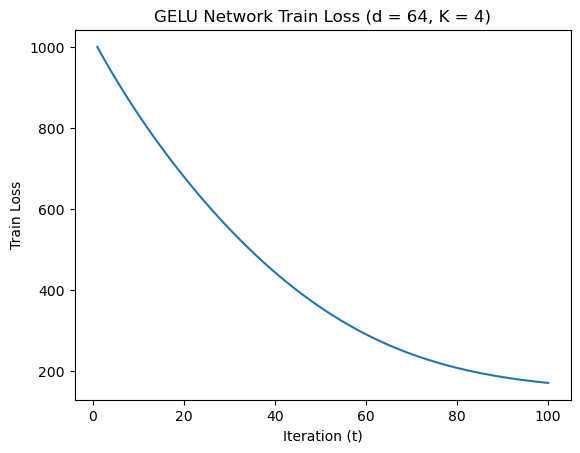

=== TRIAL 8 ===
Initializing weights using orthogonal method with scale 0.01


  0%|          | 0/100 [00:00<?, ?it/s]2026-10-15 13:49:05,734 - INFO - Finish Epoch 1
2026-10-15 13:49:05,735 - INFO - Train loss: 1000.3778686523438, train accuracy: 31.6
2026-10-15 13:49:05,742 - INFO - Val loss: 980.4072265625, val accuracy: 99.0
2026-10-15 13:49:05,749 - INFO - Finish Epoch 2
2026-10-15 13:49:05,751 - INFO - Train loss: 980.4072265625, train accuracy: 99.0
2026-10-15 13:49:05,757 - INFO - Val loss: 949.7693481445312, val accuracy: 99.7
2026-10-15 13:49:05,764 - INFO - Finish Epoch 3
2026-10-15 13:49:05,765 - INFO - Train loss: 949.7693481445312, train accuracy: 99.7
2026-10-15 13:49:05,772 - INFO - Val loss: 918.0550537109375, val accuracy: 99.7
2026-10-15 13:49:05,779 - INFO - Finish Epoch 4
2026-10-15 13:49:05,780 - INFO - Train loss: 918.0550537109375, train accuracy: 99.7
2026-10-15 13:49:05,787 - INFO - Val loss: 887.3388671875, val accuracy: 99.7
2026-10-15 13:49:05,794 - INFO - Finish Epoch 5
2026-10-15 13:49:05,795 - INFO - Train loss: 887.3388671875, trai

2026-10-15 13:49:06,294 - INFO - Train loss: 220.75917053222656, train accuracy: 99.8
2026-10-15 13:49:06,301 - INFO - Val loss: 210.89065551757812, val accuracy: 99.8
2026-10-15 13:49:06,308 - INFO - Finish Epoch 39
2026-10-15 13:49:06,309 - INFO - Train loss: 210.89065551757812, train accuracy: 99.8
2026-10-15 13:49:06,316 - INFO - Val loss: 201.61639404296875, val accuracy: 99.8
2026-10-15 13:49:06,323 - INFO - Finish Epoch 40
2026-10-15 13:49:06,324 - INFO - Train loss: 201.61639404296875, train accuracy: 99.8
2026-10-15 13:49:06,331 - INFO - Val loss: 192.91677856445312, val accuracy: 99.8
2026-10-15 13:49:06,338 - INFO - Finish Epoch 41
2026-10-15 13:49:06,339 - INFO - Train loss: 192.91677856445312, train accuracy: 99.8
2026-10-15 13:49:06,346 - INFO - Val loss: 184.76992797851562, val accuracy: 99.8
2026-10-15 13:49:06,353 - INFO - Finish Epoch 42
2026-10-15 13:49:06,354 - INFO - Train loss: 184.76992797851562, train accuracy: 99.8
2026-10-15 13:49:06,361 - INFO - Val loss: 177

2026-10-15 13:49:06,853 - INFO - Train loss: 86.20846557617188, train accuracy: 99.9
2026-10-15 13:49:06,860 - INFO - Val loss: 85.45874786376953, val accuracy: 99.9
2026-10-15 13:49:06,867 - INFO - Finish Epoch 76
2026-10-15 13:49:06,868 - INFO - Train loss: 85.45874786376953, train accuracy: 99.9
2026-10-15 13:49:06,875 - INFO - Val loss: 84.74847412109375, val accuracy: 99.9
2026-10-15 13:49:06,882 - INFO - Finish Epoch 77
2026-10-15 13:49:06,883 - INFO - Train loss: 84.74847412109375, train accuracy: 99.9
2026-10-15 13:49:06,890 - INFO - Val loss: 84.0745620727539, val accuracy: 99.9
 77%|███████▋  | 77/100 [00:01<00:00, 66.14it/s]2026-10-15 13:49:06,898 - INFO - Finish Epoch 78
2026-10-15 13:49:06,899 - INFO - Train loss: 84.0745620727539, train accuracy: 99.9
2026-10-15 13:49:06,906 - INFO - Val loss: 83.43392944335938, val accuracy: 99.9
2026-10-15 13:49:06,913 - INFO - Finish Epoch 79
2026-10-15 13:49:06,914 - INFO - Train loss: 83.43392944335938, train accuracy: 99.9
2026-10-1

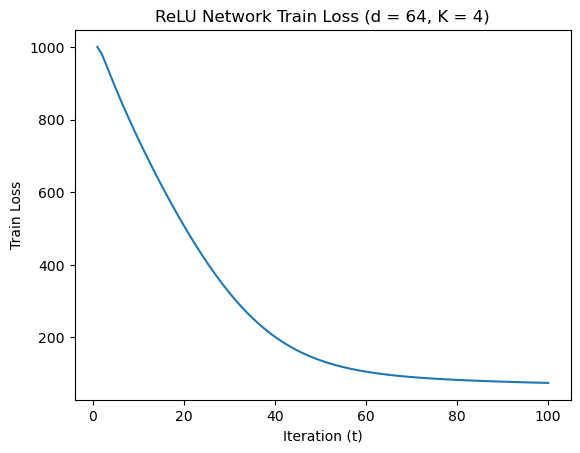

=== TRIAL 8 ===
Initializing weights using orthogonal method with scale 0.01


  0%|          | 0/100 [00:00<?, ?it/s]2026-10-15 13:49:07,390 - INFO - Finish Epoch 1
2026-10-15 13:49:07,391 - INFO - Train loss: 1000.4424438476562, train accuracy: 17.2
2026-10-15 13:49:07,398 - INFO - Val loss: 978.4573974609375, val accuracy: 99.7
2026-10-15 13:49:07,405 - INFO - Finish Epoch 2
2026-10-15 13:49:07,406 - INFO - Train loss: 978.4573974609375, train accuracy: 99.7
2026-10-15 13:49:07,413 - INFO - Val loss: 957.0404052734375, val accuracy: 99.8
2026-10-15 13:49:07,420 - INFO - Finish Epoch 3
2026-10-15 13:49:07,421 - INFO - Train loss: 957.0404052734375, train accuracy: 99.8
2026-10-15 13:49:07,428 - INFO - Val loss: 936.1766357421875, val accuracy: 99.8
2026-10-15 13:49:07,435 - INFO - Finish Epoch 4
2026-10-15 13:49:07,436 - INFO - Train loss: 936.1766357421875, train accuracy: 99.8
2026-10-15 13:49:07,443 - INFO - Val loss: 915.8515014648438, val accuracy: 99.8
2026-10-15 13:49:07,450 - INFO - Finish Epoch 5
2026-10-15 13:49:07,451 - INFO - Train loss: 915.8515014

2026-10-15 13:49:07,948 - INFO - Train loss: 471.82916259765625, train accuracy: 99.8
2026-10-15 13:49:07,955 - INFO - Val loss: 463.4373779296875, val accuracy: 99.8
2026-10-15 13:49:07,962 - INFO - Finish Epoch 39
2026-10-15 13:49:07,963 - INFO - Train loss: 463.4373779296875, train accuracy: 99.8
2026-10-15 13:49:07,970 - INFO - Val loss: 455.26019287109375, val accuracy: 99.8
2026-10-15 13:49:07,977 - INFO - Finish Epoch 40
2026-10-15 13:49:07,978 - INFO - Train loss: 455.26019287109375, train accuracy: 99.8
2026-10-15 13:49:07,985 - INFO - Val loss: 447.29217529296875, val accuracy: 99.8
2026-10-15 13:49:07,992 - INFO - Finish Epoch 41
2026-10-15 13:49:07,993 - INFO - Train loss: 447.29217529296875, train accuracy: 99.8
2026-10-15 13:49:07,999 - INFO - Val loss: 439.52783203125, val accuracy: 99.8
2026-10-15 13:49:08,007 - INFO - Finish Epoch 42
2026-10-15 13:49:08,008 - INFO - Train loss: 439.52783203125, train accuracy: 99.8
2026-10-15 13:49:08,014 - INFO - Val loss: 431.9620056

2026-10-15 13:49:08,506 - INFO - Train loss: 269.3793029785156, train accuracy: 99.8
2026-10-15 13:49:08,513 - INFO - Val loss: 266.1523742675781, val accuracy: 99.8
2026-10-15 13:49:08,520 - INFO - Finish Epoch 76
2026-10-15 13:49:08,521 - INFO - Train loss: 266.1523742675781, train accuracy: 99.8
2026-10-15 13:49:08,528 - INFO - Val loss: 263.00750732421875, val accuracy: 99.8
2026-10-15 13:49:08,535 - INFO - Finish Epoch 77
2026-10-15 13:49:08,536 - INFO - Train loss: 263.00750732421875, train accuracy: 99.8
2026-10-15 13:49:08,543 - INFO - Val loss: 259.94256591796875, val accuracy: 99.8
 77%|███████▋  | 77/100 [00:01<00:00, 66.33it/s]2026-10-15 13:49:08,551 - INFO - Finish Epoch 78
2026-10-15 13:49:08,552 - INFO - Train loss: 259.94256591796875, train accuracy: 99.8
2026-10-15 13:49:08,559 - INFO - Val loss: 256.9555358886719, val accuracy: 99.8
2026-10-15 13:49:08,566 - INFO - Finish Epoch 79
2026-10-15 13:49:08,567 - INFO - Train loss: 256.9555358886719, train accuracy: 99.8
202

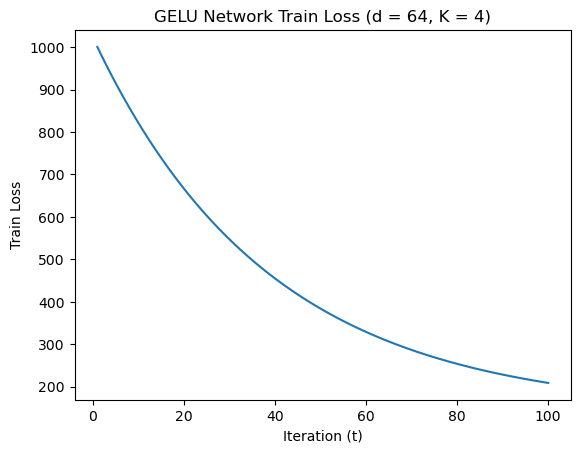

=== TRIAL 8 ===
Initializing weights using orthogonal method with scale 0.01


  0%|          | 0/100 [00:00<?, ?it/s]2026-10-15 13:49:09,060 - INFO - Finish Epoch 1
2026-10-15 13:49:09,062 - INFO - Train loss: 999.7078857421875, train accuracy: 22.4
2026-10-15 13:49:09,068 - INFO - Val loss: 976.798095703125, val accuracy: 99.1
2026-10-15 13:49:09,076 - INFO - Finish Epoch 2
2026-10-15 13:49:09,077 - INFO - Train loss: 976.798095703125, train accuracy: 99.1
2026-10-15 13:49:09,083 - INFO - Val loss: 940.675537109375, val accuracy: 99.8
2026-10-15 13:49:09,091 - INFO - Finish Epoch 3
2026-10-15 13:49:09,092 - INFO - Train loss: 940.675537109375, train accuracy: 99.8
2026-10-15 13:49:09,098 - INFO - Val loss: 902.83447265625, val accuracy: 99.8
2026-10-15 13:49:09,105 - INFO - Finish Epoch 4
2026-10-15 13:49:09,107 - INFO - Train loss: 902.83447265625, train accuracy: 99.8
2026-10-15 13:49:09,113 - INFO - Val loss: 866.6500244140625, val accuracy: 99.8
2026-10-15 13:49:09,120 - INFO - Finish Epoch 5
2026-10-15 13:49:09,121 - INFO - Train loss: 866.6500244140625, t

2026-10-15 13:49:09,763 - INFO - Finish Epoch 38
2026-10-15 13:49:09,764 - INFO - Train loss: 276.51251220703125, train accuracy: 99.7
2026-10-15 13:49:09,770 - INFO - Val loss: 269.062255859375, val accuracy: 99.7
2026-10-15 13:49:09,778 - INFO - Finish Epoch 39
2026-10-15 13:49:09,779 - INFO - Train loss: 269.062255859375, train accuracy: 99.7
2026-10-15 13:49:09,785 - INFO - Val loss: 261.9346923828125, val accuracy: 99.7
2026-10-15 13:49:09,793 - INFO - Finish Epoch 40
2026-10-15 13:49:09,794 - INFO - Train loss: 261.9346923828125, train accuracy: 99.7
2026-10-15 13:49:09,800 - INFO - Val loss: 255.11532592773438, val accuracy: 99.7
2026-10-15 13:49:09,808 - INFO - Finish Epoch 41
2026-10-15 13:49:09,809 - INFO - Train loss: 255.11532592773438, train accuracy: 99.7
2026-10-15 13:49:09,815 - INFO - Val loss: 248.59042358398438, val accuracy: 99.7
2026-10-15 13:49:09,823 - INFO - Finish Epoch 42
2026-10-15 13:49:09,824 - INFO - Train loss: 248.59042358398438, train accuracy: 99.7
202

2026-10-15 13:49:10,323 - INFO - Finish Epoch 75
2026-10-15 13:49:10,324 - INFO - Train loss: 135.08364868164062, train accuracy: 99.8
2026-10-15 13:49:10,331 - INFO - Val loss: 133.46560668945312, val accuracy: 99.8
2026-10-15 13:49:10,338 - INFO - Finish Epoch 76
2026-10-15 13:49:10,339 - INFO - Train loss: 133.46560668945312, train accuracy: 99.8
2026-10-15 13:49:10,346 - INFO - Val loss: 131.90748596191406, val accuracy: 99.9
2026-10-15 13:49:10,353 - INFO - Finish Epoch 77
2026-10-15 13:49:10,354 - INFO - Train loss: 131.90748596191406, train accuracy: 99.9
2026-10-15 13:49:10,361 - INFO - Val loss: 130.406005859375, val accuracy: 99.9
 77%|███████▋  | 77/100 [00:01<00:00, 63.87it/s]2026-10-15 13:49:10,369 - INFO - Finish Epoch 78
2026-10-15 13:49:10,370 - INFO - Train loss: 130.406005859375, train accuracy: 99.9
2026-10-15 13:49:10,377 - INFO - Val loss: 128.95909118652344, val accuracy: 99.9
2026-10-15 13:49:10,384 - INFO - Finish Epoch 79
2026-10-15 13:49:10,385 - INFO - Train 

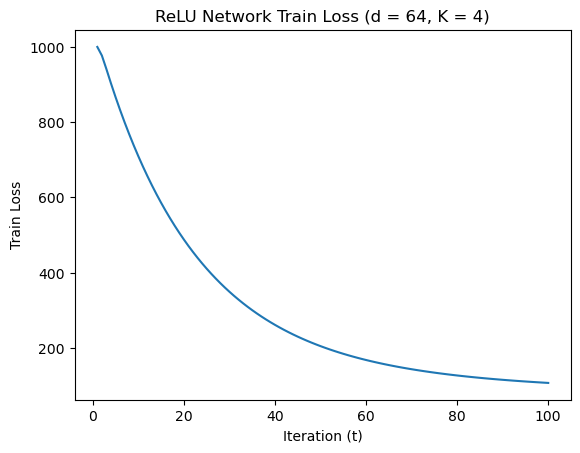

=== TRIAL 9 ===
Initializing weights using orthogonal method with scale 0.01


  0%|          | 0/100 [00:00<?, ?it/s]2026-10-15 13:49:10,861 - INFO - Finish Epoch 1
2026-10-15 13:49:10,862 - INFO - Train loss: 999.8404541015625, train accuracy: 26.1
2026-10-15 13:49:10,868 - INFO - Val loss: 977.739990234375, val accuracy: 100.0
2026-10-15 13:49:10,876 - INFO - Finish Epoch 2
2026-10-15 13:49:10,877 - INFO - Train loss: 977.739990234375, train accuracy: 100.0
2026-10-15 13:49:10,884 - INFO - Val loss: 956.2214965820312, val accuracy: 100.0
2026-10-15 13:49:10,891 - INFO - Finish Epoch 3
2026-10-15 13:49:10,892 - INFO - Train loss: 956.2214965820312, train accuracy: 100.0
2026-10-15 13:49:10,899 - INFO - Val loss: 935.251708984375, val accuracy: 100.0
2026-10-15 13:49:10,906 - INFO - Finish Epoch 4
2026-10-15 13:49:10,907 - INFO - Train loss: 935.251708984375, train accuracy: 100.0
2026-10-15 13:49:10,914 - INFO - Val loss: 914.8003540039062, val accuracy: 100.0
2026-10-15 13:49:10,921 - INFO - Finish Epoch 5
2026-10-15 13:49:10,922 - INFO - Train loss: 914.80035

2026-10-15 13:49:11,419 - INFO - Finish Epoch 38
2026-10-15 13:49:11,420 - INFO - Train loss: 432.999267578125, train accuracy: 100.0
2026-10-15 13:49:11,427 - INFO - Val loss: 422.937255859375, val accuracy: 100.0
2026-10-15 13:49:11,434 - INFO - Finish Epoch 39
2026-10-15 13:49:11,435 - INFO - Train loss: 422.937255859375, train accuracy: 100.0
2026-10-15 13:49:11,442 - INFO - Val loss: 413.1109619140625, val accuracy: 100.0
2026-10-15 13:49:11,449 - INFO - Finish Epoch 40
2026-10-15 13:49:11,450 - INFO - Train loss: 413.1109619140625, train accuracy: 100.0
2026-10-15 13:49:11,457 - INFO - Val loss: 403.5188903808594, val accuracy: 100.0
2026-10-15 13:49:11,464 - INFO - Finish Epoch 41
2026-10-15 13:49:11,465 - INFO - Train loss: 403.5188903808594, train accuracy: 100.0
2026-10-15 13:49:11,471 - INFO - Val loss: 394.15948486328125, val accuracy: 100.0
2026-10-15 13:49:11,479 - INFO - Finish Epoch 42
2026-10-15 13:49:11,480 - INFO - Train loss: 394.15948486328125, train accuracy: 100.

2026-10-15 13:49:11,977 - INFO - Finish Epoch 75
2026-10-15 13:49:11,978 - INFO - Train loss: 200.21397399902344, train accuracy: 100.0
2026-10-15 13:49:11,985 - INFO - Val loss: 197.18582153320312, val accuracy: 100.0
2026-10-15 13:49:11,992 - INFO - Finish Epoch 76
2026-10-15 13:49:11,993 - INFO - Train loss: 197.18582153320312, train accuracy: 100.0
2026-10-15 13:49:12,000 - INFO - Val loss: 194.28199768066406, val accuracy: 100.0
2026-10-15 13:49:12,007 - INFO - Finish Epoch 77
2026-10-15 13:49:12,008 - INFO - Train loss: 194.28199768066406, train accuracy: 100.0
2026-10-15 13:49:12,015 - INFO - Val loss: 191.49868774414062, val accuracy: 100.0
 77%|███████▋  | 77/100 [00:01<00:00, 66.27it/s]2026-10-15 13:49:12,023 - INFO - Finish Epoch 78
2026-10-15 13:49:12,024 - INFO - Train loss: 191.49868774414062, train accuracy: 100.0
2026-10-15 13:49:12,031 - INFO - Val loss: 188.83212280273438, val accuracy: 100.0
2026-10-15 13:49:12,038 - INFO - Finish Epoch 79
2026-10-15 13:49:12,039 - I

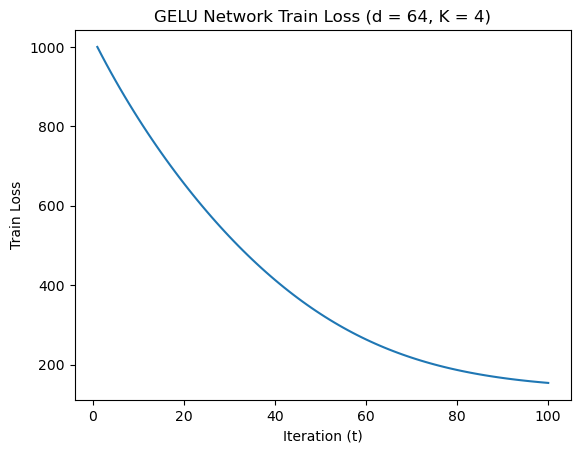

=== TRIAL 9 ===
Initializing weights using orthogonal method with scale 0.01


  0%|          | 0/100 [00:00<?, ?it/s]2026-10-15 13:49:12,516 - INFO - Finish Epoch 1
2026-10-15 13:49:12,517 - INFO - Train loss: 1000.985595703125, train accuracy: 29.9
2026-10-15 13:49:12,524 - INFO - Val loss: 980.5362548828125, val accuracy: 98.9
2026-10-15 13:49:12,532 - INFO - Finish Epoch 2
2026-10-15 13:49:12,533 - INFO - Train loss: 980.5362548828125, train accuracy: 98.9
2026-10-15 13:49:12,539 - INFO - Val loss: 949.7261962890625, val accuracy: 99.0
2026-10-15 13:49:12,547 - INFO - Finish Epoch 3
2026-10-15 13:49:12,548 - INFO - Train loss: 949.7261962890625, train accuracy: 99.0
2026-10-15 13:49:12,554 - INFO - Val loss: 917.51806640625, val accuracy: 99.0
2026-10-15 13:49:12,562 - INFO - Finish Epoch 4
2026-10-15 13:49:12,563 - INFO - Train loss: 917.51806640625, train accuracy: 99.0
2026-10-15 13:49:12,569 - INFO - Val loss: 886.37158203125, val accuracy: 99.1
2026-10-15 13:49:12,577 - INFO - Finish Epoch 5
2026-10-15 13:49:12,578 - INFO - Train loss: 886.37158203125, t

2026-10-15 13:49:13,076 - INFO - Finish Epoch 38
2026-10-15 13:49:13,077 - INFO - Train loss: 229.36154174804688, train accuracy: 99.8
2026-10-15 13:49:13,084 - INFO - Val loss: 219.46473693847656, val accuracy: 99.8
2026-10-15 13:49:13,091 - INFO - Finish Epoch 39
2026-10-15 13:49:13,092 - INFO - Train loss: 219.46473693847656, train accuracy: 99.8
2026-10-15 13:49:13,099 - INFO - Val loss: 210.13748168945312, val accuracy: 99.8
2026-10-15 13:49:13,106 - INFO - Finish Epoch 40
2026-10-15 13:49:13,107 - INFO - Train loss: 210.13748168945312, train accuracy: 99.8
2026-10-15 13:49:13,114 - INFO - Val loss: 201.36328125, val accuracy: 99.8
2026-10-15 13:49:13,121 - INFO - Finish Epoch 41
2026-10-15 13:49:13,122 - INFO - Train loss: 201.36328125, train accuracy: 99.8
2026-10-15 13:49:13,129 - INFO - Val loss: 193.12347412109375, val accuracy: 99.8
2026-10-15 13:49:13,136 - INFO - Finish Epoch 42
2026-10-15 13:49:13,137 - INFO - Train loss: 193.12347412109375, train accuracy: 99.8
2026-10-1

2026-10-15 13:49:13,777 - INFO - Finish Epoch 75
2026-10-15 13:49:13,778 - INFO - Train loss: 91.97569274902344, train accuracy: 99.9
2026-10-15 13:49:13,784 - INFO - Val loss: 91.22804260253906, val accuracy: 99.9
2026-10-15 13:49:13,792 - INFO - Finish Epoch 76
2026-10-15 13:49:13,793 - INFO - Train loss: 91.22804260253906, train accuracy: 99.9
2026-10-15 13:49:13,799 - INFO - Val loss: 90.52224731445312, val accuracy: 99.9
2026-10-15 13:49:13,807 - INFO - Finish Epoch 77
2026-10-15 13:49:13,808 - INFO - Train loss: 90.52224731445312, train accuracy: 99.9
2026-10-15 13:49:13,814 - INFO - Val loss: 89.85517883300781, val accuracy: 99.9
 77%|███████▋  | 77/100 [00:01<00:00, 55.13it/s]2026-10-15 13:49:13,823 - INFO - Finish Epoch 78
2026-10-15 13:49:13,824 - INFO - Train loss: 89.85517883300781, train accuracy: 99.9
2026-10-15 13:49:13,830 - INFO - Val loss: 89.2239990234375, val accuracy: 99.9
2026-10-15 13:49:13,838 - INFO - Finish Epoch 79
2026-10-15 13:49:13,839 - INFO - Train loss:

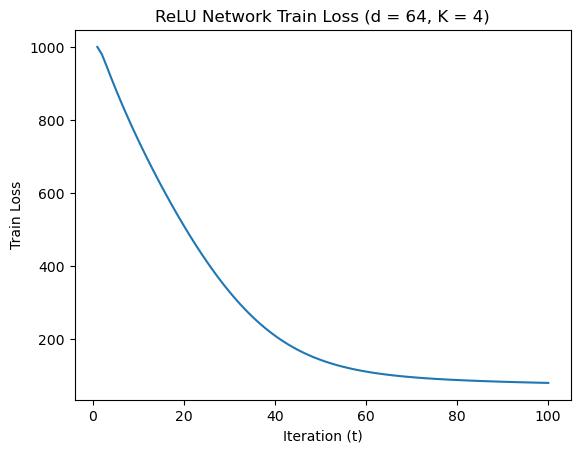

=== TRIAL 9 ===
Initializing weights using orthogonal method with scale 0.01


  0%|          | 0/100 [00:00<?, ?it/s]2026-10-15 13:49:14,318 - INFO - Finish Epoch 1
2026-10-15 13:49:14,319 - INFO - Train loss: 999.96923828125, train accuracy: 23.6
2026-10-15 13:49:14,326 - INFO - Val loss: 980.3600463867188, val accuracy: 99.5
2026-10-15 13:49:14,333 - INFO - Finish Epoch 2
2026-10-15 13:49:14,334 - INFO - Train loss: 980.3600463867188, train accuracy: 99.5
2026-10-15 13:49:14,341 - INFO - Val loss: 961.2260131835938, val accuracy: 99.8
2026-10-15 13:49:14,348 - INFO - Finish Epoch 3
2026-10-15 13:49:14,349 - INFO - Train loss: 961.2260131835938, train accuracy: 99.8
2026-10-15 13:49:14,356 - INFO - Val loss: 942.554931640625, val accuracy: 99.8
2026-10-15 13:49:14,363 - INFO - Finish Epoch 4
2026-10-15 13:49:14,364 - INFO - Train loss: 942.554931640625, train accuracy: 99.8
2026-10-15 13:49:14,371 - INFO - Val loss: 924.3349609375, val accuracy: 99.8
2026-10-15 13:49:14,378 - INFO - Finish Epoch 5
2026-10-15 13:49:14,379 - INFO - Train loss: 924.3349609375, tra

2026-10-15 13:49:14,881 - INFO - Train loss: 514.51953125, train accuracy: 99.8
2026-10-15 13:49:14,888 - INFO - Val loss: 506.42529296875, val accuracy: 99.8
2026-10-15 13:49:14,895 - INFO - Finish Epoch 39
2026-10-15 13:49:14,896 - INFO - Train loss: 506.42529296875, train accuracy: 99.8
2026-10-15 13:49:14,903 - INFO - Val loss: 498.517333984375, val accuracy: 99.8
2026-10-15 13:49:14,910 - INFO - Finish Epoch 40
2026-10-15 13:49:14,911 - INFO - Train loss: 498.517333984375, train accuracy: 99.8
2026-10-15 13:49:14,918 - INFO - Val loss: 490.791015625, val accuracy: 99.8
2026-10-15 13:49:14,925 - INFO - Finish Epoch 41
2026-10-15 13:49:14,926 - INFO - Train loss: 490.791015625, train accuracy: 99.8
2026-10-15 13:49:14,933 - INFO - Val loss: 483.241943359375, val accuracy: 99.8
2026-10-15 13:49:14,940 - INFO - Finish Epoch 42
2026-10-15 13:49:14,941 - INFO - Train loss: 483.241943359375, train accuracy: 99.8
2026-10-15 13:49:14,948 - INFO - Val loss: 475.86578369140625, val accuracy:

2026-10-15 13:49:15,448 - INFO - Val loss: 306.75726318359375, val accuracy: 99.8
2026-10-15 13:49:15,455 - INFO - Finish Epoch 76
2026-10-15 13:49:15,456 - INFO - Train loss: 306.75726318359375, train accuracy: 99.8
2026-10-15 13:49:15,463 - INFO - Val loss: 303.3346862792969, val accuracy: 99.8
2026-10-15 13:49:15,470 - INFO - Finish Epoch 77
2026-10-15 13:49:15,471 - INFO - Train loss: 303.3346862792969, train accuracy: 99.8
2026-10-15 13:49:15,478 - INFO - Val loss: 299.986572265625, val accuracy: 99.8
 77%|███████▋  | 77/100 [00:01<00:00, 66.01it/s]2026-10-15 13:49:15,486 - INFO - Finish Epoch 78
2026-10-15 13:49:15,487 - INFO - Train loss: 299.986572265625, train accuracy: 99.8
2026-10-15 13:49:15,494 - INFO - Val loss: 296.711181640625, val accuracy: 99.8
2026-10-15 13:49:15,501 - INFO - Finish Epoch 79
2026-10-15 13:49:15,502 - INFO - Train loss: 296.711181640625, train accuracy: 99.8
2026-10-15 13:49:15,509 - INFO - Val loss: 293.5068359375, val accuracy: 99.8
2026-10-15 13:49

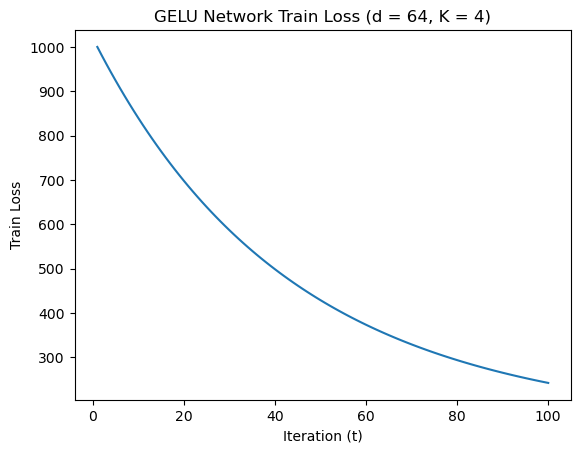

=== TRIAL 9 ===
Initializing weights using orthogonal method with scale 0.01


  0%|          | 0/100 [00:00<?, ?it/s]2026-10-15 13:49:15,992 - INFO - Finish Epoch 1
2026-10-15 13:49:15,993 - INFO - Train loss: 999.8475341796875, train accuracy: 24.1
2026-10-15 13:49:16,000 - INFO - Val loss: 974.821533203125, val accuracy: 99.5
2026-10-15 13:49:16,008 - INFO - Finish Epoch 2
2026-10-15 13:49:16,009 - INFO - Train loss: 974.821533203125, train accuracy: 99.5
2026-10-15 13:49:16,015 - INFO - Val loss: 937.5747680664062, val accuracy: 99.7
2026-10-15 13:49:16,023 - INFO - Finish Epoch 3
2026-10-15 13:49:16,024 - INFO - Train loss: 937.5747680664062, train accuracy: 99.7
2026-10-15 13:49:16,030 - INFO - Val loss: 898.4987182617188, val accuracy: 99.7
2026-10-15 13:49:16,037 - INFO - Finish Epoch 4
2026-10-15 13:49:16,039 - INFO - Train loss: 898.4987182617188, train accuracy: 99.7
2026-10-15 13:49:16,045 - INFO - Val loss: 861.077392578125, val accuracy: 99.7
2026-10-15 13:49:16,052 - INFO - Finish Epoch 5
2026-10-15 13:49:16,053 - INFO - Train loss: 861.07739257812

2026-10-15 13:49:16,551 - INFO - Train loss: 281.22857666015625, train accuracy: 99.9
2026-10-15 13:49:16,557 - INFO - Val loss: 274.2820739746094, val accuracy: 99.9
2026-10-15 13:49:16,564 - INFO - Finish Epoch 39
2026-10-15 13:49:16,566 - INFO - Train loss: 274.2820739746094, train accuracy: 99.9
2026-10-15 13:49:16,572 - INFO - Val loss: 267.63897705078125, val accuracy: 99.9
2026-10-15 13:49:16,579 - INFO - Finish Epoch 40
2026-10-15 13:49:16,581 - INFO - Train loss: 267.63897705078125, train accuracy: 99.9
2026-10-15 13:49:16,587 - INFO - Val loss: 261.2839050292969, val accuracy: 99.9
2026-10-15 13:49:16,594 - INFO - Finish Epoch 41
2026-10-15 13:49:16,595 - INFO - Train loss: 261.2839050292969, train accuracy: 99.9
2026-10-15 13:49:16,602 - INFO - Val loss: 255.203125, val accuracy: 99.9
2026-10-15 13:49:16,609 - INFO - Finish Epoch 42
2026-10-15 13:49:16,610 - INFO - Train loss: 255.203125, train accuracy: 99.9
2026-10-15 13:49:16,617 - INFO - Val loss: 249.3827667236328, val 

2026-10-15 13:49:17,108 - INFO - Finish Epoch 75
2026-10-15 13:49:17,109 - INFO - Train loss: 147.15164184570312, train accuracy: 100.0
2026-10-15 13:49:17,115 - INFO - Val loss: 145.51129150390625, val accuracy: 100.0
2026-10-15 13:49:17,123 - INFO - Finish Epoch 76
2026-10-15 13:49:17,124 - INFO - Train loss: 145.51129150390625, train accuracy: 100.0
2026-10-15 13:49:17,130 - INFO - Val loss: 143.92449951171875, val accuracy: 100.0
2026-10-15 13:49:17,137 - INFO - Finish Epoch 77
2026-10-15 13:49:17,139 - INFO - Train loss: 143.92449951171875, train accuracy: 100.0
2026-10-15 13:49:17,145 - INFO - Val loss: 142.38865661621094, val accuracy: 100.0
 77%|███████▋  | 77/100 [00:01<00:00, 66.32it/s]2026-10-15 13:49:17,153 - INFO - Finish Epoch 78
2026-10-15 13:49:17,155 - INFO - Train loss: 142.38865661621094, train accuracy: 100.0
2026-10-15 13:49:17,161 - INFO - Val loss: 140.90135192871094, val accuracy: 100.0
2026-10-15 13:49:17,168 - INFO - Finish Epoch 79
2026-10-15 13:49:17,169 - I

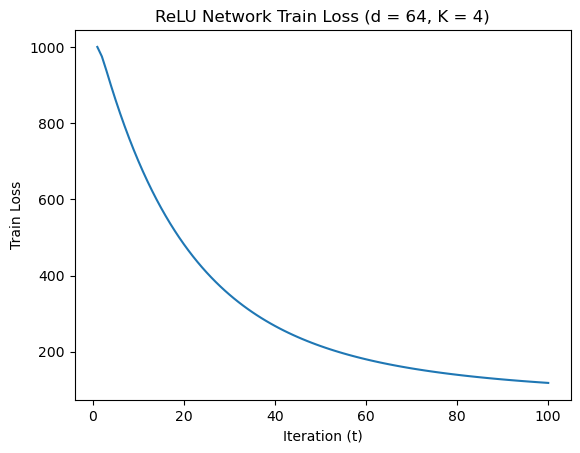

In [11]:
trials = 10

weight_decomp_norms = np.zeros((trials, len(act_fn_strs), 2, epochs - 1, 4))
weight_decomp_dists = np.zeros((trials, len(act_fn_strs), 2, epochs - 1, 4))


train_losses = np.zeros((trials, len(act_fn_strs), 2, epochs))

nonlin_comps = np.zeros((trials, len(act_fn_strs), 2, epochs))

for i in range(trials):
    for k in range(2):
        freeze_last_layer = (k == 1) # k = 0 --> False --> train W2, k = 1 --> True --> fix W2
        for j, act_fn_str in enumerate(act_fn_strs):
            
            # Create data
            train_loader, val_loader, X, Y = get_data(d, K, N_k, scale, nu, normalize_, orthogonalize_, whiten_)

            print("=== TRIAL " + str(i) + " ===")

            # Train model
            weights, grads, outs, train_losses_trial = train_model(L, d, m, K, act_fn_str, 
                                                             train_loader, 
                                                             val_loader, 
                                                             epochs, 
                                                             lr, 
                                                             freq, 
                                                             loss_fn, 
                                                             optimizer_type=optimizer_type,
                                                             freeze_last_layer=freeze_last_layer,
                                                             residual=residual,
                                                             batchnorm=batchnorm,
                                                             init_method=init_method,
                                                             last_layer_init_method=last_layer_init_method,
                                                             init_scale=init_scale)

                            
            # Plot train loss
            plot_train_losses(train_losses_trial, act_fn_str, d, K, None, savefig=False)
            train_losses[i, j, k, :] = train_losses_trial

            # Calculate norms of decompositions
            trial_decomp_norms, trial_decomp_dists = weight_decomp_norms_dists(weights, grads, K, init_scale, epochs)


            weight_decomp_norms[i, j, k, ...] = trial_decomp_norms
            weight_decomp_dists[i, j, k, ...] = trial_decomp_dists

In [12]:
#print(np.mean(nonlin_comps, axis=0)[2, 0, :])

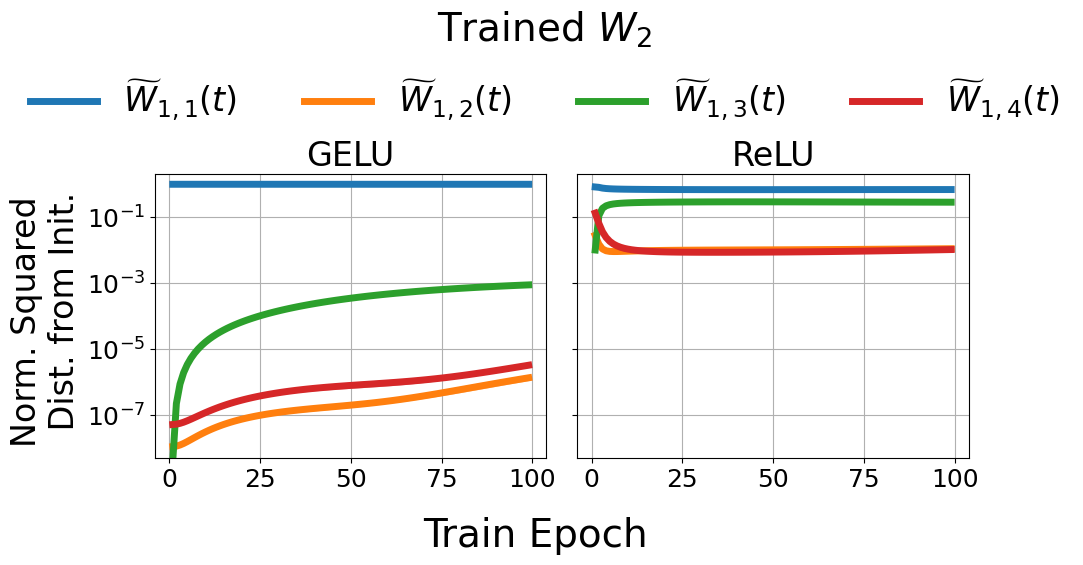

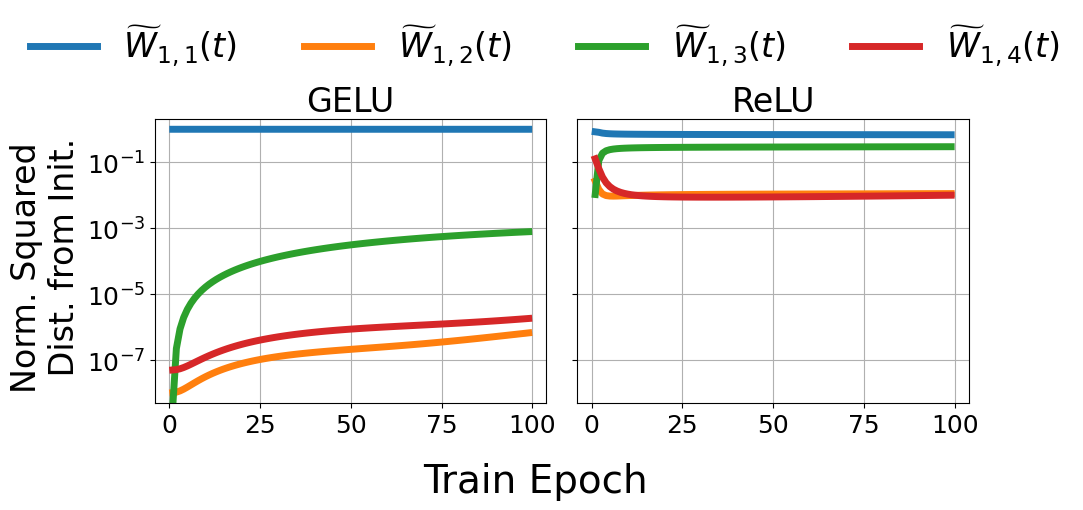

In [22]:
# Mean and stdev of weight decomposition norms across trials
mean_weight_decomp_dists = np.mean(weight_decomp_dists, axis=0)
std_weight_decomp_dists = np.std(weight_decomp_dists, axis=0)

mean_weight_decomp_norms = np.mean(weight_decomp_norms, axis=0)
std_weight_decomp_norms = np.std(weight_decomp_norms, axis=0)

x_range = np.arange(1, epochs)

for k in range(2):
    n_plots = len(act_fn_strs)
    fig, axes = plt.subplots(
        1,
        n_plots,
        figsize=(5 * n_plots, 5),
        sharey=True
    )

    # Make axes iterable even if n_plots == 1
    if n_plots == 1:
        axes = [axes]

    legend_handles = None
    legend_labels = None

    for i, act_fn_str in enumerate(act_fn_strs):
        ax = axes[i]

        for j in range(4):
            label = rf'$\widetilde{{W}}_{{1,{j+1}}}(t)$'

            line, = ax.plot(
                x_range,
                mean_weight_decomp_dists[i, k, :, j],
                linewidth=5,
                label=label
            )

            ax.fill_between(
                x_range,
                mean_weight_decomp_dists[i, k, :, j] - std_weight_decomp_dists[i, k, :, j],
                mean_weight_decomp_dists[i, k, :, j] + std_weight_decomp_dists[i, k, :, j],
                alpha=0.5
            )

            # Capture legend handles only once
            if legend_handles is None:
                legend_handles = []
                legend_labels = []

            if label not in legend_labels:
                legend_handles.append(line)
                legend_labels.append(label)

        ax.set_title(act_fn_str, fontsize=24)
        #ax.set_xlabel('Train Epoch', fontsize=24)
        ax.grid(True)
        ax.tick_params(axis='both', labelsize=18)

        ax.set_yscale('log')

    axes[0].set_ylim([10**-9, 2])
    axes[0].set_ylabel('Norm. Squared \n Dist. from Init.', fontsize=24)

    # Suptitle
    title = '' if whiten_ else 'Unwhitened Data'
    fig.suptitle(title, fontsize=28, y=1.0, x=0.525)
    fig.supxlabel('Train Epoch', fontsize=28, x=0.54)

    # Shared legend below suptitle
    fig.legend(
        legend_handles,
        legend_labels,
        loc='upper center',
        bbox_to_anchor=(0.55, 1.025),
        ncol=4,
        fontsize=24,
        frameon=False
    )

    plt.tight_layout(rect=[0, 0, 1, 0.9])
    
    suptitle = r'Trained $W_2$' if k == 0 else '' #r'Frozen $W_2$'
    plt.suptitle(suptitle, fontsize=28, x=0.55, y=1.1)

    savefig_dir = './figs/verify_theory/'
    os.makedirs(savefig_dir, exist_ok=True)

    #save_fname = 'network_verify_theory_decomp_distances'
    save_fname = 'network_gelu_vs_relu_decomp_distances'
    save_fname += '_trained_W2' if k == 0 else ''
    save_fname += '_unwhitened_data.pdf' if not whiten_ else '.pdf'

    if save:
        plt.savefig(os.path.join(savefig_dir, save_fname), bbox_inches='tight')

    plt.show()
    plt.close()


In [14]:
# # Plot loss
# mean_train_losses = np.mean(train_losses / N, axis=0)
# std_train_losses = np.std(train_losses / N, axis=0)

# x_range = np.arange(1, epochs + 1)


# n_plots = len(act_fn_strs)
# fig, axes = plt.subplots(
#     1,
#     n_plots,
#     figsize=(5 * n_plots, 5),
#     sharey=True
# )

# # Make axes iterable even if n_plots == 1
# if n_plots == 1:
#     axes = [axes]

# legend_handles = None
# legend_labels = None
# for i, act_fn_str in enumerate(act_fn_strs):
#     ax = axes[i]
#     for k in range(2):
#         label = r'Trained $W_2$' if k == 0 else r'Frozen $W_2$'

#         line, = ax.plot(
#             x_range,
#             mean_train_losses[i, k, :],
#             linewidth=5,
#             label=label
#         )

#         ax.fill_between(
#             x_range,
#             mean_train_losses[i, k, :] - std_train_losses[i, k, :],
#             mean_train_losses[i, k, :] + std_train_losses[i, k, :],
#             linewidth=5,
#             alpha=0.5
#         )

#         # Capture legend handles only once
#         if legend_handles is None:
#             legend_handles = []
#             legend_labels = []

#         if label not in legend_labels:
#             legend_handles.append(line)
#             legend_labels.append(label)

#         ax.set_title(act_fn_str, fontsize=24)
#         ax.grid(True)
#         ax.tick_params(axis='both', labelsize=18)

#     #axes[0].set_ylim([-0.1, 1.1])
#     axes[0].set_ylabel('Mean-Squared Error', fontsize=24)

# # Suptitle
# title = '' if whiten_ else 'Unwhitened Data'
# fig.suptitle(title, fontsize=28, y=1.0, x=0.525)
# fig.supxlabel('Train Epoch', fontsize=28, x=0.54)

# # Shared legend below suptitle
# fig.legend(
#     legend_handles,
#     legend_labels,
#     loc='upper center',
#     bbox_to_anchor=(0.525, 1.025),
#     ncol=4,
#     fontsize=24,
#     frameon=False
# )

# plt.tight_layout(rect=[0, 0, 1, 0.9])

# savefig_dir = './figs/verify_theory/'
# os.makedirs(savefig_dir, exist_ok=True)

# save_fname = 'network_verify_theory_losses'
# save_fname += '_unwhitened_data.pdf' if not whiten_ else '.pdf'

# if save:
#     plt.savefig(os.path.join(savefig_dir, save_fname), bbox_inches='tight')

# plt.show()
# plt.close()
